# Media Mix Modeling (MMM) Tutorial

This notebook demonstrates how to build and analyze a Marketing Mix Model using PyMC Marketing.

## Prepare Notebook

Let's import the necessary libraries:

In [1]:
import sys
sys.path.insert(0, ".")

import yaml
from pymc_marketing.mmm.mmm import MMM

# Load configuration from YAML file
with open("mmm_config.yml", "r") as f:
    config = yaml.safe_load(f)

print("Configuration loaded successfully!")
print(f"Data source: {config['data']['source']}")
print(f"Channel columns: {config['data']['columns']['channel_columns']}")
print(f"MCMC chains: {config['sampling']['mcmc']['chains']}")

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


Configuration loaded successfully!
Data source: https://raw.githubusercontent.com/pymc-labs/pymc-marketing/main/data/mmm_example.csv
Channel columns: ['x1', 'x2']
MCMC chains: 2


## Enhanced Logging

The MMM classes now include comprehensive logging to help you track the modeling process. Let's configure logging to see detailed information about what's happening during model operations:

In [2]:
# DEBUG: Check logging state before configuration
import logging
root = logging.getLogger()
print(f"=== BEFORE configuring logging ===")
print(f"Root logger handlers: {len(root.handlers)}")
print(f"Root handlers: {root.handlers}")
for i, handler in enumerate(root.handlers):
    print(f"  Handler {i}: {handler}")


=== BEFORE configuring logging ===
Root logger handlers: 0
Root handlers: []


In [3]:
# Configure logging using settings from config
import logging

# Get logging configuration from config
log_config = config['logging']

# Clear any existing root handlers to start fresh
# This is essential in Jupyter notebooks to prevent handler accumulation
root_logger = logging.getLogger()
if root_logger.hasHandlers():
    root_logger.handlers.clear()

# Apply base configuration to ROOT logger
logging.basicConfig(
    level=getattr(logging, log_config['level']),
    format=log_config['format'],
    datefmt=log_config['date_format']
)

# Configure the MMM logger level from config
# The MMM logger will propagate to root, so it will use the root handler
mmm_logger = logging.getLogger(log_config['mmm_logger']['name'])
mmm_logger.setLevel(getattr(logging, log_config['mmm_logger']['level']))

# Optionally quiet very chatty external loggers if needed
# Avoid duplicate/verbose logs from PyMC internal forward sampler
logging.getLogger("pymc.sampling.forward").propagate = False

print("Logging configured! Now all MMM operations will show detailed process information.")

Logging configured! Now all MMM operations will show detailed process information.


Now when you run the MMM operations below, you'll see detailed logging information including:

- **Model Initialization**: Input parameters, configuration details
- **Data Preprocessing**: Data shapes, statistics, date ranges  
- **Model Building**: Variables created, model coordinates, scaling factors
- **Prior/Posterior Sampling**: Input parameters, output shapes, variable lists
- **Model Fitting**: Fit parameters, inference data groups

This logging helps with debugging, monitoring, and understanding what the model is doing at each step.

In [4]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymc_extras.prior import Prior
import jax 
import pytensor 
from pymc_marketing.mmm.components.adstock import GeometricAdstock
from pymc_marketing.mmm.components.saturation import LogisticSaturation
from pymc_marketing.mmm.components.adstock import NoAdstock
from pymc_marketing.mmm.components.saturation import NoSaturation

import numpyro 

# Apply visualization configuration from config file
viz_config = config['visualization']
az.style.use(viz_config['style'])
plt.rcParams["figure.figsize"] = viz_config['figure']['figsize']
plt.rcParams["figure.dpi"] = viz_config['figure']['dpi']

%config InlineBackend.figure_format = viz_config['backend']['format']

%load_ext autoreload
%autoreload 2

c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# Set random seed for reproducibility from config
seed = config['sampling']['random_seed']
rng = np.random.default_rng(seed=seed)
print(f"Random seed set to: {seed}")

Random seed set to: 327


## Load Data

We'll use a synthetic dataset that simulates weekly sales data along with spend on two marketing channels (x1 and x2), plus some control variables for special events.

In [6]:
# Load the data from config-specified source
data_config = config['data']
url = data_config['source']
data = pd.read_csv(url, parse_dates=[data_config['columns']['date_column']])

# Multiply x1 and x2 by 100
data['x1'] = data['x1'] * 100
data['x2'] = data['x2'] * 100

print(f"Data shape: {data.shape}")
data.head()

Data shape: (179, 8)


,date_week,y,x1,x2,event_1,event_2,dayofyear,t
0,2018-04-02,3984.662237,31.858002,0.0,0.0,0.0,92,0
1,2018-04-09,3762.871794,11.238848,0.0,0.0,0.0,99,1
2,2018-04-16,4466.967388,29.240027,0.0,0.0,0.0,106,2
3,2018-04-23,3864.219373,7.139855,0.0,0.0,0.0,113,3
4,2018-04-30,4441.625278,38.674515,0.0,0.0,0.0,120,4


Let's visualize our target variable (sales) and the media spend over time:

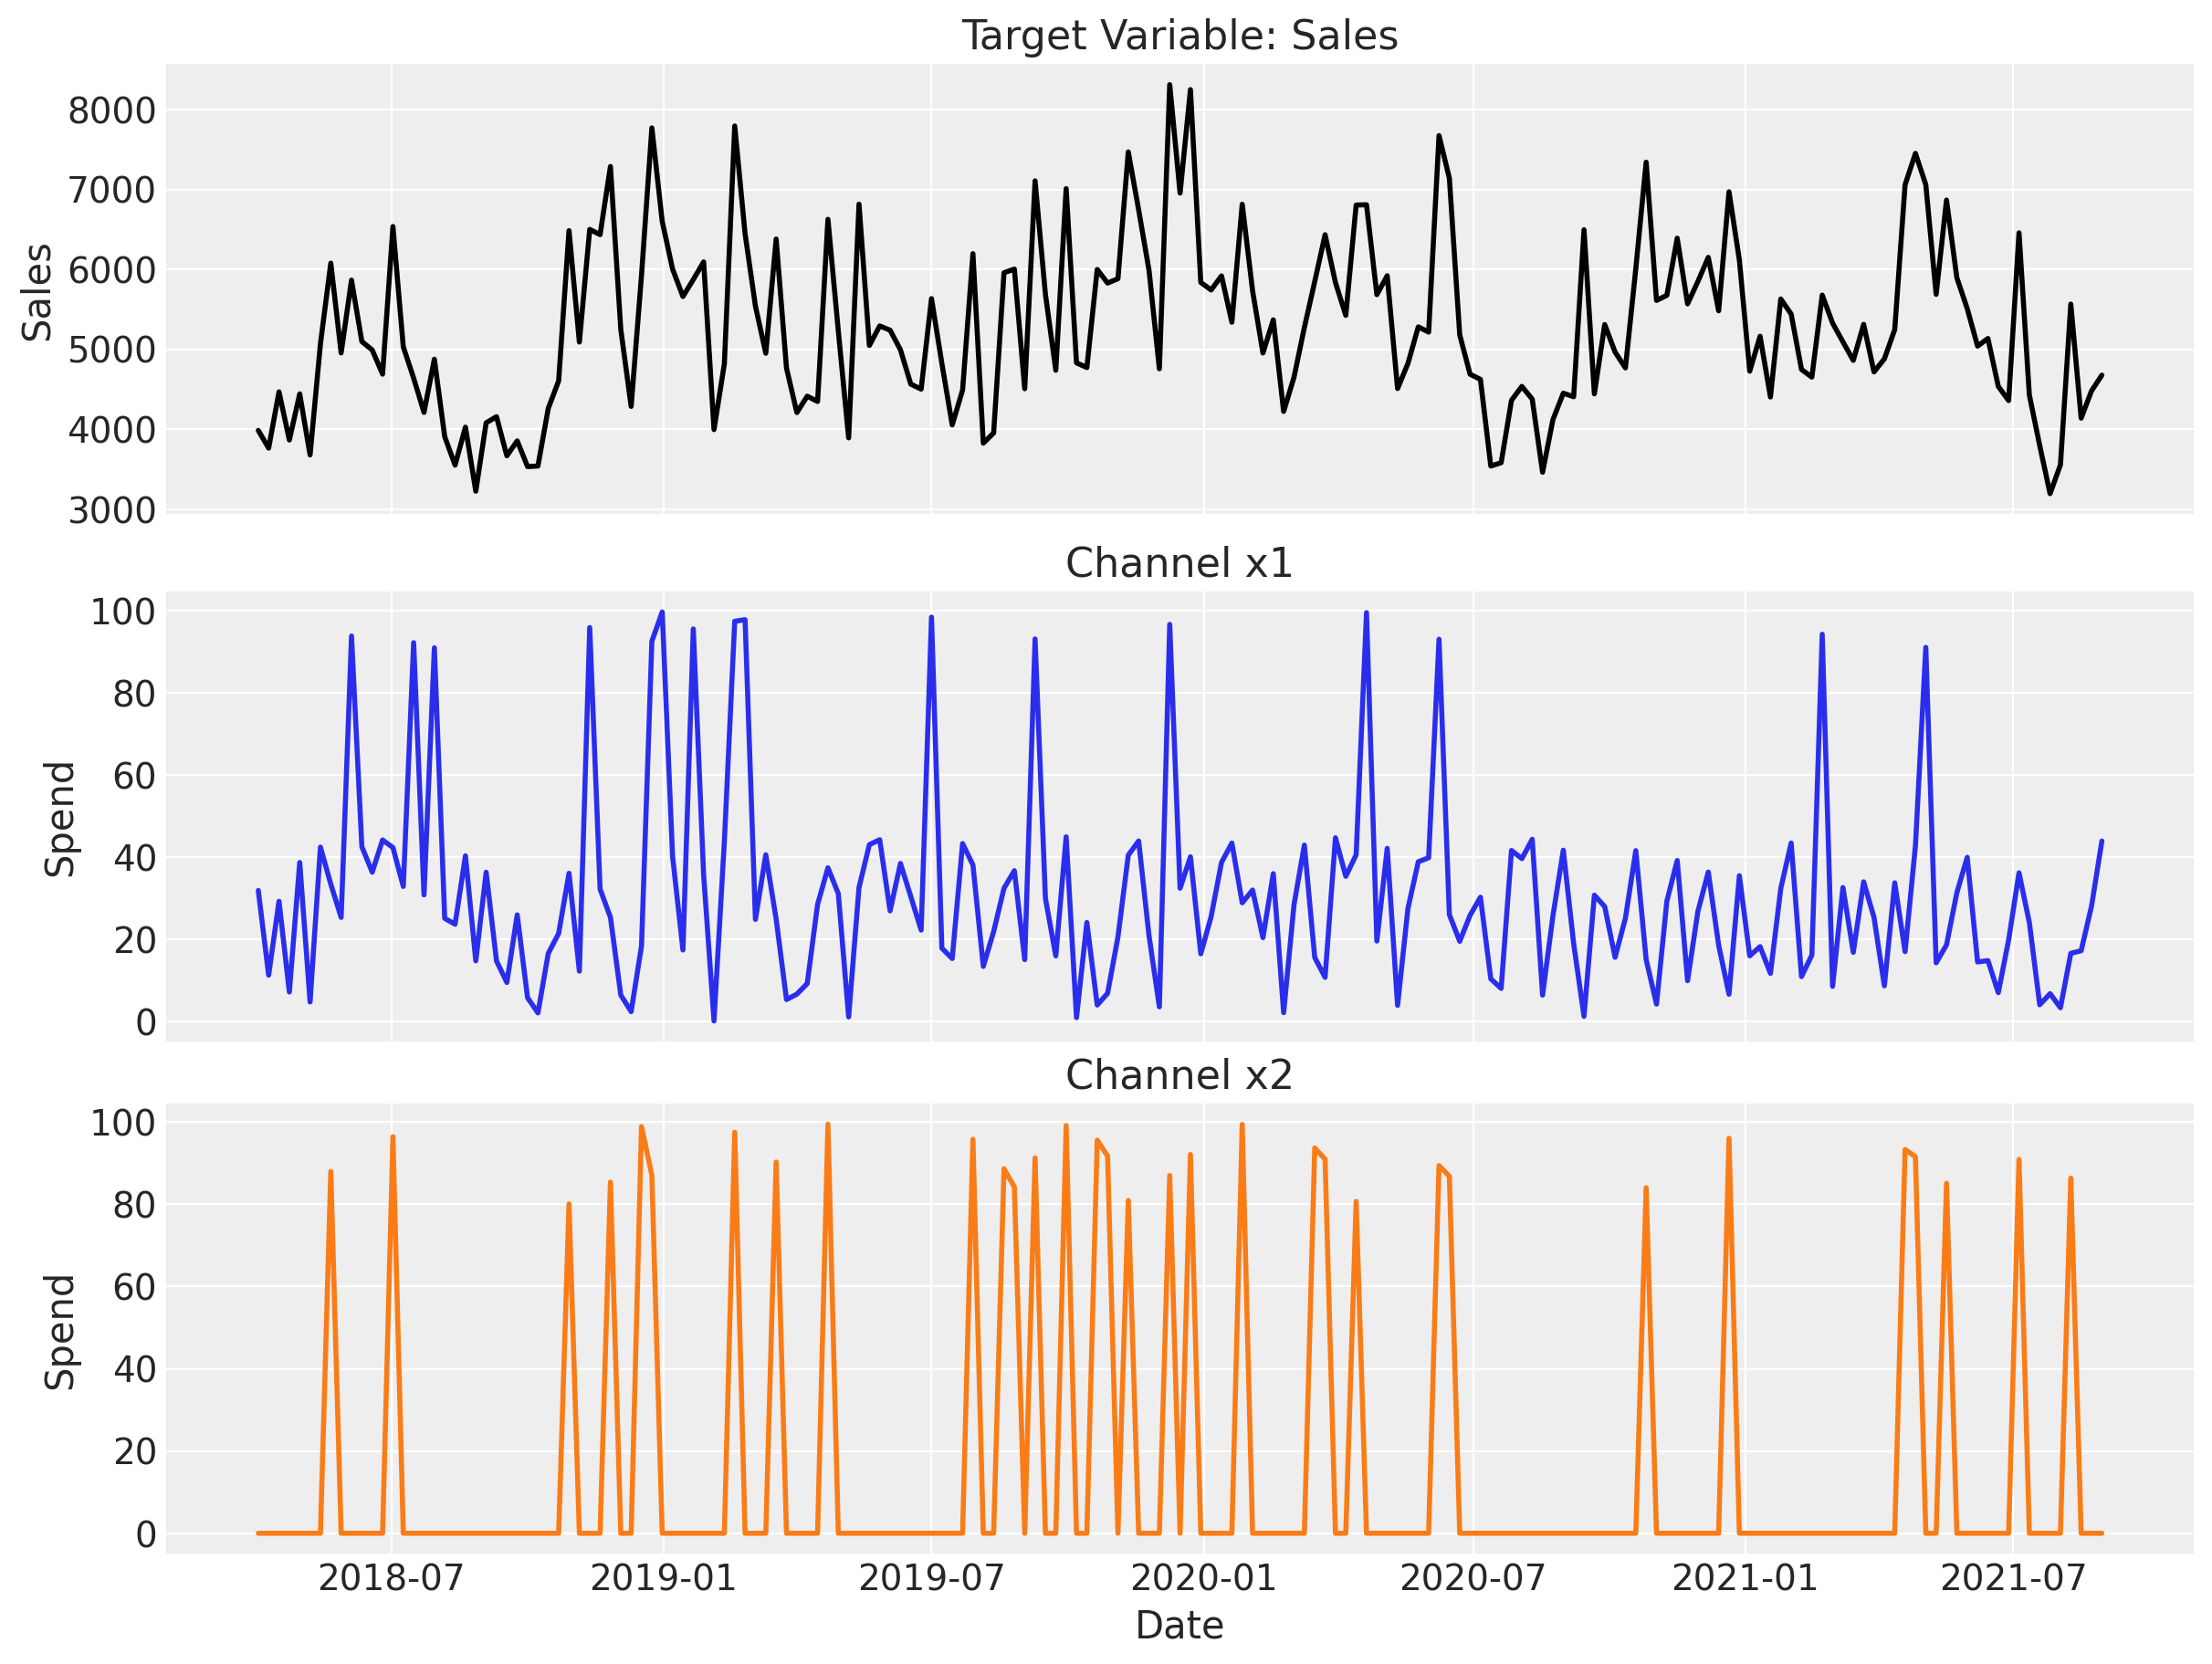

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Get column names from config
date_col = config['data']['columns']['date_column']
target_col = config['data']['columns']['target_column']
channel_cols = config['data']['columns']['channel_columns']

# Sales
axes[0].plot(data[date_col], data[target_col], color="black", linewidth=2)
axes[0].set(ylabel="Sales", title="Target Variable: Sales")

# Channel 1
axes[1].plot(data[date_col], data[channel_cols[0]], color="C0", linewidth=2)
axes[1].set(ylabel="Spend", title=f"Channel {channel_cols[0]}")

# Channel 2
axes[2].plot(data[date_col], data[channel_cols[1]], color="C1", linewidth=2)
axes[2].set(xlabel="Date", ylabel="Spend", title=f"Channel {channel_cols[1]}");

## Feature Engineering

For our MMM model, we'll include:

- **Trend**: A linear trend to capture long-term growth
- **Seasonality**: Yearly seasonality (handled automatically by the model)
- **Events**: Binary indicators for special events
- **Media channels**: Our two advertising channels

In [8]:
# Add a simple linear trend feature
data["t"] = range(len(data))

# Split into features (X) and target (y) using config
target_col = config['data']['columns']['target_column']
X = data.drop(target_col, axis=1)
y = data[target_col]

print(f"Features: {X.columns.tolist()}")

Features: ['date_week', 'x1', 'x2', 'event_1', 'event_2', 'dayofyear', 't']


## Model Specification

Now we'll configure our MMM model. The key components are:

- **Adstock transformation**: We use GeometricAdstock with a maximum lag of 8 weeks
- **Saturation transformation**: We use LogisticSaturation to capture diminishing returns
- **Priors**: We can customize priors based on domain knowledge

### Setting Priors

One powerful feature of Bayesian modeling is the ability to incorporate prior knowledge. Here's a simple heuristic for channel priors based on spend share:

In [9]:
# Calculate spend share for each channel
channel_cols = config['data']['columns']['channel_columns']
total_spend_per_channel = data[channel_cols].sum(axis=0)
spend_share = total_spend_per_channel / total_spend_per_channel.sum()

print("Spend share per channel:")
print(spend_share)

# Use spend share to inform prior on channel contributions
# Only if configured to use spend-share informed priors
if config['priors']['use_spend_share_priors']:
    n_channels = config['priors']['spend_share_multiplier']
    prior_sigma = n_channels * spend_share.to_numpy()
    print(f"\nPrior sigma for channels: {prior_sigma}")
else:
    # Use default uniform priors
    prior_sigma = None
    print("\nUsing default priors (not spend-share informed)")

Spend share per channel:
x1    0.65632
x2    0.34368
dtype: float64

Prior sigma for channels: [1.31263903 0.68736097]


Now let's define our model configuration:

In [10]:
# Build model configuration from config file
prior_config = config['priors']

# Build the model_config dictionary
my_model_config = {
    "intercept": Prior(
        prior_config['intercept']['distribution'],
        mu=prior_config['intercept']['mu'],
        sigma=prior_config['intercept']['sigma']
    ),
    "gamma_control": Prior(
        prior_config['gamma_control']['distribution'],
        mu=prior_config['gamma_control']['mu'],
        sigma=prior_config['gamma_control']['sigma']
    ),
    "gamma_fourier": Prior(
        prior_config['gamma_fourier']['distribution'],
        mu=prior_config['gamma_fourier']['mu'],
        b=prior_config['gamma_fourier']['b']
    ),
    "likelihood": Prior(
        prior_config['likelihood']['distribution'],
        sigma=Prior(
            prior_config['likelihood']['sigma']['distribution'],
            sigma=prior_config['likelihood']['sigma']['sigma']
        )
    ),
}

# Add saturation_beta prior if using spend-share informed priors
if prior_sigma is not None:
    my_model_config["saturation_beta"] = Prior("HalfNormal", sigma=prior_sigma)

# Sampler configuration
my_sampler_config = {"progressbar": config['sampling']['progressbar']}

# Get model configuration
model_config = config['model']
adstock_config = model_config['adstock']
saturation_config = model_config['saturation']

# Initialize the MMM model with configuration
mmm = MMM(
    model_config=my_model_config,
    sampler_config=my_sampler_config,
    date_column=config['data']['columns']['date_column'],
    adstock=GeometricAdstock(l_max=adstock_config['l_max']),
    saturation= NoSaturation(),
    apply_scaling=False,
    channel_columns=config['data']['columns']['channel_columns'],
    control_columns=config['data']['columns']['control_columns'],
    yearly_seasonality=model_config['seasonality']['yearly_seasonality'],
    fit_intercept= True,
    log_transform_vars=['target', 'channels']




)

2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Initializing BaseMMM model
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - date_column: date_week
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - channel_columns: ['x1', 'x2']
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - adstock: GeometricAdstock
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - saturation: NoSaturation
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - time_varying_intercept: False
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - time_varying_media: False
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - control_columns: ['event_1', 'event_2', 't']
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - yearly_seasonality: 2
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input paramete

## Prior Predictive Check

> **Tip**: The prior predictive check is a good way to check that our priors are reasonable. Hence, it is strongly recommended to perform this check before fitting the model. If you are new to Bayesian modeling, take a look into our Prior Predictive Modeling guide notebook.

Before fitting, let's check that our priors are reasonable:

In [11]:
# Sanity check: verify logger handlers before prior predictive
import logging

print("=== Logger state before prior predictive ===")
root = logging.getLogger()
print(f"Root handlers: {len(root.handlers)} -> {root.handlers}")

# Show relevant package loggers
for name in sorted([n for n in logging.root.manager.loggerDict.keys() if str(n).startswith("pymc_marketing")]):
    lg = logging.getLogger(name)
    # Some entries in loggerDict are PlaceHolder; only print real Loggers
    if isinstance(lg, logging.Logger):
        print(f"{name}: level={logging.getLevelName(lg.level)}, handlers={len(lg.handlers)}, propagate={lg.propagate}")


=== Logger state before prior predictive ===
Root handlers: 1 -> [<StreamHandler stderr (NOTSET)>]
pymc_marketing: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm.mmm: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm.mmm.MMM: level=DEBUG, handlers=0, propagate=True


2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - ============================================================
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - PRIOR PREDICTIVE SAMPLING
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - ============================================================
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - y shape: (179,)
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - samples: 300, extend_idata: True, combined: True
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - 
Note: Scaling factors not yet computed (model may not be built)
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Starting PyMC model building
2025-11-14 14:44:38 - pymc_marketing.mmm.mmm.MMM - INFO - Model building input data shapes - X: (179, 7), y: (179,)
2025-11-14 14:44:38 - pymc_marketing.m

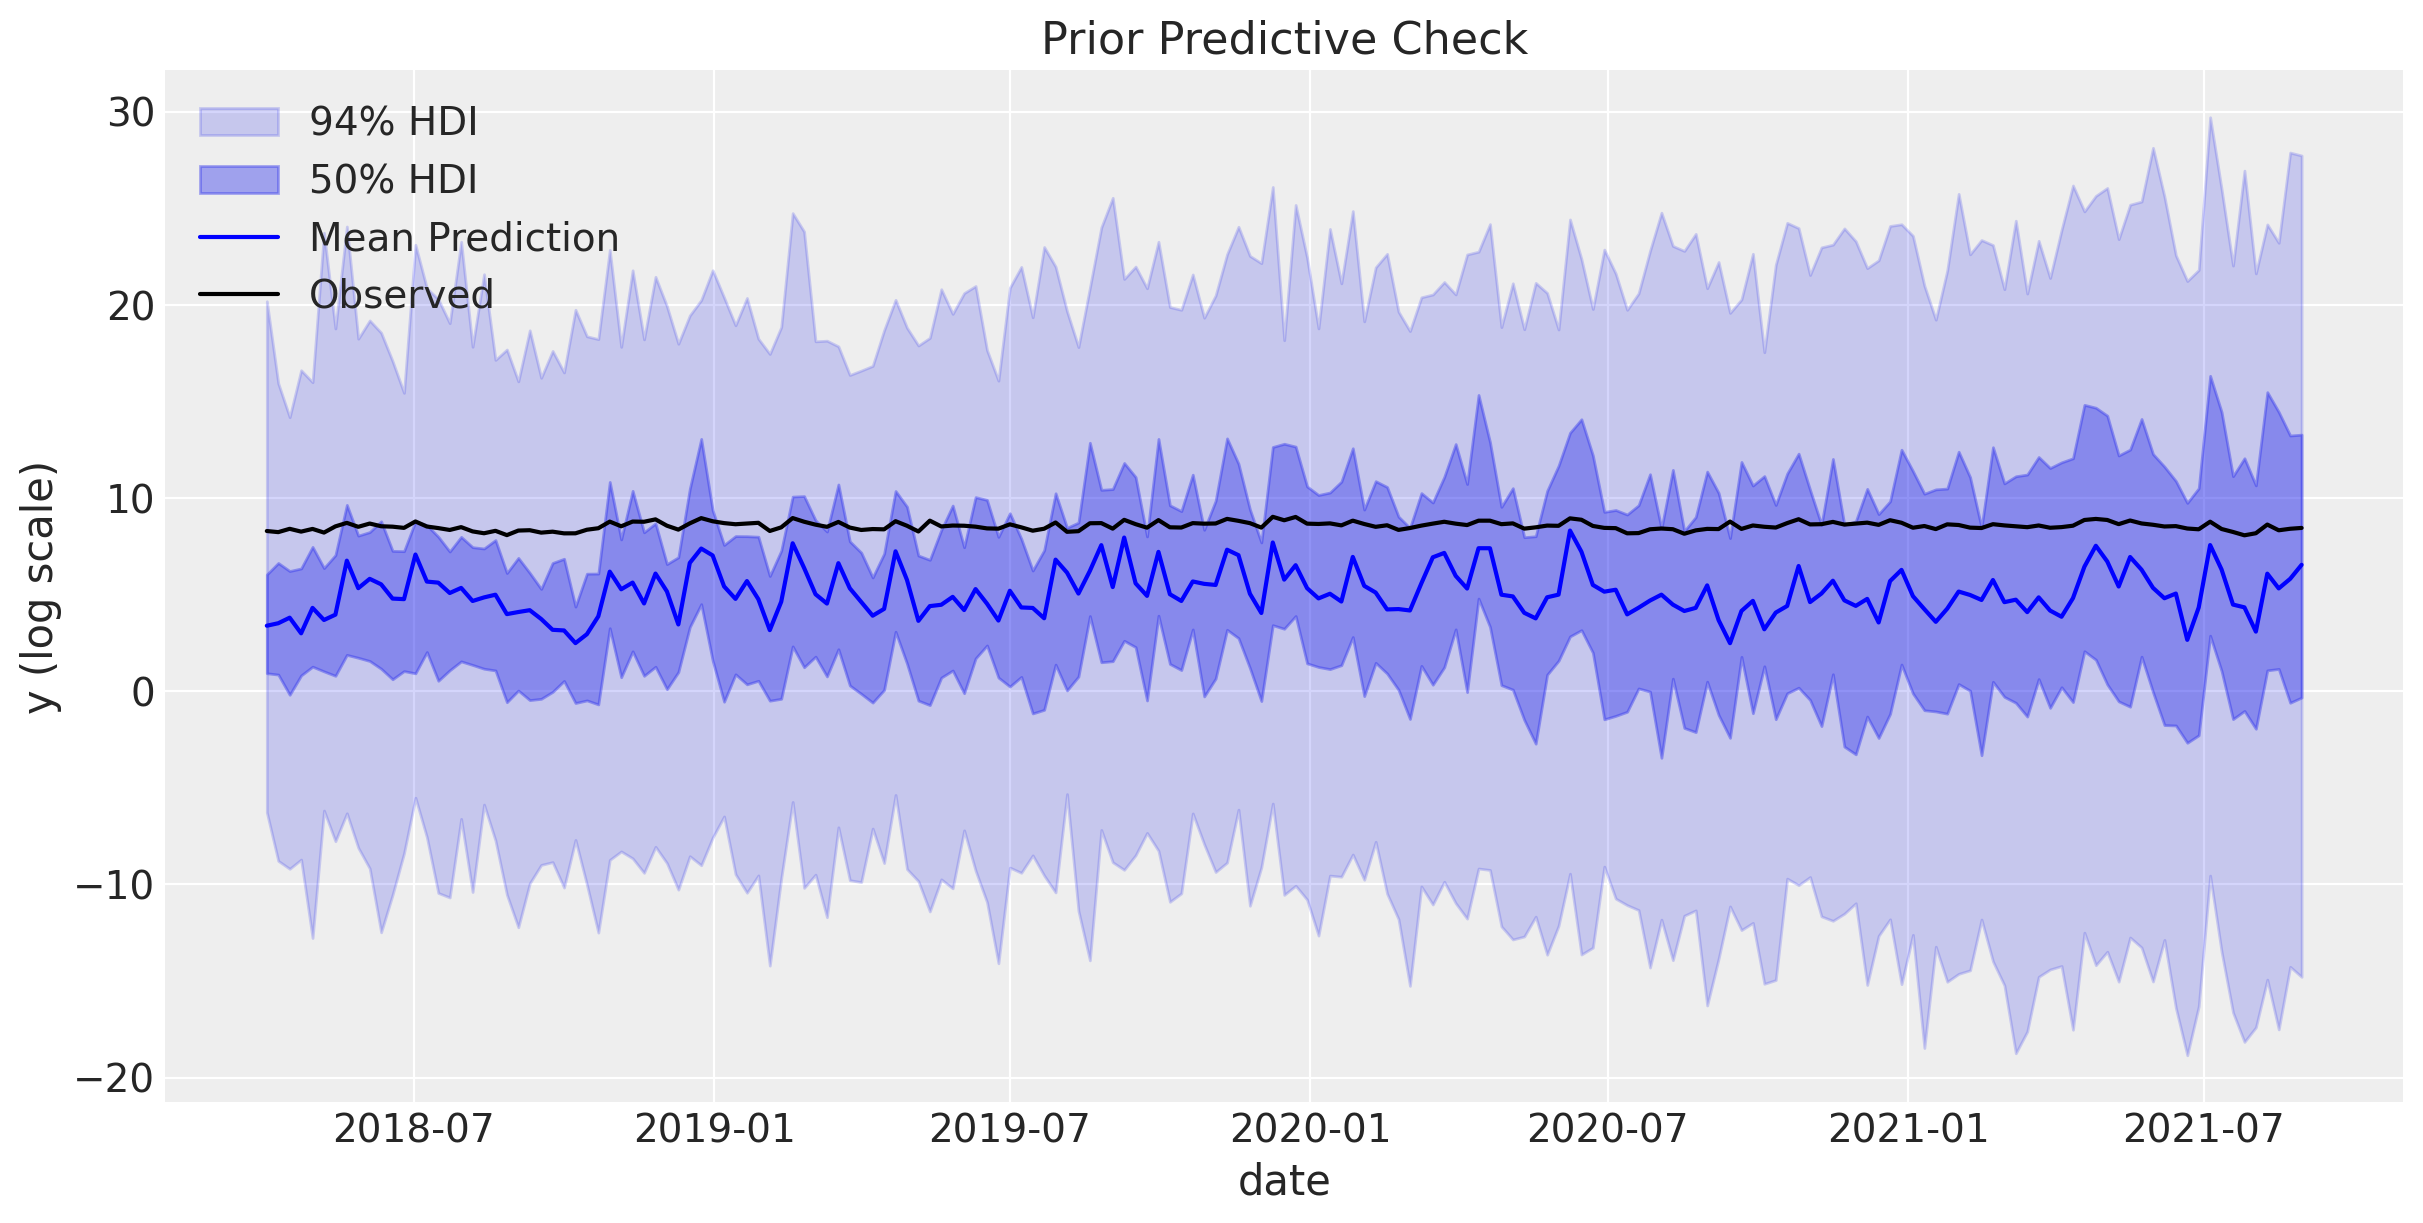

In [12]:
# Generate prior predictive samples using config
prior_samples = config['sampling']['prior_predictive']['samples']
mmm.sample_prior_predictive(X, y, samples=prior_samples, random_seed=rng)

# Plot prior predictive distribution
fig, ax = plt.subplots(figsize=(12, 6))
mmm.plot_prior_predictive(ax=ax, original_scale=False)
ax.legend(loc="upper left")
ax.set_title("Prior Predictive Check");

Overall, the prior predictive check looks good.

## Model Fitting

Now let's fit the model to our data using MCMC sampling. Observe that we can use different samplers by passing the `nuts_sampler` argument. For instance, we can use `numpyro`, `nutpie`, or `blackjax` samplers (see Other NUTS Samplers for more details).

In [13]:
# Fit the model using MCMC configuration from config file
mcmc_config = config['sampling']['mcmc']

_ = mmm.fit(
    X=X,
    y=y,
    chains=mcmc_config['chains'],
    target_accept=mcmc_config['target_accept'],
    nuts_sampler=mcmc_config['nuts_sampler'],
    random_seed=rng,
)

2025-11-14 14:44:47 - pymc_marketing.mmm.mmm.MMM - INFO - Starting model fitting
2025-11-14 14:44:47 - pymc_marketing.mmm.mmm.MMM - INFO - Fit input data shapes - X: (179, 7), y: (179,)
2025-11-14 14:44:47 - pymc_marketing.mmm.mmm.MMM - INFO - Fit parameters - progressbar: None, random_seed: Generator(PCG64)
2025-11-14 14:44:47 - pymc_marketing.mmm.mmm.MMM - INFO - Additional kwargs: ['chains', 'target_accept', 'nuts_sampler']
INFO:2025-11-14 14:44:48,183:jax._src.xla_bridge:822: Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.
2025-11-14 14:44:48 - jax._src.xla_bridge - INFO - Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.
Running chain 1: 100%|██████████| 2000/2000 [00:03<00:00, 595.32it/s] 
We recommend running at least 4 chains for robust computation of convergence diagnostics
2025-11-14 14:44:53 - pymc.stats.convergence - INFO - We recommend running at least 4 chains for robus

c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:45:38 - pymc_marketing.mmm.mmm.MMM - INFO - Model fitting completed successfully
2025-11-14 14:45:38 - pymc_marketing.mmm.mmm.MMM - INFO - Inference data groups: ['posterior', 'sample_stats', 'prior', 'prior_predictive', 'observed_data', 'constant_data', 'fit_data']
2025-11-14 14:45:38 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior variables: ['intercept', 'gamma_control', 'gamma_fourier', 'adstock_alpha', 'saturation_beta', 'y_sigma', 'channel_contribution', 'total_contribution', 'control_contribution', 'fourier_contribution', 'yearly_seasonality_contribution', 'mu', 'channel_contribution_original_scale', 'total_contribution_original_scale', 'control_contribution_original_scale', 'yearly_seasonality_contribution_original_scale', 'y_original_scale']


## Model Diagnostics

After fitting, we should check the model quality. Let's start with divergences:

In [14]:
# Check for divergences
n_divergences = mmm.idata["sample_stats"]["diverging"].sum().item()
print(f"Number of divergences: {n_divergences}")

if n_divergences == 0:
    print("✓ No divergences - sampling was successful!")
else:
    print("⚠ Warning: Model had divergences. Consider increasing target_accept.")

Number of divergences: 0
✓ No divergences - sampling was successful!


### Parameter Summary

Let's examine the estimated parameters:

In [15]:
mmm.fit_result

<xarray.Dataset> Size: 55MB
Dimensions:                                         (chain: 2, draw: 1000,
                                                     control: 3,
                                                     fourier_mode: 4,
                                                     channel: 2, date: 179)
Coordinates:
  * chain                                           (chain) int64 16B 0 1
  * draw                                            (draw) int64 8kB 0 1 ... 999
  * control                                         (control) <U7 84B 'event_...
  * fourier_mode                                    (fourier_mode) <U5 80B 's...
  * channel                                         (channel) <U2 16B 'x1' 'x2'
  * date                                            (date) datetime64[ns] 1kB ...
Data variables: (12/17)
    intercept                                       (chain, draw) float64 16kB ...
    gamma_control                                   (chain, draw, control) float64 48kB ...
    gamma_fourier                                   (chain, draw, fourier_mode) float64 64kB ...
    adstock_alpha                                   (chain, draw, channel) float64 32kB ...
    saturation_beta                                 (chain, draw, channel) float64 32kB ...
    y_sigma                                         (chain, draw) float64 16kB ...
    ...                                              ...
    mu                                              (chain, draw, date) float64 3MB ...
    channel_contribution_original_scale             (chain, draw, date, channel) float64 6MB ...
    total_contribution_original_scale               (chain, draw, date) float64 3MB ...
    control_contribution_original_scale             (chain, draw, date, control) float64 9MB ...
    yearly_seasonality_contribution_original_scale  (chain, draw, date) float64 3MB ...
    y_original_scale                                (chain, draw, date) float64 3MB ...
Attributes:
    created_at:                 2025-11-14T19:44:53.430052+00:00
    arviz_version:              0.22.0
    inference_library:          numpyro
    inference_library_version:  0.19.0
    sampling_time:              3.599777
    tuning_steps:               1000
    pymc_marketing_version:     0.16.0

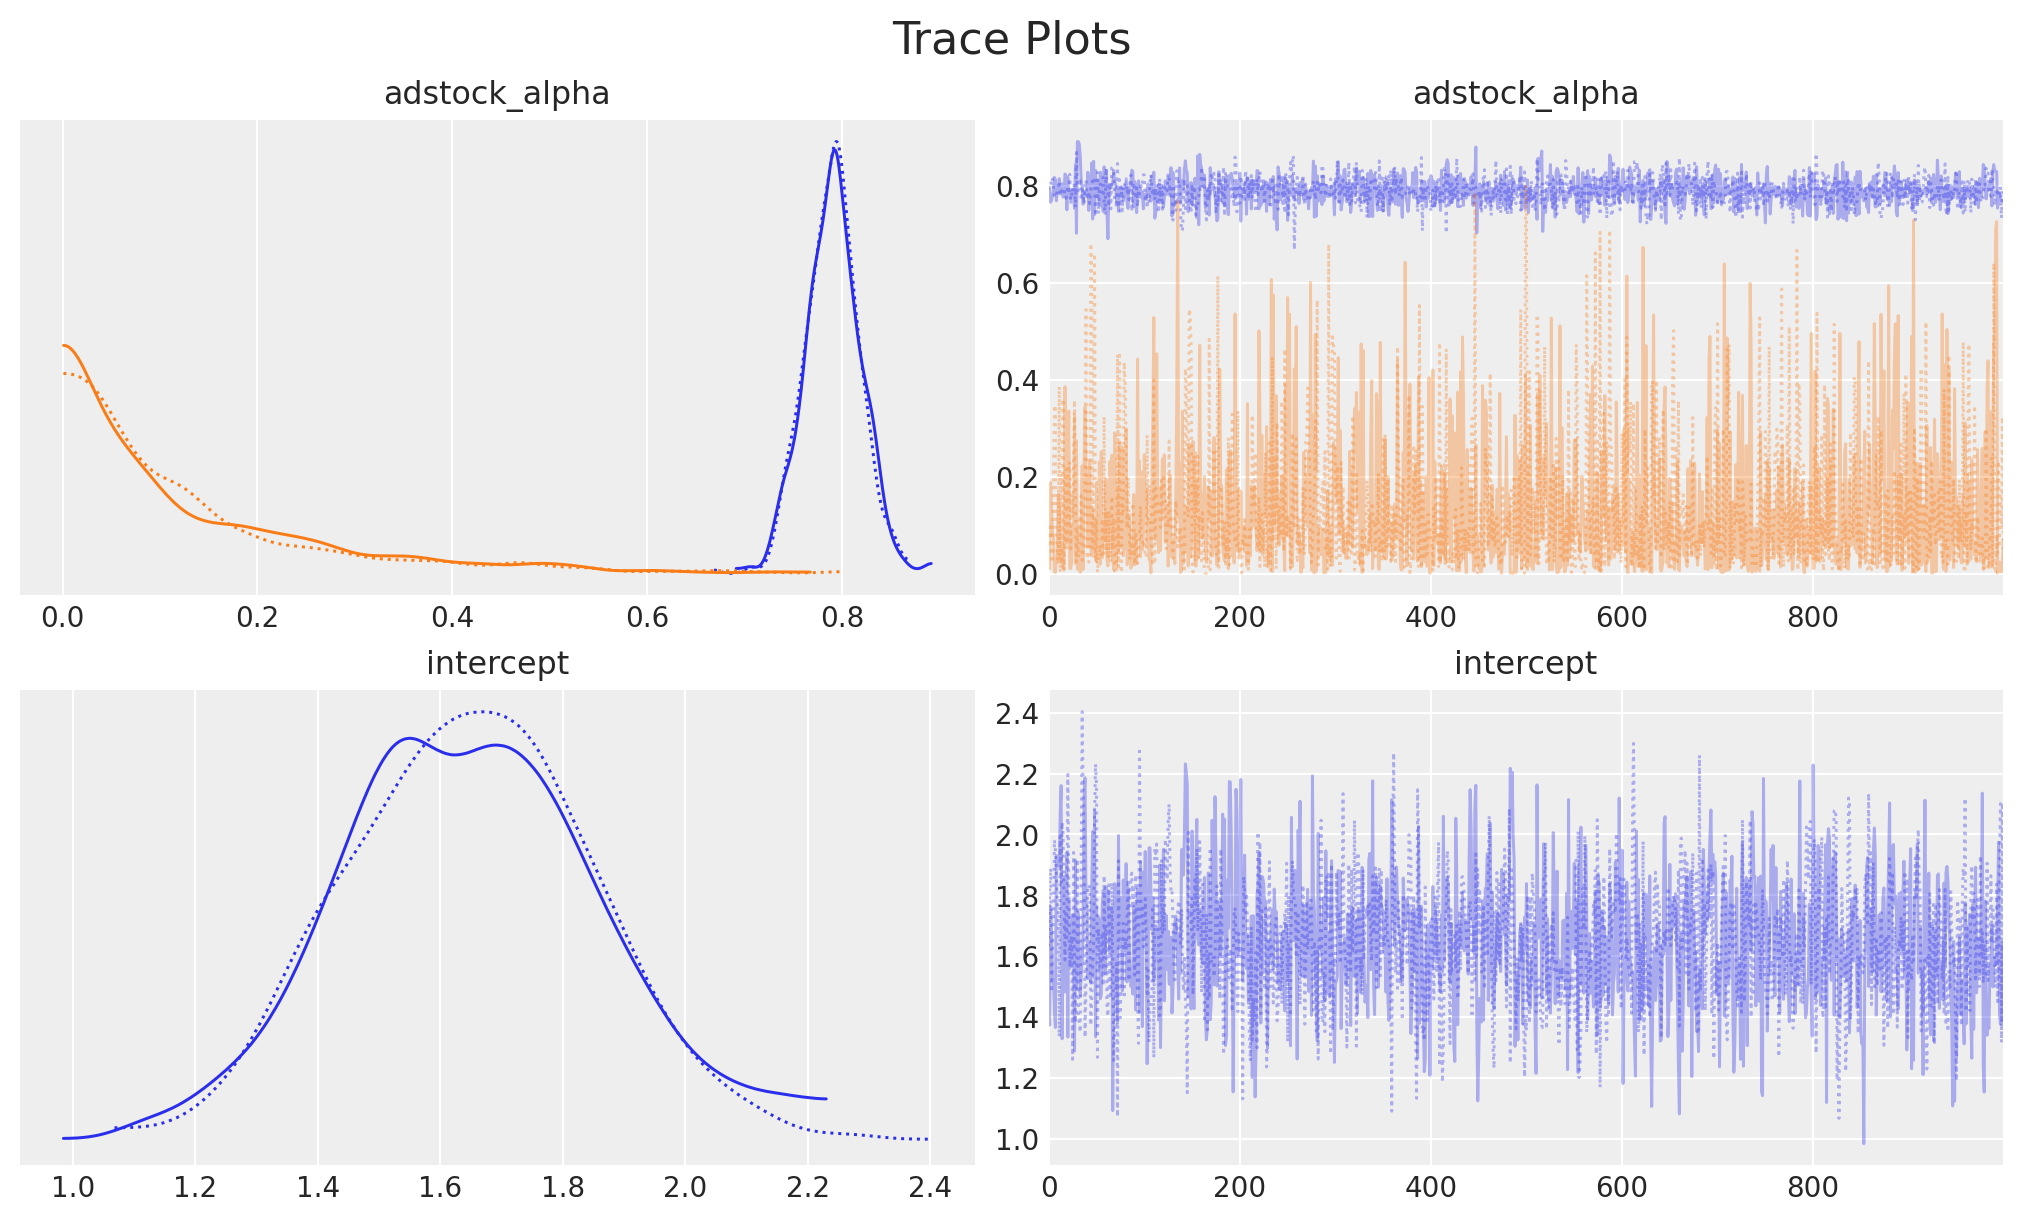

In [16]:
# Plot traces for key parameters
_ = az.plot_trace(
    data=mmm.fit_result,
    var_names=[
        "adstock_alpha",
            "intercept"    ],
    compact=True,
    backend_kwargs={"figsize": (10, 6), "layout": "constrained"},
)
plt.gcf().suptitle("Trace Plots", fontsize=16);

Good trace plots should show:

- **Left side**: Smooth, bell-shaped distributions
- **Right side**: "Fuzzy caterpillar" patterns (good mixing) with no trends

## Posterior Predictive Check

How well does our model fit the observed data?

2025-11-14 14:45:39 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:45:39 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:45:39 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: True, combined: True
2025-11-14 14:45:39 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:45:40 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:45:40 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:45:40 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:45:40 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale


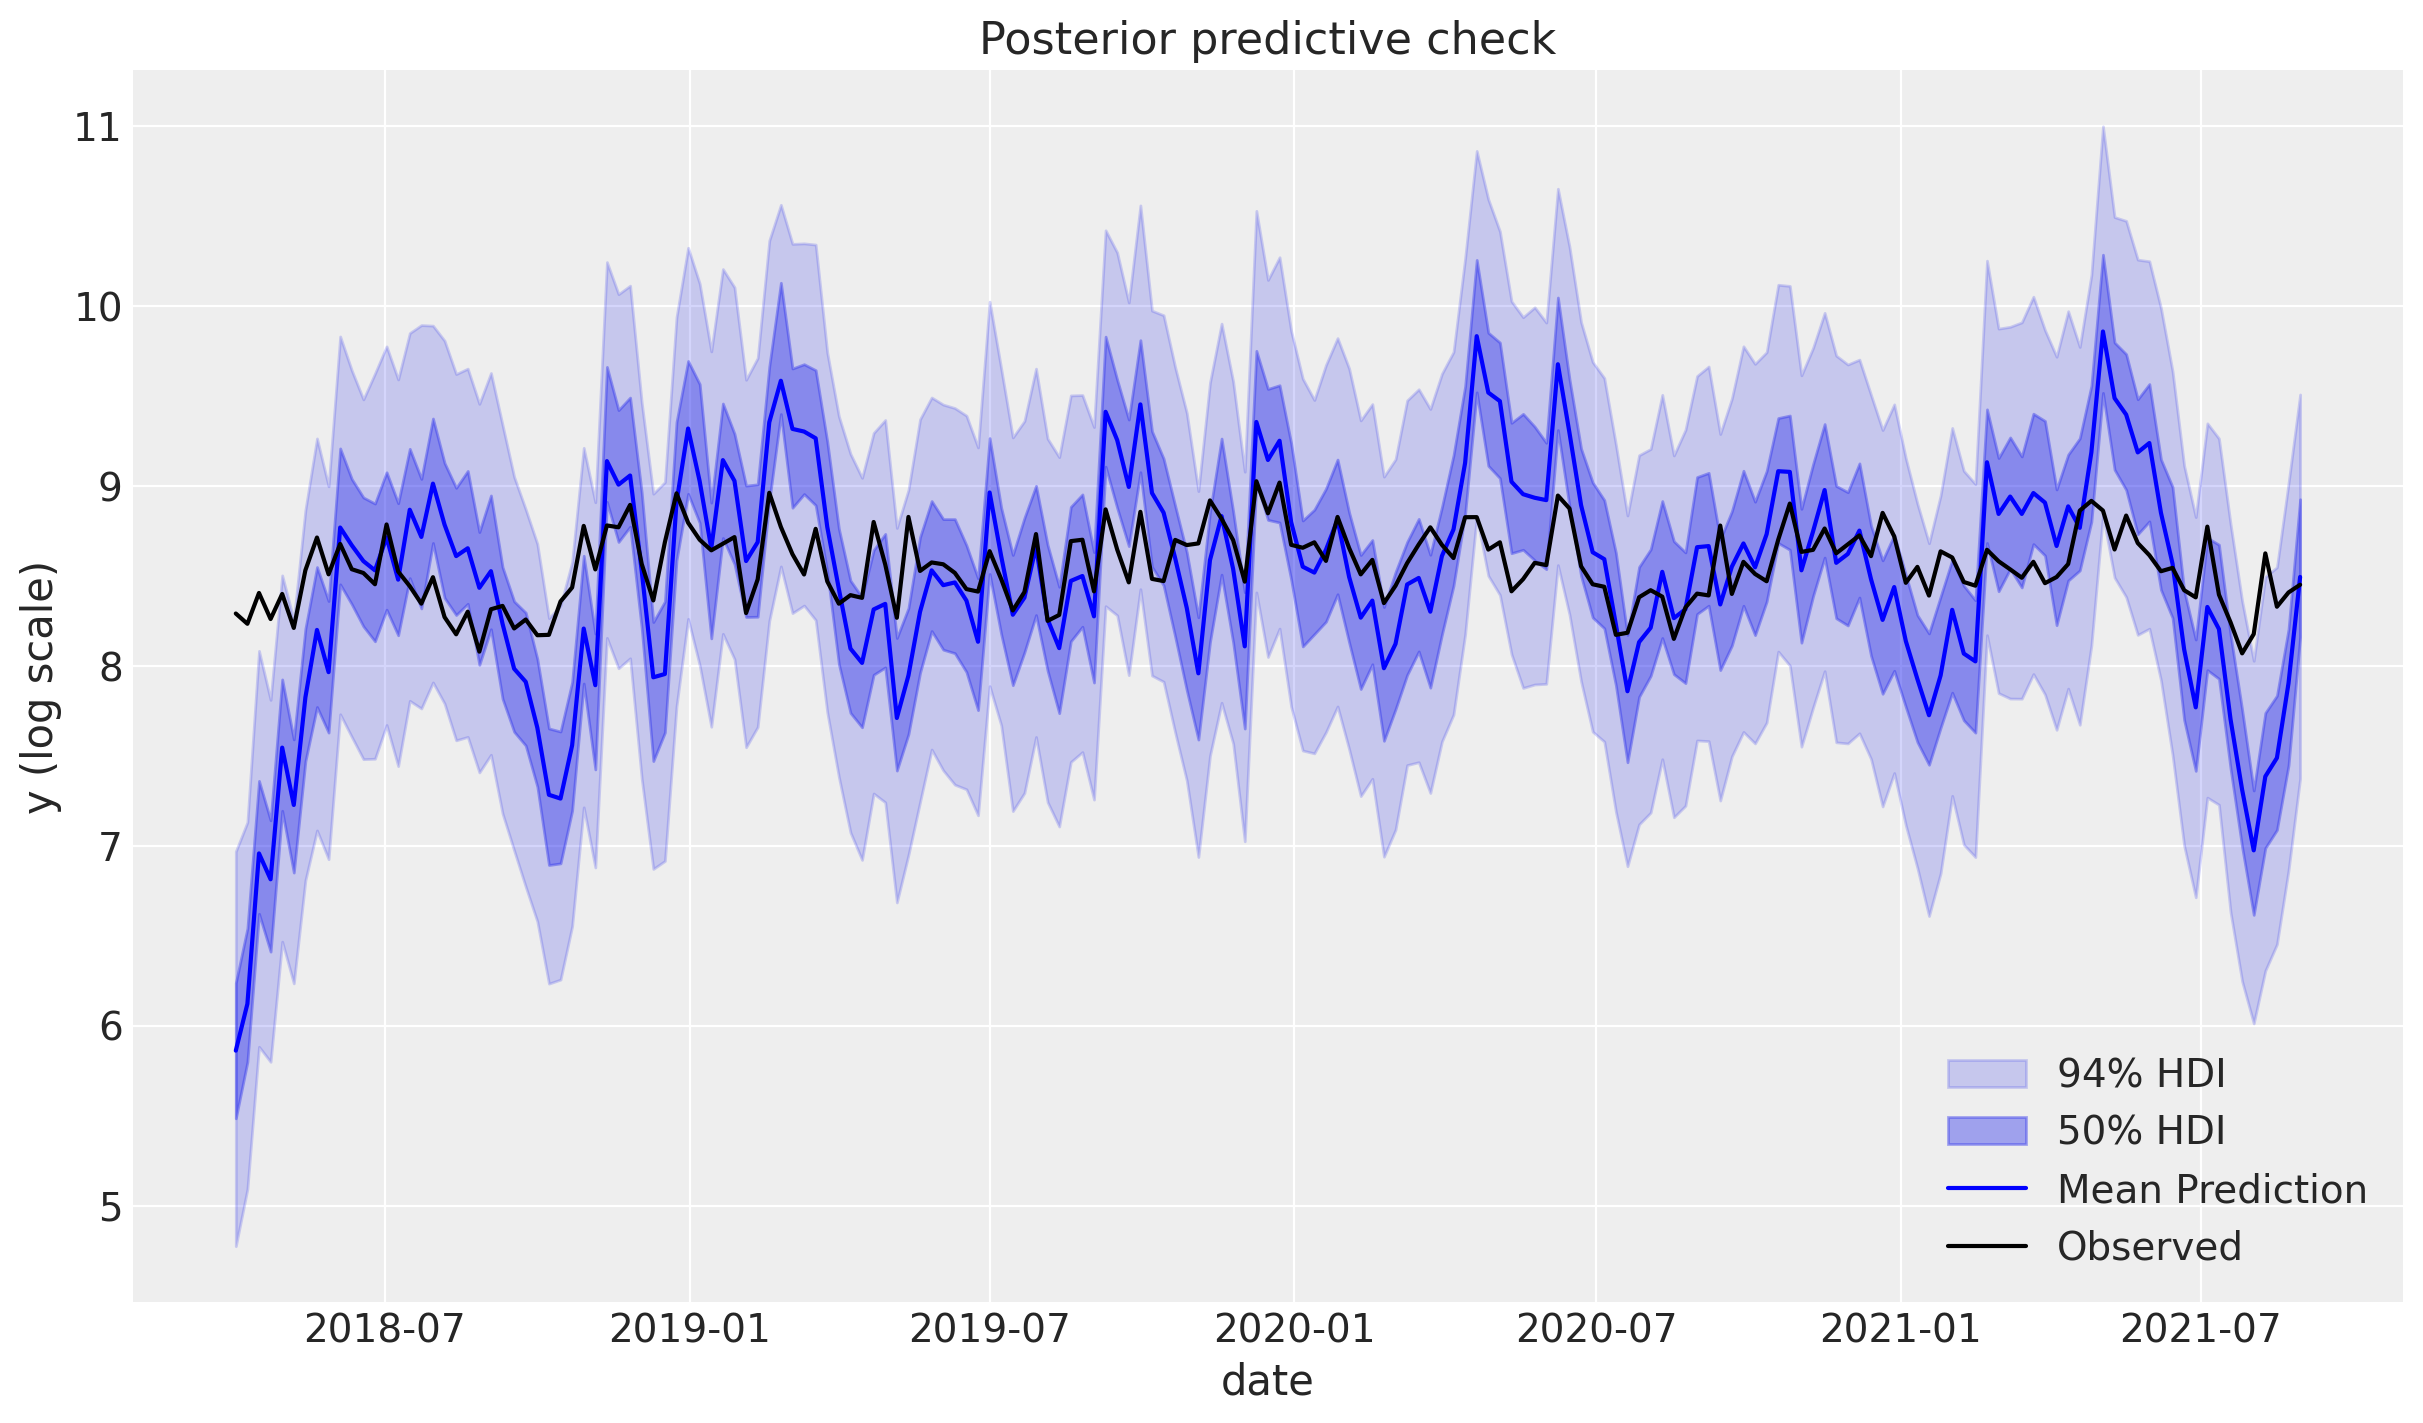

In [17]:
# Sample from posterior predictive distribution
mmm.sample_posterior_predictive(X, extend_idata=True, combined=True)

# Plot model fit
fig = mmm.plot_posterior_predictive(original_scale= False)


## NOTE CHECK extend_idata and combined if they affect predictions

The model captures the observed data well if the black dots (actual sales) fall within the shaded uncertainty bands.

## Contribution Analysis

Now for the fun part—understanding how much each component contributes to sales!

### Component Contributions Over Time

Let's visualize the contribution of each component of the model over time:

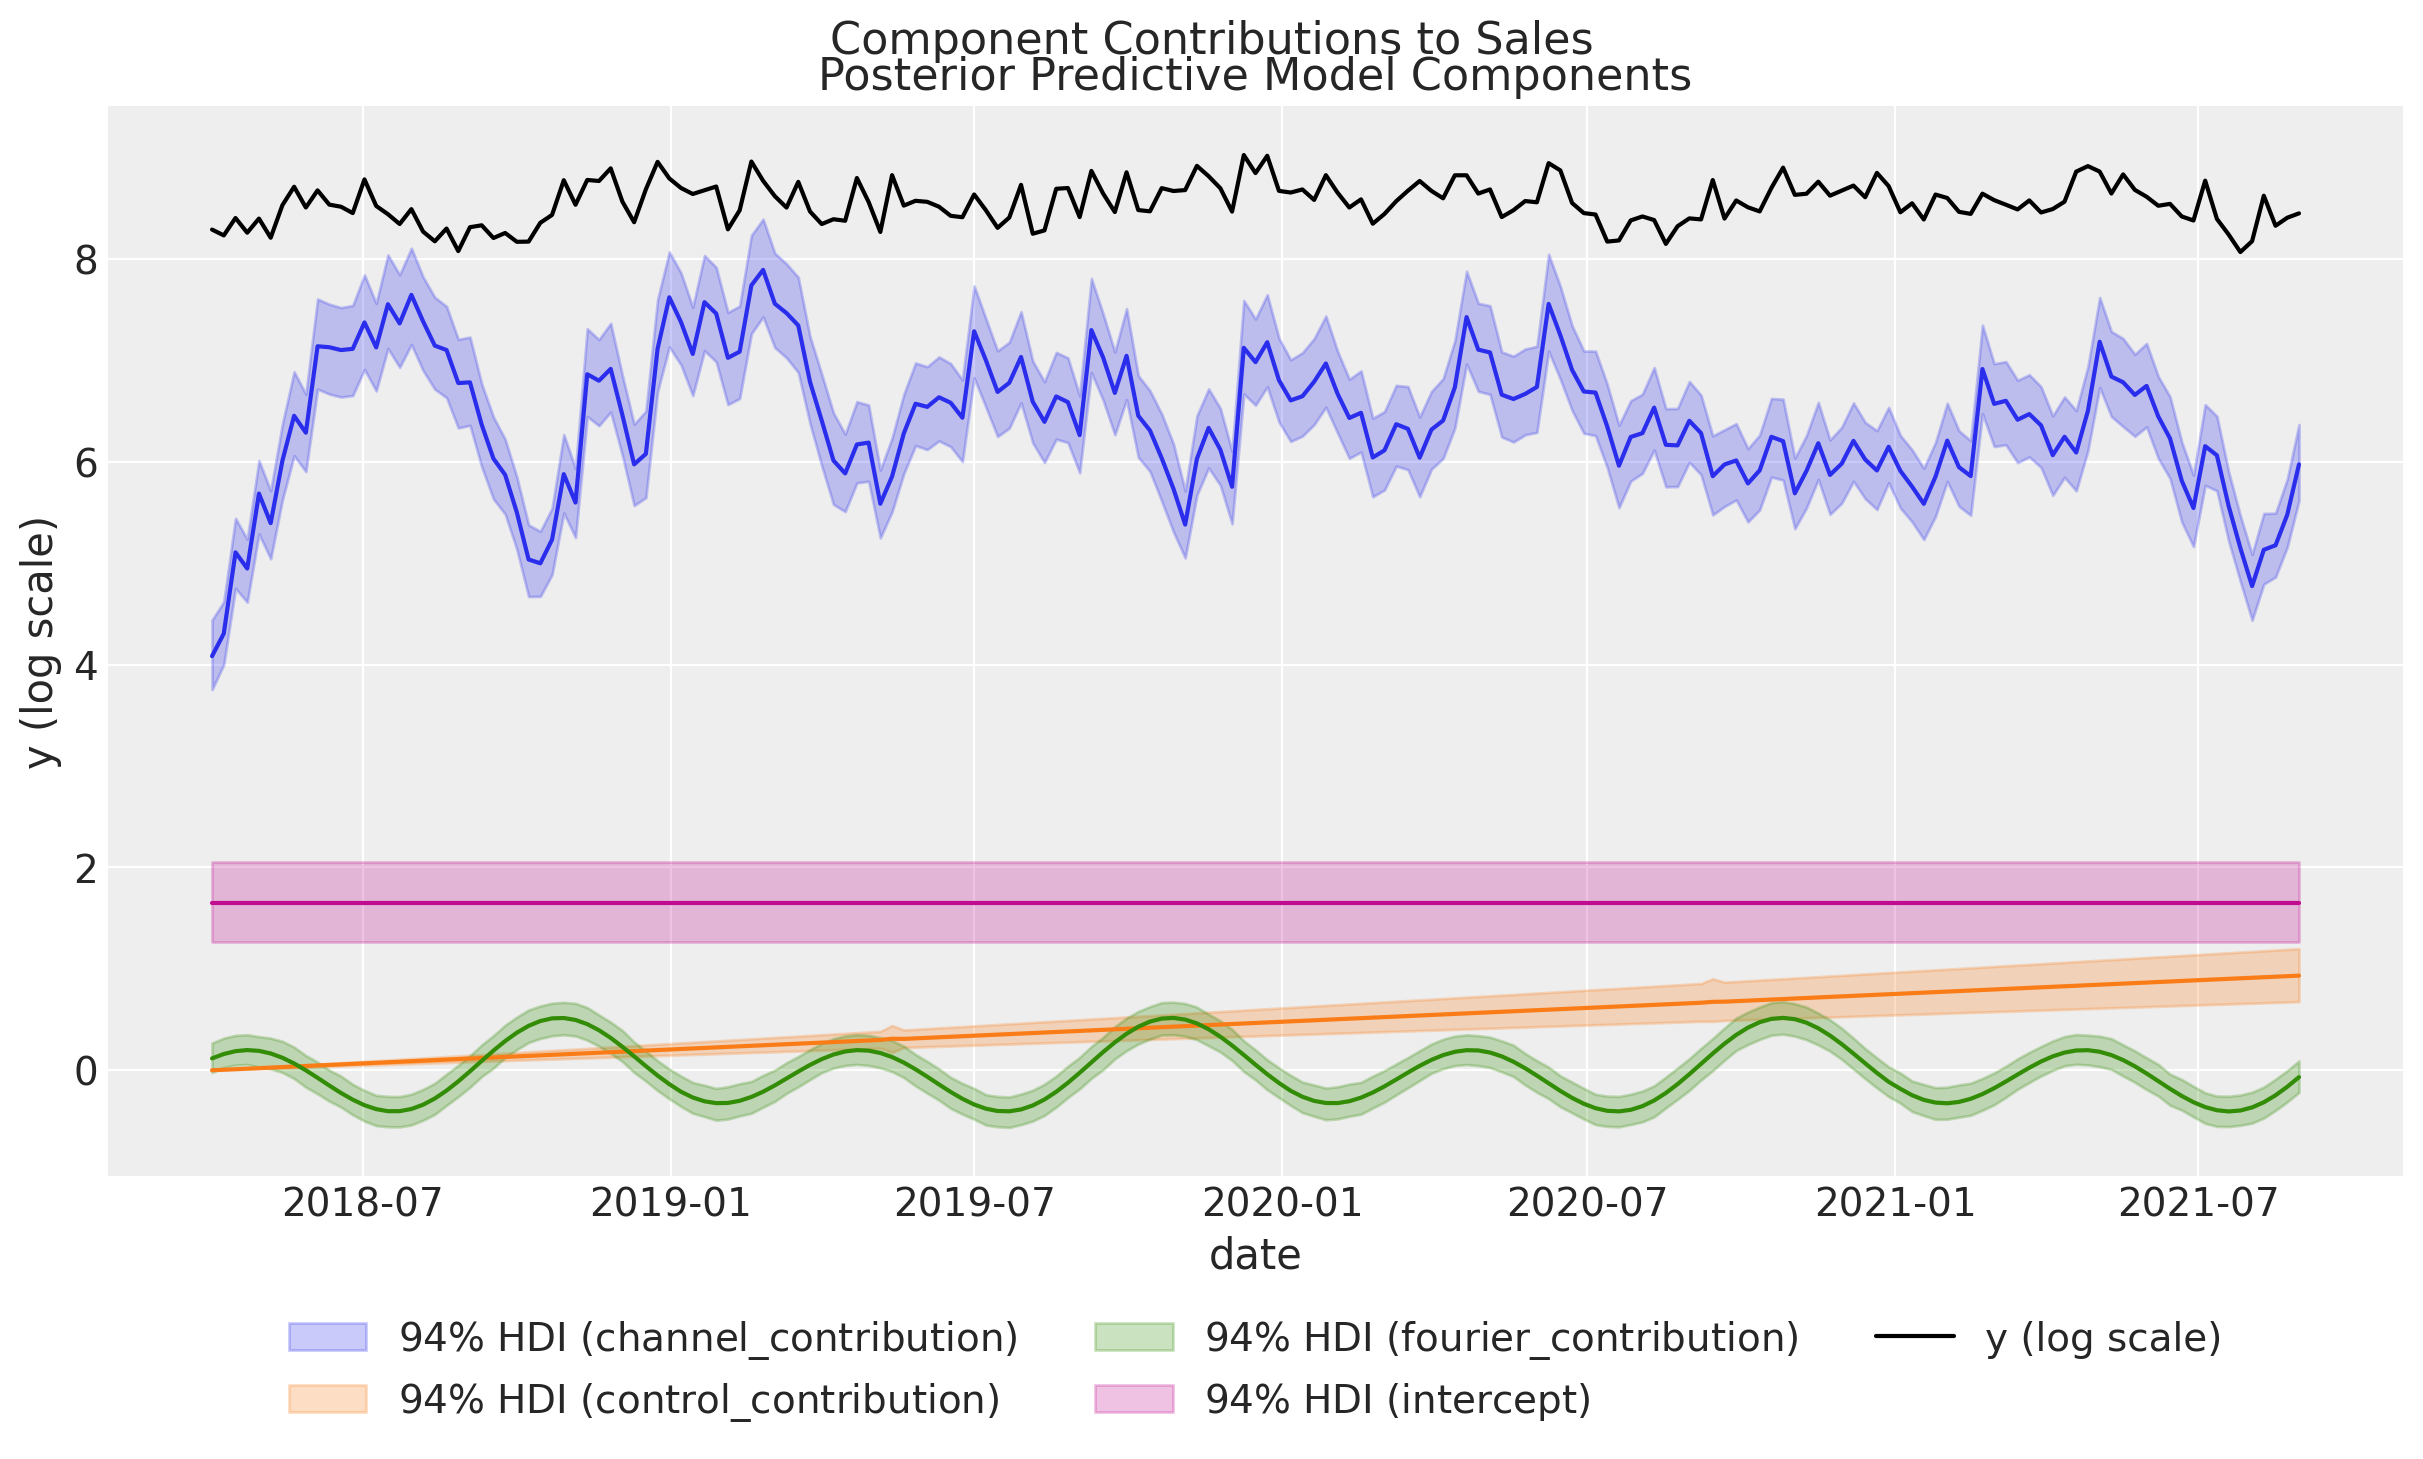

In [18]:
fig = mmm.plot_components_contributions(original_scale=False)
plt.suptitle("Component Contributions to Sales", fontsize=16, y=1.02);

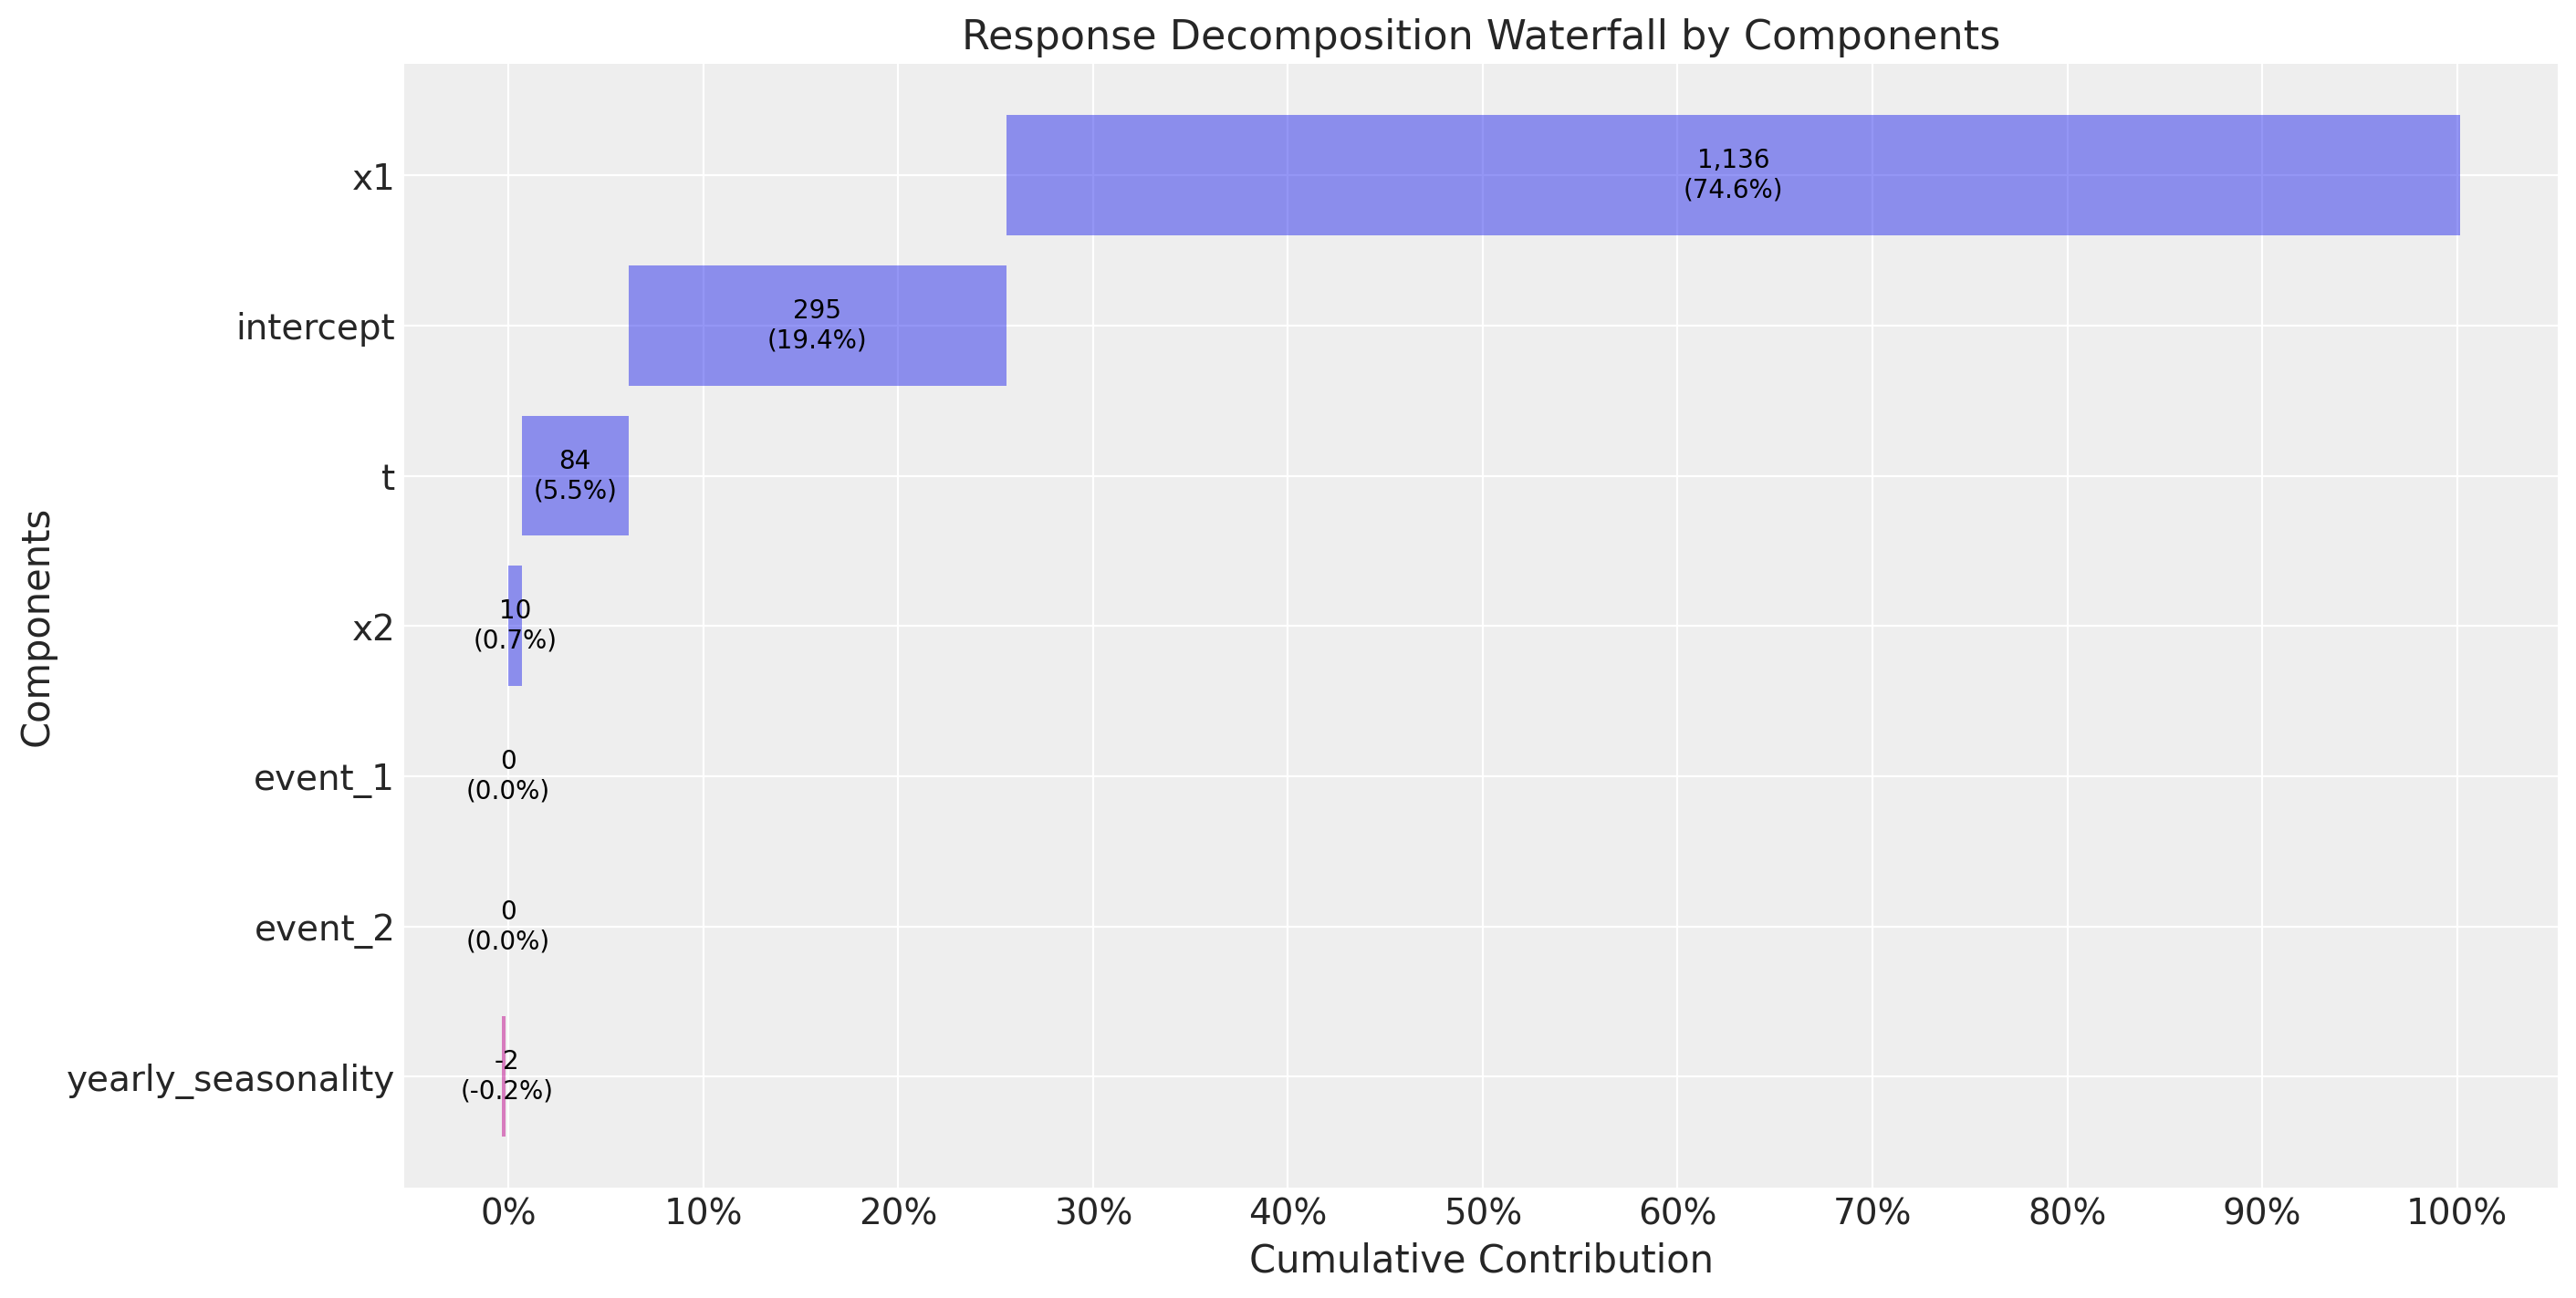

In [19]:
# Waterfall decomposition
fig = mmm.plot_waterfall_components_decomposition(original_scale=False);

This chart answers the question: "How much did each component contribute to total sales?"

### Channel Contribution Share

What percentage of media-driven sales comes from each channel?

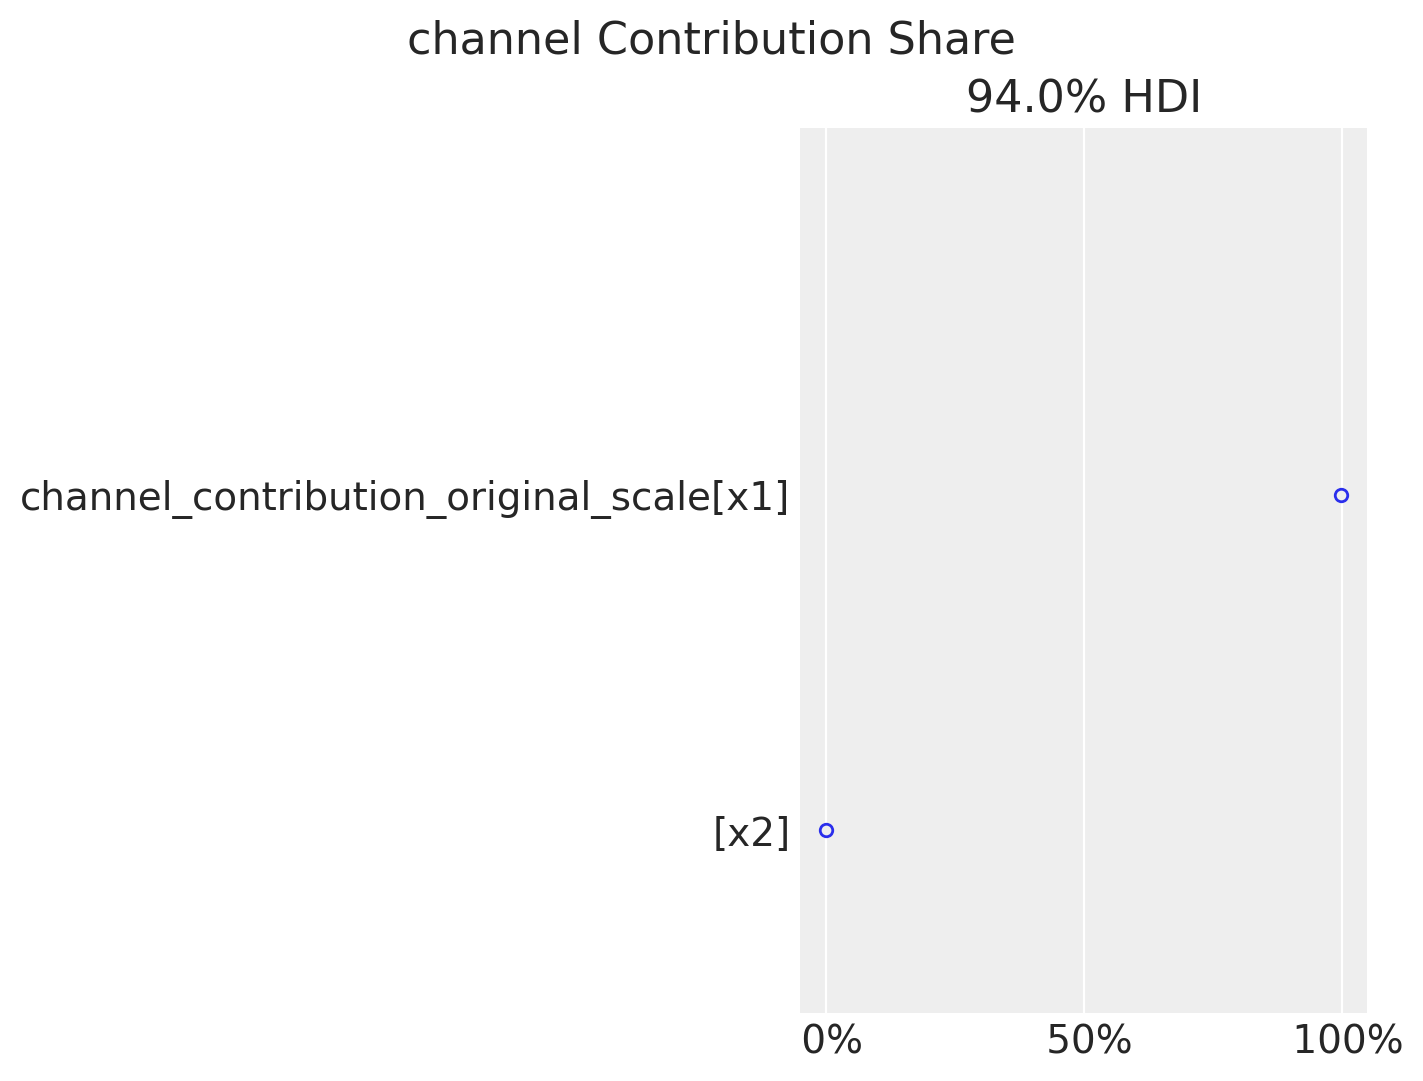

In [20]:
# Plot channel contribution share
fig = mmm.plot_channel_contribution_share_hdi(figsize=(7, 5));

### Direct Contribution Curves

These curves show the relationship between spend and contribution, accounting for saturation:

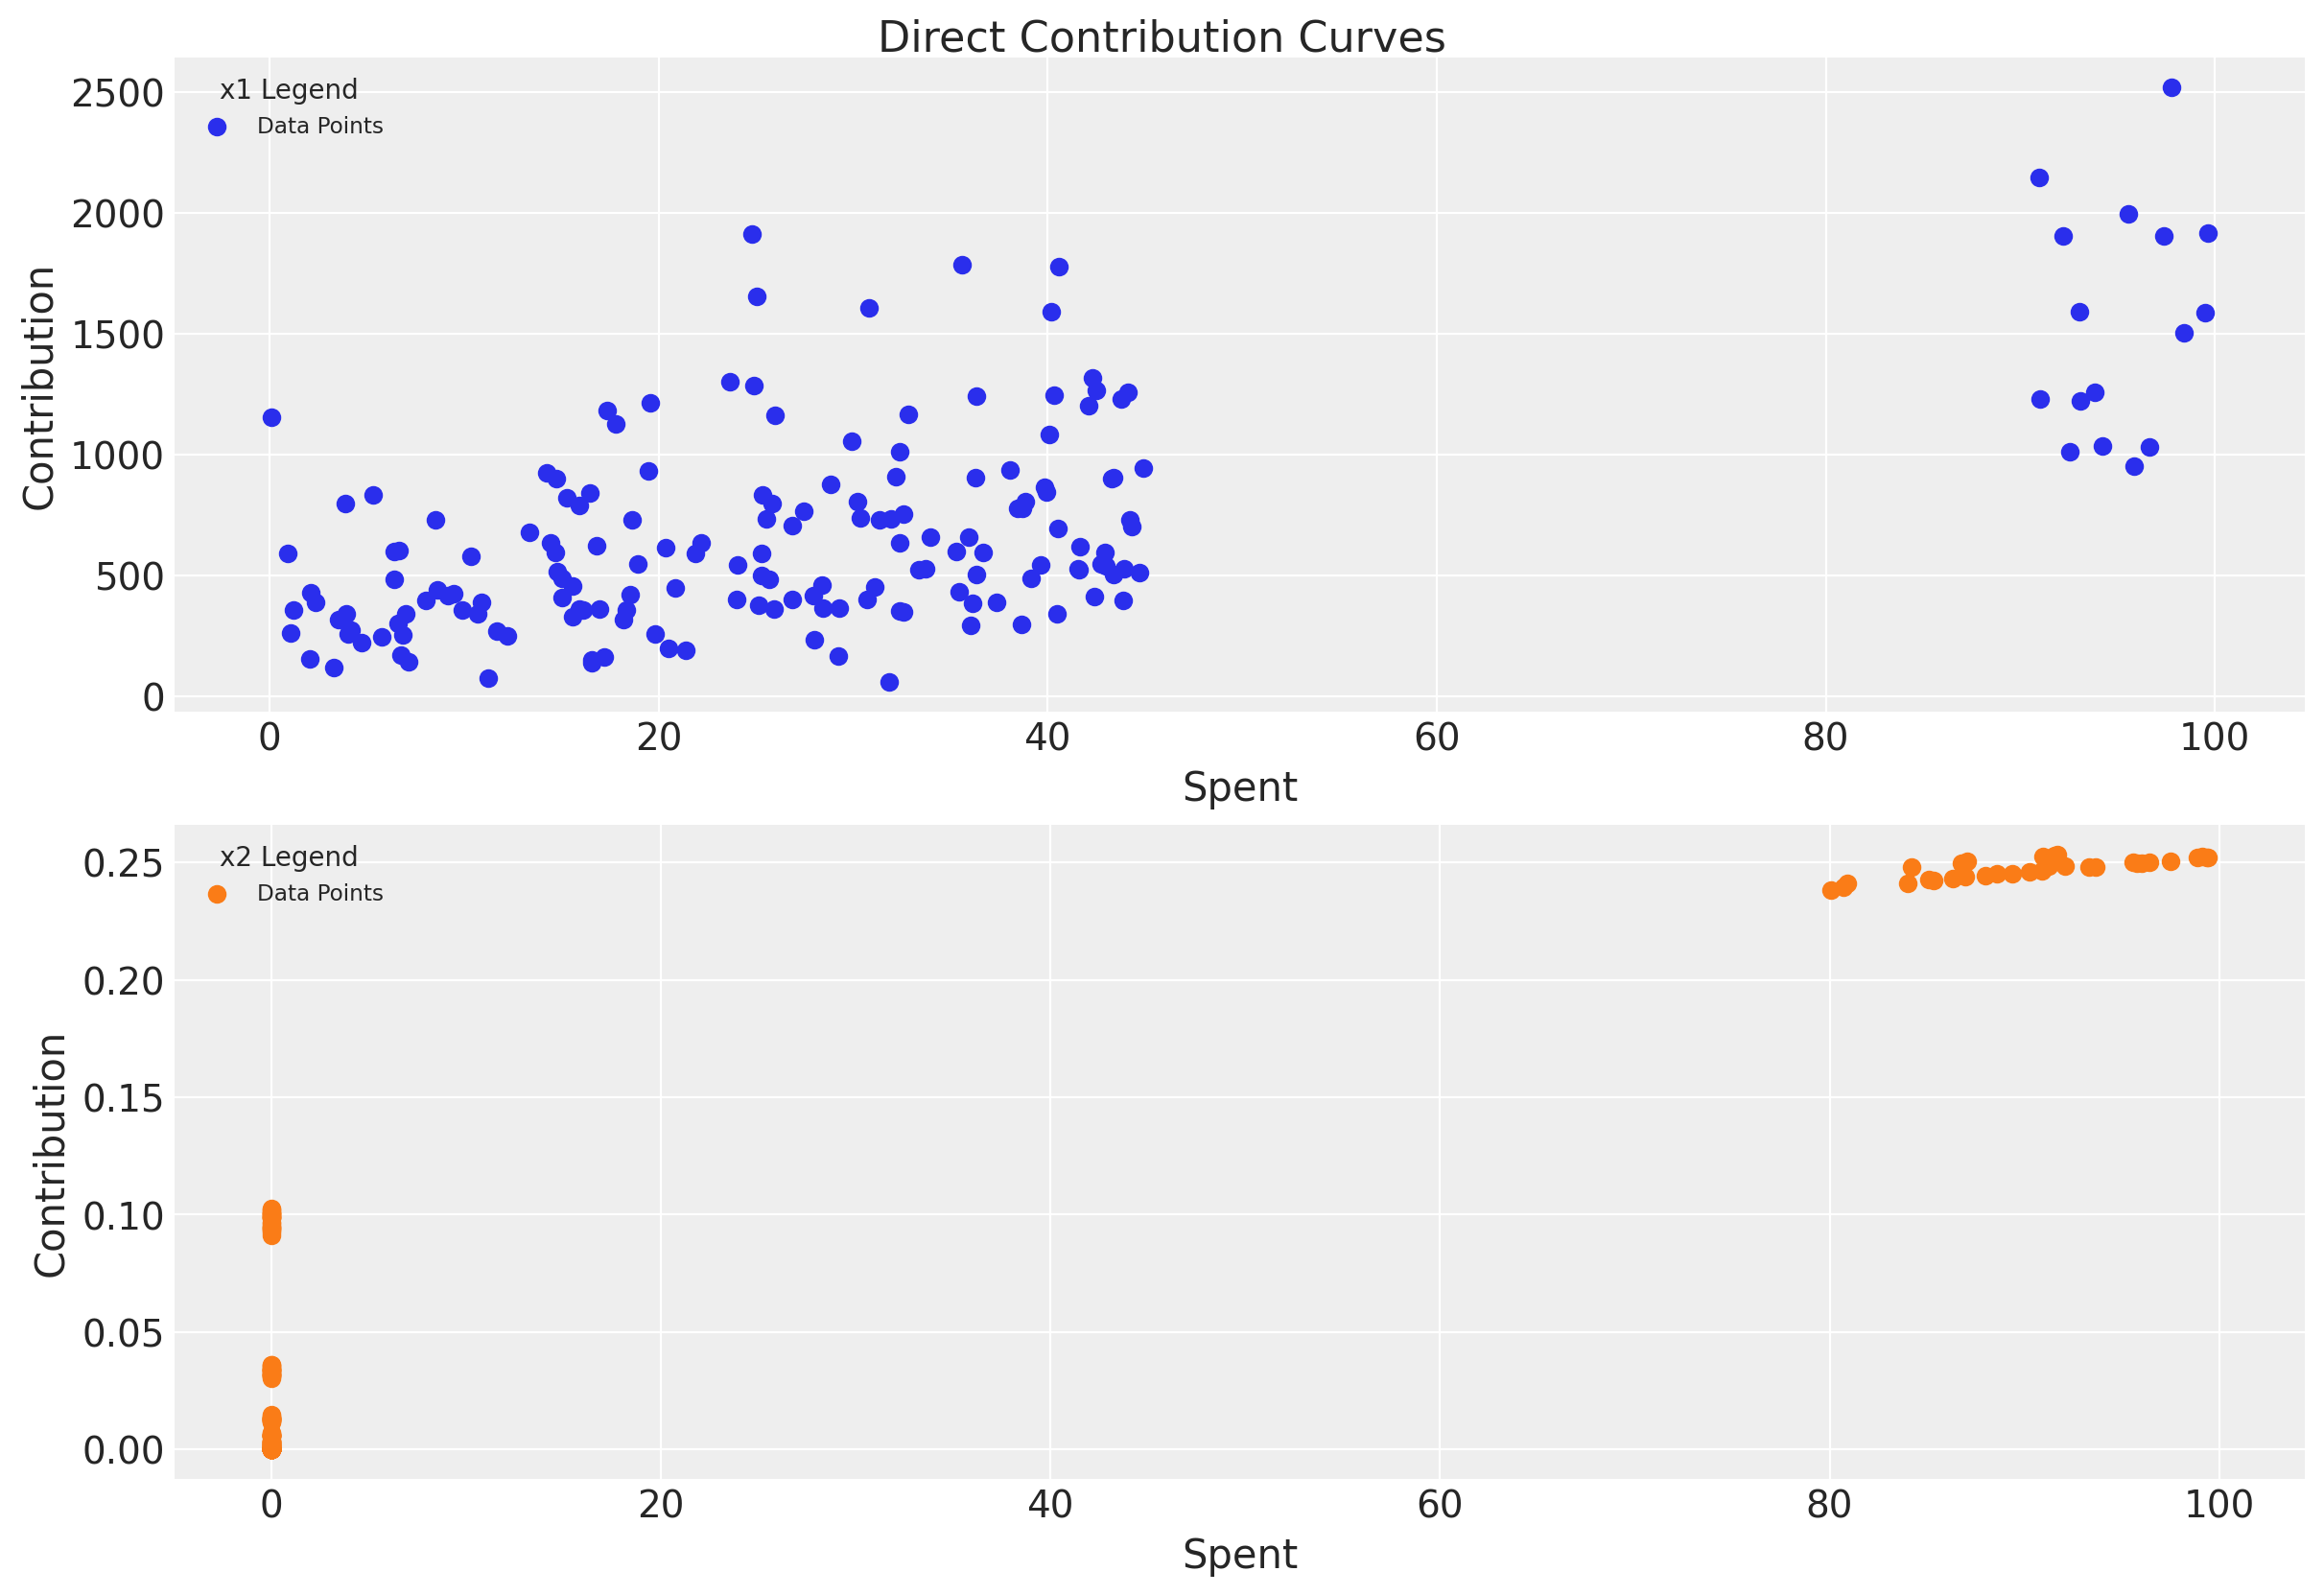

In [21]:
# Plot direct contribution curves (saturation curves)
fig = mmm.plot_direct_contribution_curves()
plt.suptitle("Direct Contribution Curves", fontsize=16, y=1.02);

Notice how the curves flatten at higher spend levels—this is the saturation effect in action!

### Channel Contribution Grid

A complementary view of the media performance is to evaluate the channel contribution at different share spend levels for the complete training period. Concretely, if we denote by α the input channel data percentage level, so that for α=1 we have the model input spend data and for α=1.5 we have a 50% increase in the spend, then we can compute the channel contribution at a grid of α-values and plot the results:

In [22]:
# # Use contribution grid configuration from config file
# grid_config = config['analysis']['contribution_grid']

# mmm.plot_channel_contribution_grid(
#     start=grid_config['start'],
#     stop=grid_config['stop'],
#     num=grid_config['num'],
#     absolute_xrange=grid_config['absolute_xrange']
# );

In [23]:
coefs = mmm.extract_coefficients(verbose = True)
print(coefs)

EXTRACTING ALL MODEL COEFFICIENTS FOR MANUAL CALCULATION

1. INTERCEPT
--------------------------------------------------------------------------------
parameter     mean      std   ci_5%   ci_95%
intercept 1.648605 0.208857 1.31663 2.000505

2. SCALING AND TRANSFORMATION PARAMETERS
--------------------------------------------------------------------------------
           parameter  value                          description
 target_scale_factor    1.0 Factor used to scale target variable
  log_epsilon_target    1.0    Epsilon for log(target + epsilon)
log_epsilon_channels    1.0  Epsilon for log(channels + epsilon)
    channel_scale_x1    1.0          Scale factor for channel x1
    channel_scale_x2    1.0          Scale factor for channel x2

3. CONTROL VARIABLE COEFFICIENTS (gamma_control)
--------------------------------------------------------------------------------
variable  coefficient      std     ci_5%   ci_95%
 event_1     0.006696 0.052145 -0.081830 0.093645
 event_2     0

In [24]:
data

,date_week,y,x1,x2,event_1,event_2,dayofyear,t
0,2018-04-02,3984.662237,31.858002,0.000000,0.0,0.0,92,0
1,2018-04-09,3762.871794,11.238848,0.000000,0.0,0.0,99,1
2,2018-04-16,4466.967388,29.240027,0.000000,0.0,0.0,106,2
3,2018-04-23,3864.219373,7.139855,0.000000,0.0,0.0,113,3
4,2018-04-30,4441.625278,38.674515,0.000000,0.0,0.0,120,4
...,...,...,...,...,...,...,...,...
174,2021-08-02,3553.546148,3.302419,0.000000,0.0,0.0,214,174
175,2021-08-09,5565.509682,16.561515,86.334885,0.0,0.0,221,175
176,2021-08-16,4137.651485,17.188222,0.000000,0.0,0.0,228,176
177,2021-08-23,4479.041351,28.025729,0.000000,0.0,0.0,235,177


# Get channel contributions using one off method

In [25]:
def compare_predictions(
    mmm,
    data,
    t_start=None,
    t_end=None,
    shutdown_channels=None,
    marginal_changes=None,
    original_scale=True,
    return_predictions=False
):
    """
    Compare model predictions with channel manipulations.
    
    Parameters
    ----------
    mmm : MMM
        Fitted MMM model
    data : pd.DataFrame
        Original data with all columns
    t_start, t_end : int, optional
        Period range to select (uses 't' column). If None, uses all data
    shutdown_channels : list, optional
        Channel names to set to zero, e.g., ['x1', 'x2']
    marginal_changes : dict, optional
        Marginal changes as {channel: change}, e.g.:
        - {'x1': 0.2} = increase x1 by 20%
        - {'x2': -0.3} = decrease x2 by 30%
    original_scale : bool, default=True
        If True, reverse log transformation (exp(predictions)) for y-axis
        If False, keep predictions in log scale
    return_predictions : bool, default=False
        If True, return dictionary with prediction arrays instead of plotting
    
    Returns
    -------
    dict or None
        If return_predictions=True, returns dict with:
        - 'dates': date array
        - 'original_mean': original predictions mean
        - 'original_lower': original predictions 94% HDI lower
        - 'original_upper': original predictions 94% HDI upper
        - 'modified_mean': modified predictions mean
        - 'modified_lower': modified predictions 94% HDI lower
        - 'modified_upper': modified predictions 94% HDI upper
        - 'observed': observed values
        - 'relative_change_pct': percentage change in mean predictions
    """
    # 1. Prepare modified data
    if t_start is not None or t_end is not None:
        mask = pd.Series(True, index=data.index)
        if t_start is not None:
            mask &= (data['t'] >= t_start)
        if t_end is not None:
            mask &= (data['t'] <= t_end)
        X = data[mask].copy()
    else:
        X = data.copy()
    
    if 'y' in X.columns:
        X = X.drop('y', axis=1)
    
    if shutdown_channels:
        for channel in shutdown_channels:
            X[channel] = 0
    
    if marginal_changes:
        for channel, change in marginal_changes.items():
            X[channel] = X[channel] * (1 + change)
    
    # 2. Get original predictions (from idata)
    original_preds = mmm.idata.posterior_predictive[mmm.output_var]
    original_mean_log = original_preds.mean(dim=["chain", "draw"]).values
    original_hdi = az.hdi(original_preds, hdi_prob=0.94)
    original_lower_log = original_hdi.sel(hdi="lower")[mmm.output_var].values
    original_upper_log = original_hdi.sel(hdi="higher")[mmm.output_var].values
    
    # 3. Sample modified predictions
    modified_preds = mmm.sample_posterior_predictive(X=X, extend_idata=False, original_scale=False)
    modified_preds_var = modified_preds[mmm.output_var]
    modified_mean_log = modified_preds_var.mean(dim="sample").values
    modified_lower_log = modified_preds_var.quantile(0.03, dim="sample").values
    modified_upper_log = modified_preds_var.quantile(0.97, dim="sample").values
    
    # 4. Apply scale transformation if requested
    if original_scale:
        # Reverse log transform: exp(log_value)
        original_mean = np.exp(original_mean_log)
        original_lower = np.exp(original_lower_log)
        original_upper = np.exp(original_upper_log)
        modified_mean = np.exp(modified_mean_log)
        modified_lower = np.exp(modified_lower_log)
        modified_upper = np.exp(modified_upper_log)
        observed = mmm._get_observed_data_for_plot(original_scale=True)
        ylabel = 'Sales (original scale)'
    else:
        original_mean = original_mean_log
        original_lower = original_lower_log
        original_upper = original_upper_log
        modified_mean = modified_mean_log
        modified_lower = modified_lower_log
        modified_upper = modified_upper_log
        observed = mmm._get_observed_data_for_plot(original_scale=False)
        ylabel = 'Sales (log scale)'
    
    # 5. Calculate relative change
    # Relative change = (original - modified) / original * 100
    relative_change_pct = (original_mean.mean() - modified_mean.mean()) / original_mean.mean() * 100
    
    dates = modified_preds.date.values
    
    # 6. Return predictions if requested
    if return_predictions:
        return {
            'dates': dates,
            'original_mean': original_mean,
            'original_lower': original_lower,
            'original_upper': original_upper,
            'modified_mean': modified_mean,
            'modified_lower': modified_lower,
            'modified_upper': modified_upper,
            'observed': observed,
            'relative_change_pct': relative_change_pct
        }
    
    # 7. Plot
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Observed as continuous line
    ax.plot(dates, observed, 'k-', label='Observed', linewidth=1.5, alpha=0.7)
    
    # Original predictions
    ax.plot(dates, original_mean, 'b-', label='Original predictions', linewidth=2)
    ax.fill_between(dates, original_lower, original_upper, alpha=0.2, color='blue')
    
    # Modified predictions
    modification_label = f"Modified ({shutdown_channels[0] if shutdown_channels else 'adjusted'} shutdown)" if shutdown_channels else "Modified predictions"
    ax.plot(dates, modified_mean, 'r-', label=modification_label, linewidth=2)
    ax.fill_between(dates, modified_lower, modified_upper, alpha=0.2, color='red')
    
    ax.set_xlabel('Date')
    ax.set_ylabel(ylabel)
    
    # Title with explanation
    title = f'Comparison: Original vs Modified Predictions\n'
    title += f'Mean decrease: {relative_change_pct:.1f}% '
    title += f'(calculated as: (mean_original - mean_modified) / mean_original × 100)'
    ax.set_title(title, fontsize=11)
    
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    return fig


### contribution x1

2025-11-14 14:45:42 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:45:42 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:45:42 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:45:42 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: False


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in scaled format
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\1277762936.py:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


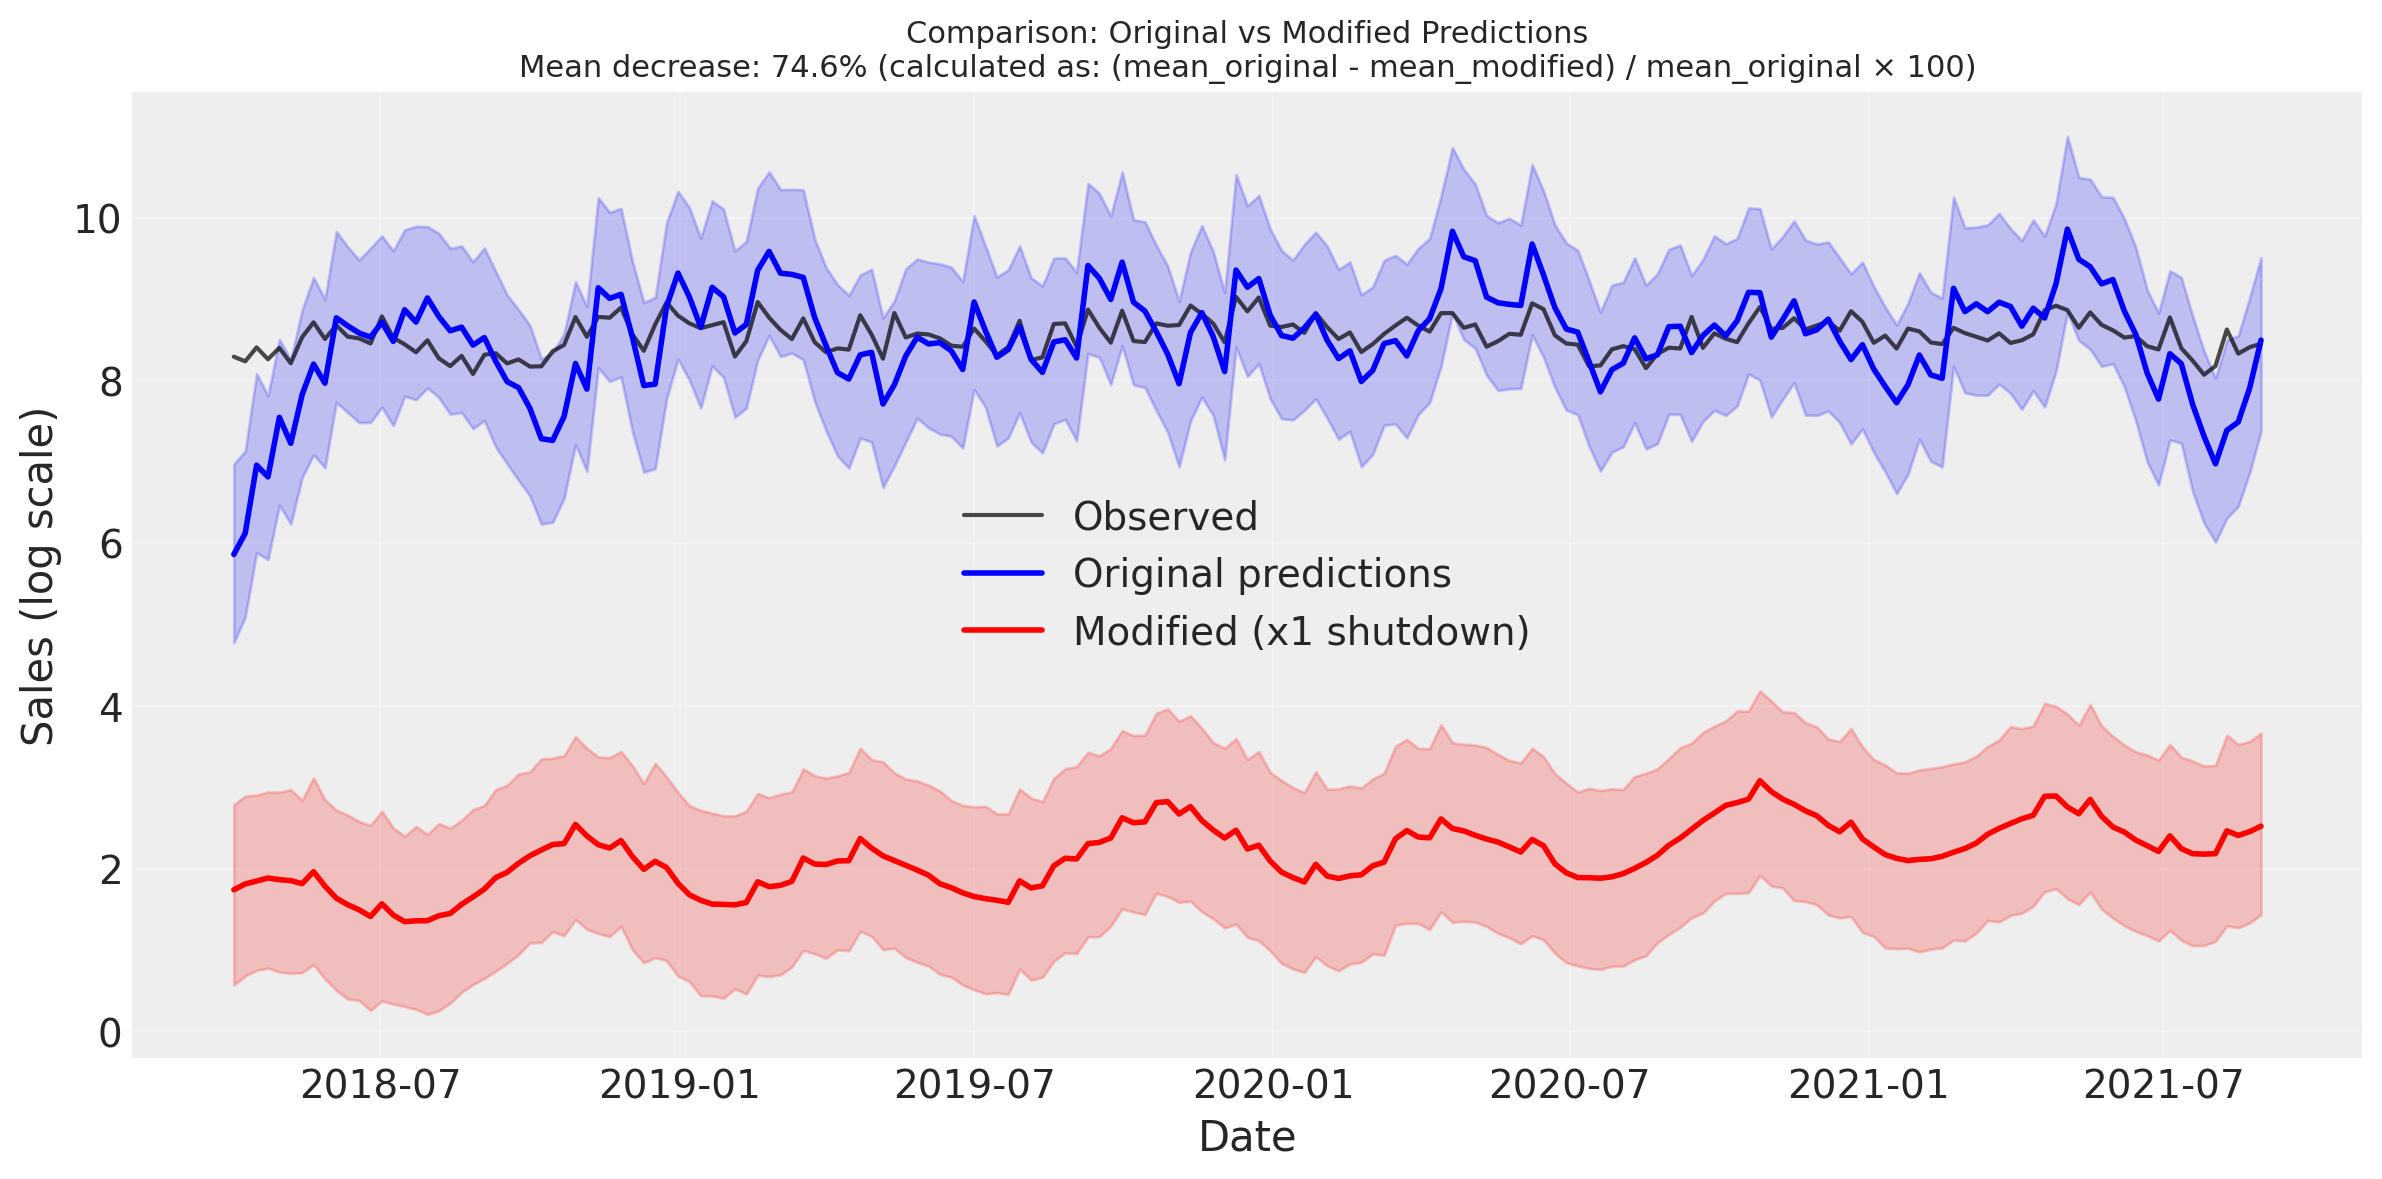

In [26]:
# Example 1: Plot the comparison
fig = compare_predictions(
    mmm=mmm,
    data=data,
    shutdown_channels=['x1'],
    original_scale=False
)

In [27]:
# Extract predictions as dictionary
predictions_dict = compare_predictions(
    mmm=mmm,
    data=data,
    shutdown_channels=['x1'],
    original_scale=True,
    return_predictions=True
)

print("\n=== EXTRACTED PREDICTIONS ===")
print(f"Keys in dictionary: {list(predictions_dict.keys())}")
print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:45:52 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: False


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in scaled format



=== EXTRACTED PREDICTIONS ===
Keys in dictionary: ['dates', 'original_mean', 'original_lower', 'original_upper', 'modified_mean', 'modified_lower', 'modified_upper', 'observed', 'relative_change_pct']

Original predictions shape: (179,)
Modified predictions shape: (179,)

Original mean (first 5): [ 351.08298151  455.43395141 1050.66359094  909.85502683 1891.37697437]
Modified mean (first 5): [5.76400158 6.12399262 6.3056285  6.41588885 6.44209548]


### contribution channel 2

2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:02 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: False


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in scaled format
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\1277762936.py:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


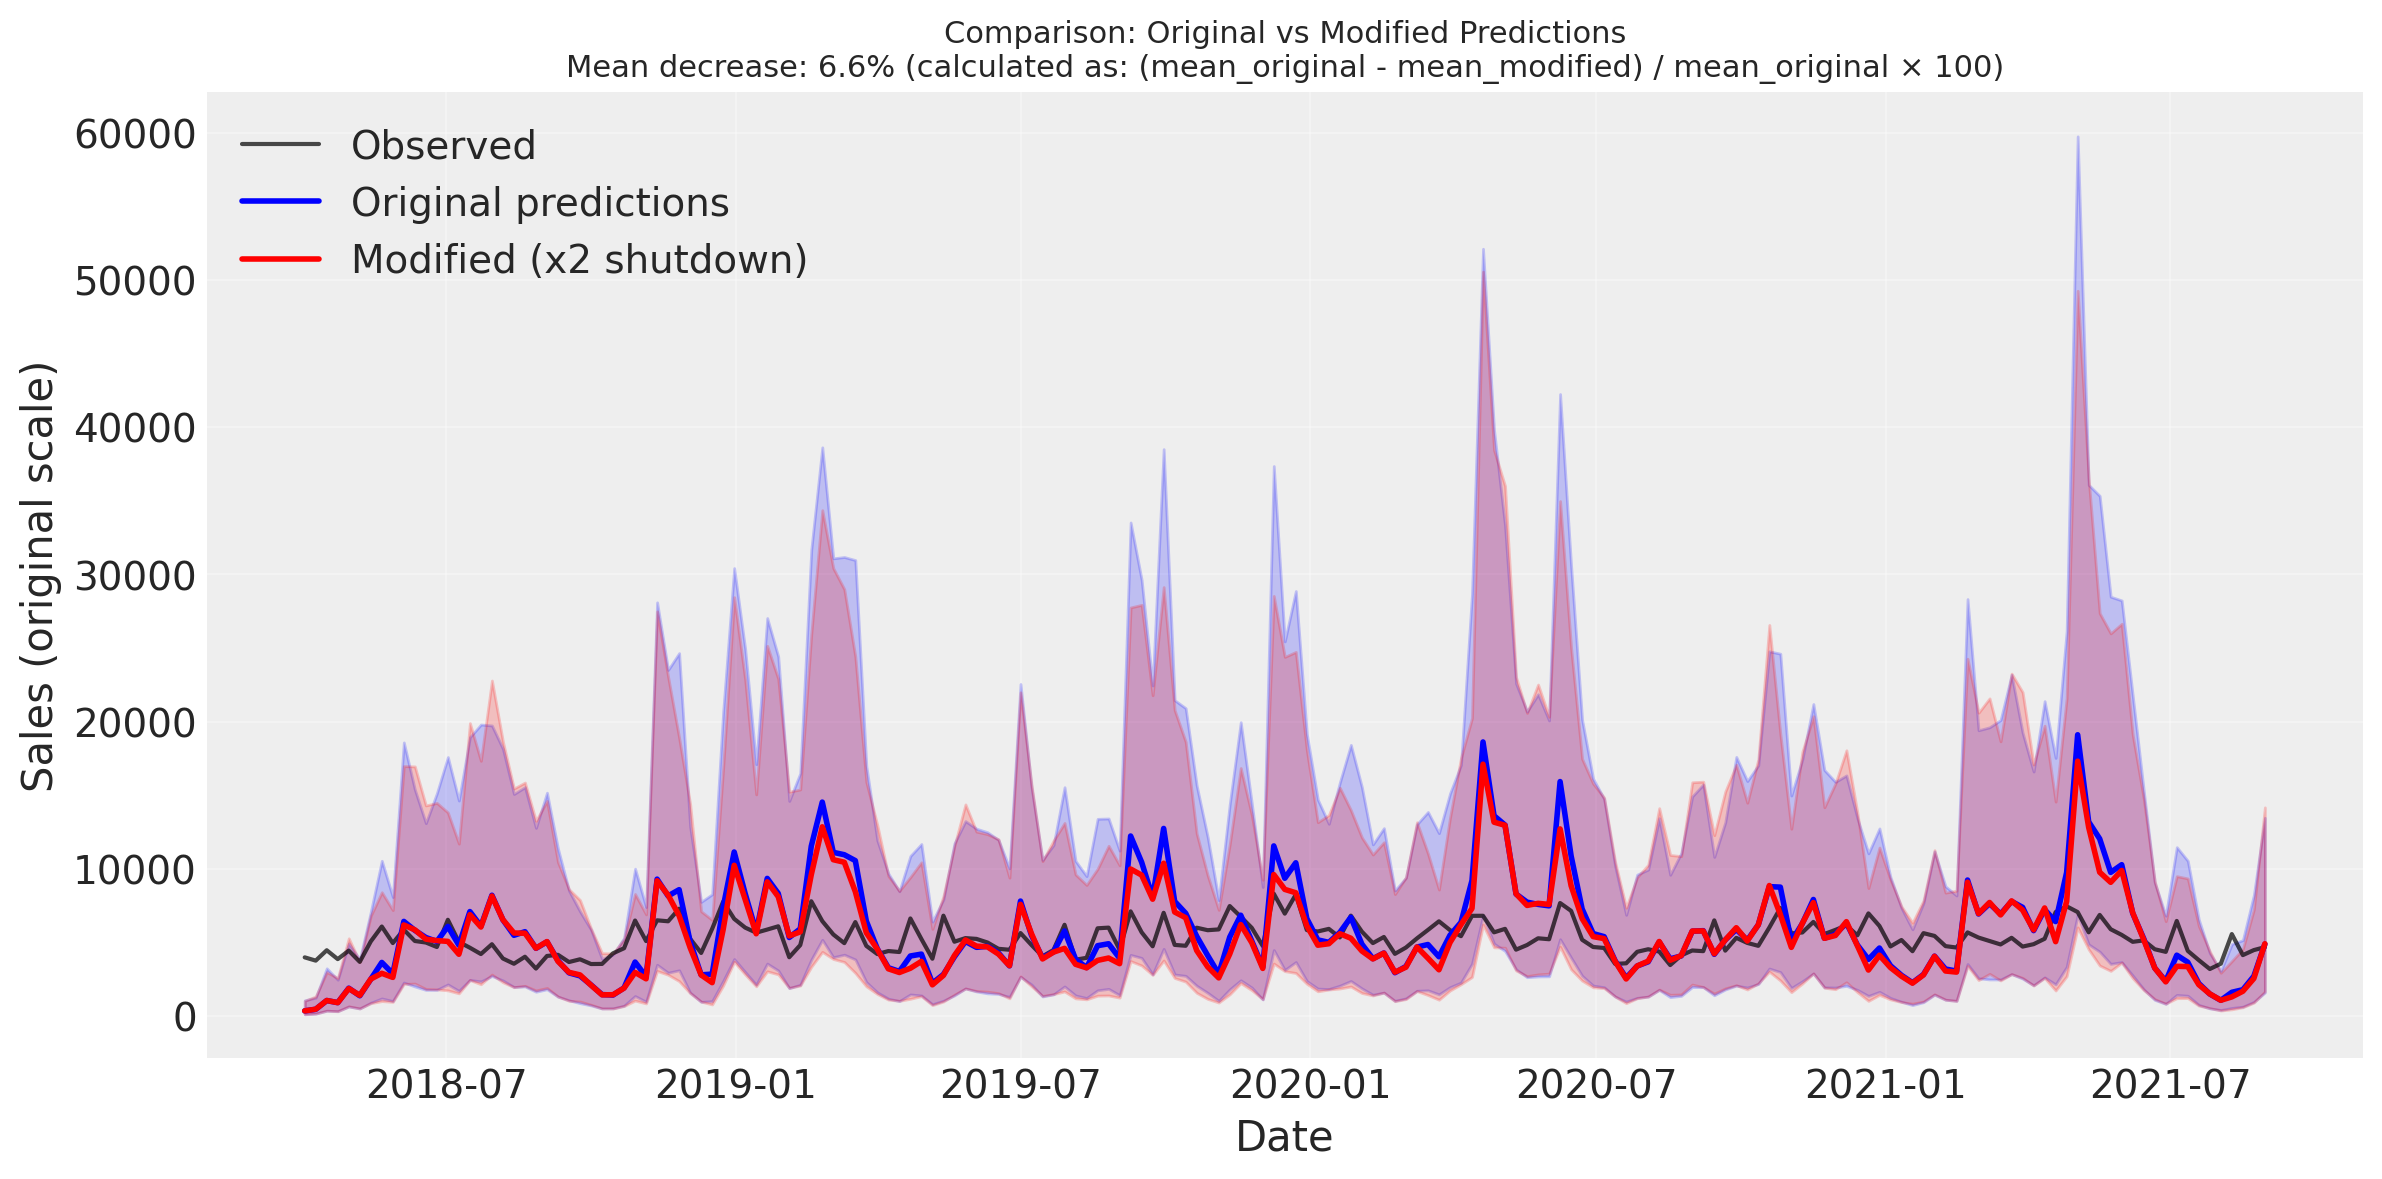

In [28]:
# Example 1: Plot the comparison
fig = compare_predictions(
    mmm=mmm,
    data=data,
    shutdown_channels=['x2'],
    original_scale=True)

In [29]:
# Extract predictions as dictionary
predictions_dict = compare_predictions(
    mmm=mmm,
    data=data,
    shutdown_channels=['x2'],
    original_scale=True,
    return_predictions=True
)

print("\n=== EXTRACTED PREDICTIONS ===")
print(f"Keys in dictionary: {list(predictions_dict.keys())}")
print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:11 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: False


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in scaled format



=== EXTRACTED PREDICTIONS ===
Keys in dictionary: ['dates', 'original_mean', 'original_lower', 'original_upper', 'modified_mean', 'modified_lower', 'modified_upper', 'observed', 'relative_change_pct']

Original predictions shape: (179,)
Modified predictions shape: (179,)

Original mean (first 5): [ 351.08298151  455.43395141 1050.66359094  909.85502683 1891.37697437]
Modified mean (first 5): [ 349.25789547  462.27434431 1043.22191038  907.15230832 1898.33676205]


# Component Shutdown Feature

This section tests the new `shutdown_components` parameter in `sample_posterior_predictive`.

The new feature allows us to selectively "turn off" specific model components to isolate their contributions through simulation. This is theoretically correct for contribution analysis.

In [30]:
def get_individual_contributions(mmm, data, channel_cols, control_cols):
    """
    Automatically calculate individual contributions for all model components.
    
    Parameters
    ----------
    mmm : MMM object
        Fitted MMM model instance
    data : pd.DataFrame
        Original data containing date column
    channel_cols : list
        List of channel column names (e.g., ['x1', 'x2'])
    control_cols : list
        List of control column names (e.g., ['t', 'event_1', 'event_2'])
    
    Returns
    -------
    dict
        Dictionary containing:
        - 'dates': array of dates
        - 'channels': dict with channel contributions {channel_name: xarray}
        - 'controls': dict with control contributions {control_name: xarray}
        - 'intercept': xarray with intercept contribution
        - 'seasonality': xarray with seasonality contribution
    """
    import numpy as np
    
    # Get baseline predictions (no components shut down)
    preds_normal = mmm.sample_posterior_predictive(
        data,
        extend_idata=False,
        combined=True,
        include_last_observations=False,
        original_scale=True
    )
    
    contributions = {
        'dates': None,
        'channels': {},
        'controls': {},
        'intercept': None,
        'seasonality': None
    }
    
    # Calculate channel contributions
    for channel in channel_cols:
        preds_no_channel = mmm.sample_posterior_predictive(
            data,
            extend_idata=False,
            combined=True,
            include_last_observations=False,
            original_scale=True,
            shutdown_components=[channel]
        )
        contributions['channels'][channel] = preds_normal[mmm.output_var] - preds_no_channel[mmm.output_var]
    
    # Calculate control contributions
    for control in control_cols:
        preds_no_control = mmm.sample_posterior_predictive(
            data,
            extend_idata=False,
            combined=True,
            include_last_observations=False,
            original_scale=True,
            shutdown_components=[control]
        )
        contributions['controls'][control] = preds_normal[mmm.output_var] - preds_no_control[mmm.output_var]
    
    # Calculate intercept contribution
    preds_no_intercept = mmm.sample_posterior_predictive(
        data,
        extend_idata=False,
        combined=True,
        include_last_observations=False,
        original_scale=True,
        shutdown_components=['intercept']
    )
    contributions['intercept'] = preds_normal[mmm.output_var] - preds_no_intercept[mmm.output_var]
    
    # Calculate seasonality contribution
    preds_no_seasonality = mmm.sample_posterior_predictive(
        data,
        extend_idata=False,
        combined=True,
        include_last_observations=False,
        original_scale=True,
        shutdown_components=['seasonality']
    )
    contributions['seasonality'] = preds_normal[mmm.output_var] - preds_no_seasonality[mmm.output_var]
    
    # Extract dates from one of the contribution xarrays
    # Use intercept as it's guaranteed to exist
    dates_obj = contributions['intercept']
    if hasattr(dates_obj, 'coords') and 'date' in dates_obj.coords:
        contributions['dates'] = dates_obj['date'].values
    else:
        # Fallback: create index array
        contributions['dates'] = np.arange(dates_obj.shape[-1])
    
    return contributions

In [31]:
def plot_all_contributions(contributions, mmm, data, use_log_scale=True):
    """
    Create two plots: one with all contributions together, and subplots with individual contributions.
    Always includes the actual target data and full model predictions in both plots.
    
    Parameters
    ----------
    contributions : dict
        Dictionary returned by get_individual_contributions() containing:
        - 'dates': array of dates
        - 'channels': dict with channel contributions
        - 'controls': dict with control contributions
        - 'intercept': intercept contribution
        - 'seasonality': seasonality contribution
    mmm : MMM object
        Fitted MMM model instance (required)
    data : pd.DataFrame
        Original data containing the target column 'y'
    use_log_scale : bool, default=True
        If True, plot everything in log space.
        If False, plot everything in normal space.
    
    Returns
    -------
    tuple
        (fig_combined, fig_individual) - Two matplotlib figure objects
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import arviz as az
    
    dates = contributions['dates']
    
    # Collect all components and their mean contributions
    all_components = {}
    
    if use_log_scale:
        # Convert contributions from normal space to log space
        # Add channels
        for channel_name, channel_data in contributions['channels'].items():
            mean_dims = [d for d in getattr(channel_data, 'dims', []) if d != 'date']
            mean_contrib = channel_data.mean(dim=mean_dims) if mean_dims else channel_data
            all_components[f'Channel: {channel_name}'] = np.asarray(mean_contrib)
        
        # Add controls
        for control_name, control_data in contributions['controls'].items():
            mean_dims = [d for d in getattr(control_data, 'dims', []) if d != 'date']
            mean_contrib = control_data.mean(dim=mean_dims) if mean_dims else control_data
            all_components[f'Control: {control_name}'] = np.asarray(mean_contrib)
        
        # Add intercept
        intercept_data = contributions['intercept']
        mean_dims = [d for d in getattr(intercept_data, 'dims', []) if d != 'date']
        mean_contrib = intercept_data.mean(dim=mean_dims) if mean_dims else intercept_data
        all_components['Intercept'] = np.asarray(mean_contrib)
        
        # Add seasonality
        seasonality_data = contributions['seasonality']
        mean_dims = [d for d in getattr(seasonality_data, 'dims', []) if d != 'date']
        mean_contrib = seasonality_data.mean(dim=mean_dims) if mean_dims else seasonality_data
        all_components['Seasonality'] = np.asarray(mean_contrib)
        
        # Get full model predictions (already in log space)
        preds = mmm.idata.posterior_predictive[mmm.output_var]
        predictions_mean = preds.mean(dim=["chain", "draw"]).values
        
        # Get HDI for uncertainty bands (already in log space)
        preds_hdi = az.hdi(preds, hdi_prob=0.94)
        predictions_hdi_lower = preds_hdi.sel(hdi="lower")[mmm.output_var].values
        predictions_hdi_upper = preds_hdi.sel(hdi="higher")[mmm.output_var].values
        
        # Get actual observed target data and convert to log space
        y_observed = np.log(data["y"].values)
        
        ylabel = 'Value (Log Scale)'
        title_suffix = '(Log Scale)'
        reference_line = 0
        
    else:
        # Keep everything in normal space
        # Add channels (already in normal space from get_individual_contributions)
        for channel_name, channel_data in contributions['channels'].items():
            mean_dims = [d for d in getattr(channel_data, 'dims', []) if d != 'date']
            mean_contrib = channel_data.mean(dim=mean_dims) if mean_dims else channel_data
            all_components[f'Channel: {channel_name}'] = np.asarray(mean_contrib)
        
        # Add controls (already in normal space)
        for control_name, control_data in contributions['controls'].items():
            mean_dims = [d for d in getattr(control_data, 'dims', []) if d != 'date']
            mean_contrib = control_data.mean(dim=mean_dims) if mean_dims else control_data
            all_components[f'Control: {control_name}'] = np.asarray(mean_contrib)
        
        # Add intercept (already in normal space)
        intercept_data = contributions['intercept']
        mean_dims = [d for d in getattr(intercept_data, 'dims', []) if d != 'date']
        mean_contrib = intercept_data.mean(dim=mean_dims) if mean_dims else intercept_data
        all_components['Intercept'] = np.asarray(mean_contrib)
        
        # Add seasonality (already in normal space)
        seasonality_data = contributions['seasonality']
        mean_dims = [d for d in getattr(seasonality_data, 'dims', []) if d != 'date']
        mean_contrib = seasonality_data.mean(dim=mean_dims) if mean_dims else seasonality_data
        all_components['Seasonality'] = np.asarray(mean_contrib)
        
        # Get full model predictions from posterior_predictive (in log space, need to convert)
        preds = mmm.idata.posterior_predictive[mmm.output_var]
        predictions_mean = np.exp(preds.mean(dim=["chain", "draw"]).values)
        
        # Get HDI for uncertainty bands (convert from log space to normal space)
        preds_hdi = az.hdi(preds, hdi_prob=0.94)
        predictions_hdi_lower = np.exp(preds_hdi.sel(hdi="lower")[mmm.output_var].values)
        predictions_hdi_upper = np.exp(preds_hdi.sel(hdi="higher")[mmm.output_var].values)
        
        # Get actual observed target data (already in normal space)
        y_observed = data["y"].values
        
        ylabel = 'Value (Normal Scale)'
        title_suffix = '(Normal Scale)'
        reference_line = 0
    
    # === PLOT 1: All contributions together ===
    fig_combined, ax = plt.subplots(figsize=(14, 8))
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(all_components)))
    
    for idx, (component_name, component_values) in enumerate(all_components.items()):
        ax.plot(dates, component_values, label=component_name, linewidth=2, color=colors[idx])
    
    # Add actual observed target data
    ax.plot(dates, y_observed, label='Actual Target (Y)', linewidth=2.5,
            color='red', linestyle='--', alpha=0.9, zorder=11)
    
    # Add full model predictions
    ax.plot(dates, predictions_mean, label='Full Model Prediction', linewidth=2.5,
            color='black', linestyle='-', alpha=0.8, zorder=10)
    ax.fill_between(dates, predictions_hdi_lower, predictions_hdi_upper,
                    alpha=0.2, color='gray', label='94% HDI', zorder=5)
    
    ax.axhline(reference_line, color='k', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f'All Component Contributions Over Time {title_suffix}',
                 fontsize=14, fontweight='bold')
    ax.legend(loc='best', framealpha=0.9)
    ax.grid(alpha=0.3)
    
    try:
        fig_combined.autofmt_xdate()
    except Exception:
        pass
    
    plt.tight_layout()
    
    # === PLOT 2: Individual subplots ===
    # Add one extra subplot for predictions
    n_base_components = len(all_components)
    n_total_components = n_base_components + 1
    n_cols = 2
    n_rows = int(np.ceil(n_total_components / n_cols))
    
    fig_individual, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    
    # Flatten axes array for easier iteration
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    axes_flat = axes.flatten()
    
    # Plot all component contributions
    for idx, (component_name, component_values) in enumerate(all_components.items()):
        ax = axes_flat[idx]
        ax.plot(dates, component_values, linewidth=2, color=colors[idx])
        ax.axhline(reference_line, color='k', linewidth=0.8, linestyle='--', alpha=0.5)
        ax.set_xlabel('Date', fontsize=10)
        ax.set_ylabel(ylabel, fontsize=10)
        ax.set_title(component_name, fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)
        
        try:
            ax.tick_params(axis='x', rotation=45)
        except Exception:
            pass
    
    # Add full model predictions subplot
    ax = axes_flat[n_base_components]
    ax.plot(dates, predictions_mean, linewidth=2.5, color='black', label='Mean Prediction')
    ax.fill_between(dates, predictions_hdi_lower, predictions_hdi_upper,
                    alpha=0.3, color='gray', label='94% HDI')
    ax.set_xlabel('Date', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title('Full Model Prediction', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.3)
    
    try:
        ax.tick_params(axis='x', rotation=45)
    except Exception:
        pass
    
    # Hide unused subplots
    for idx in range(n_total_components, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    
    plt.suptitle(f'Individual Component Contributions {title_suffix}', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    return fig_combined, fig_individual

2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 8)
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 8)
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:21 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 8)
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:31 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


...

2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 8)
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 8)
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: False, combined: True
2025-11-14 14:46:41 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-11-14 14:46:51 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-11-14 14:46:51 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 2000})
2025-11-14 14:46:51 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-11-14 14:46:51 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\1426589166.py:152: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\1426589166.py:204: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


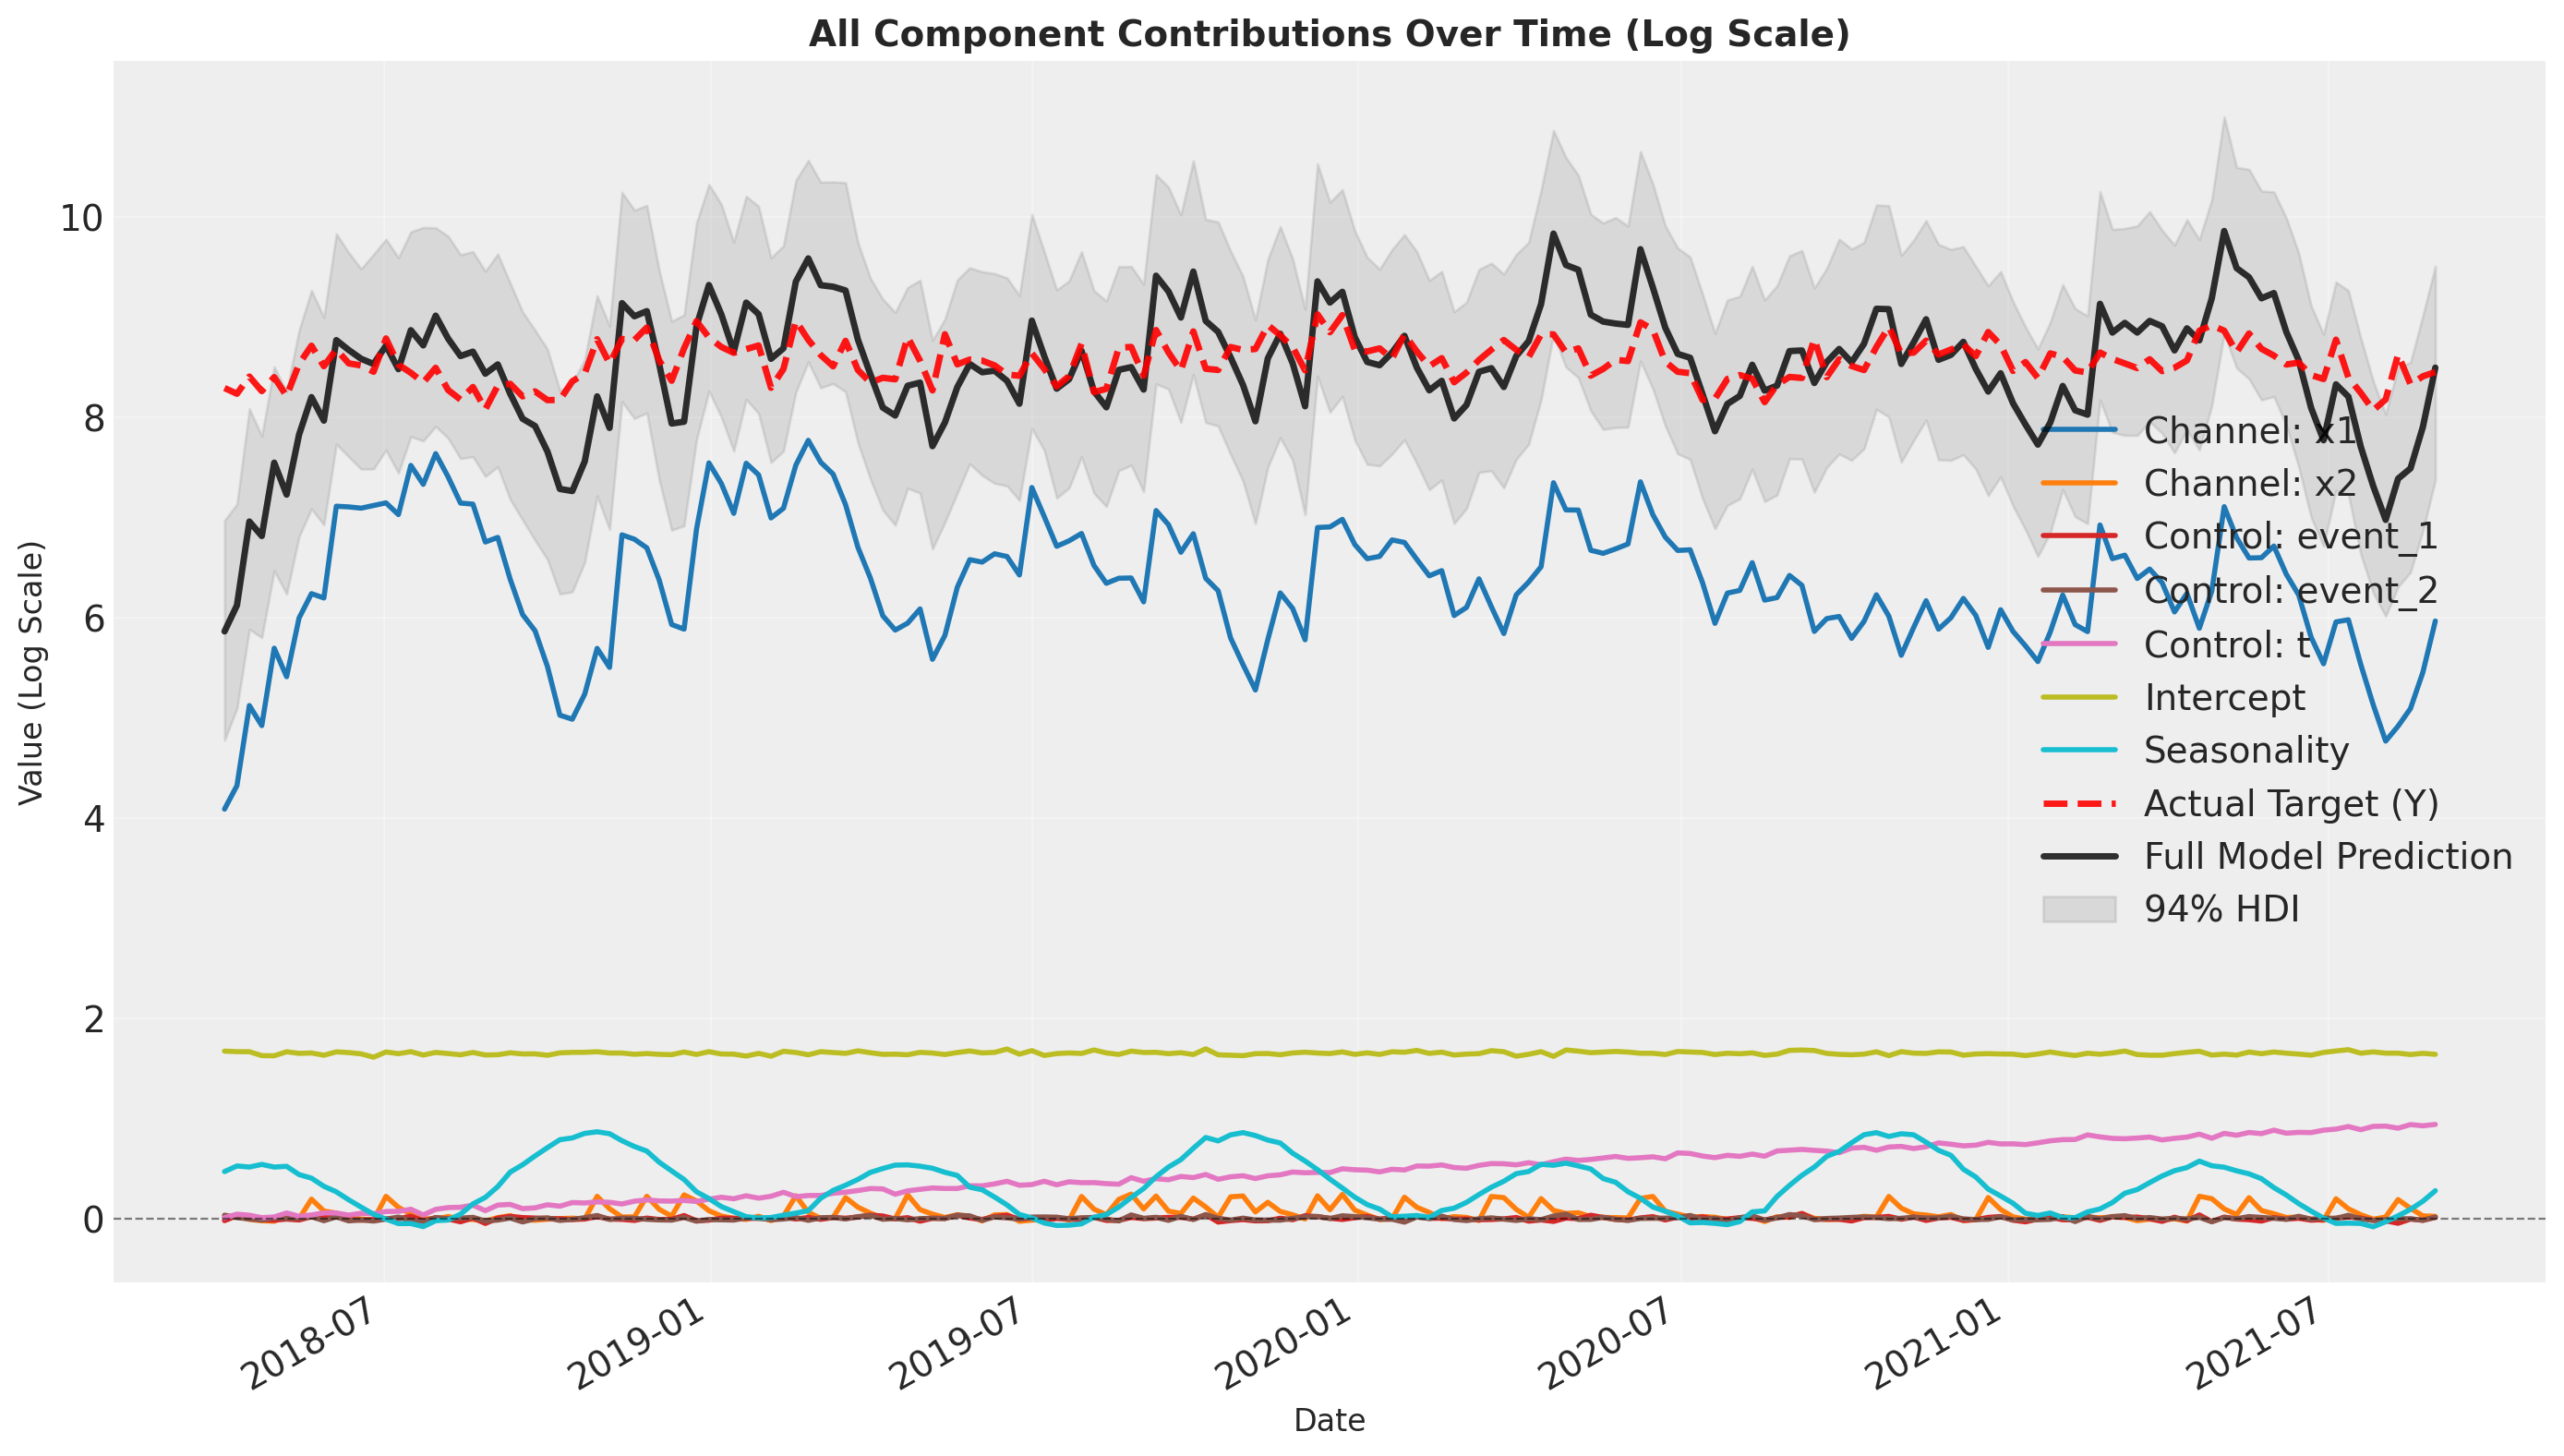

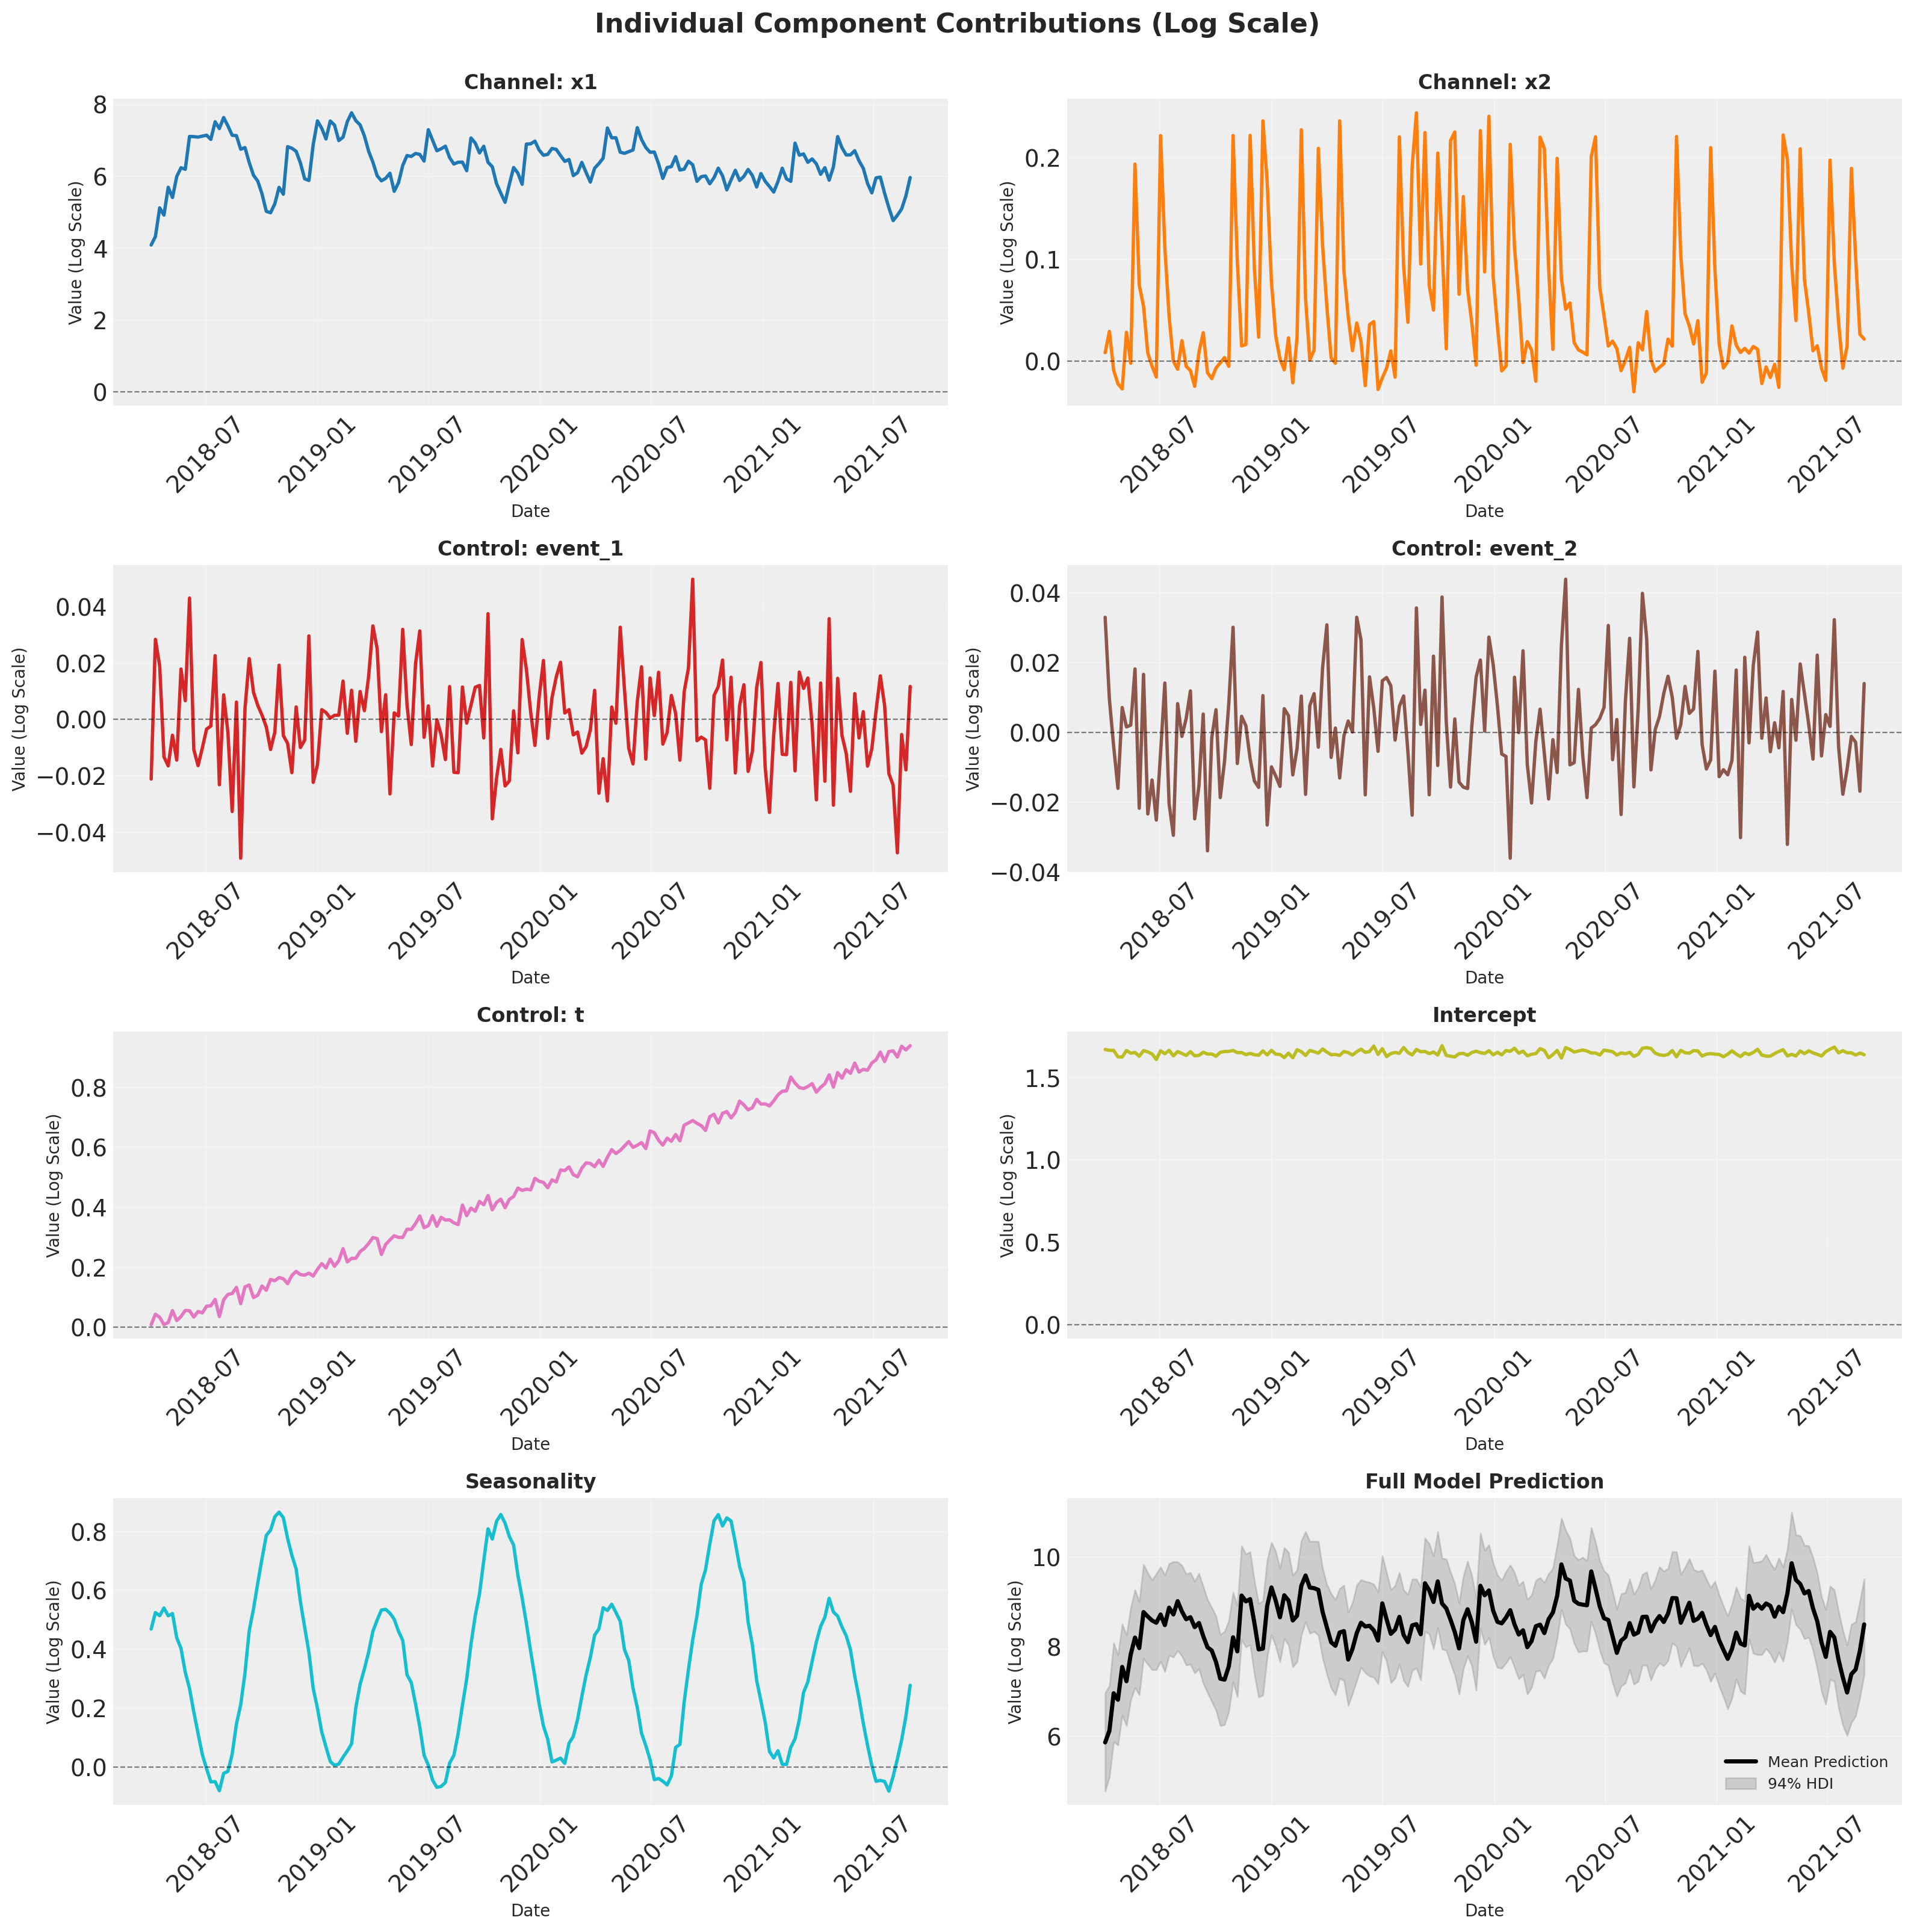

In [32]:
# Get contributions
contributions = get_individual_contributions(mmm, data, channel_cols=['x1', 'x2'], control_cols=['event_1', 'event_2', 't'])

# Plot with predictions (default)
fig_combined, fig_individual = plot_all_contributions(contributions, mmm=mmm, data=data)

In [33]:
contributions

{'dates': array(['2018-04-02T00:00:00.000000000', '2018-04-09T00:00:00.000000000',
        '2018-04-16T00:00:00.000000000', '2018-04-23T00:00:00.000000000',
        '2018-04-30T00:00:00.000000000', '2018-05-07T00:00:00.000000000',
        '2018-05-14T00:00:00.000000000', '2018-05-21T00:00:00.000000000',
        '2018-05-28T00:00:00.000000000', '2018-06-04T00:00:00.000000000',
        '2018-06-11T00:00:00.000000000', '2018-06-18T00:00:00.000000000',
        '2018-06-25T00:00:00.000000000', '2018-07-02T00:00:00.000000000',
        '2018-07-09T00:00:00.000000000', '2018-07-16T00:00:00.000000000',
        '2018-07-23T00:00:00.000000000', '2018-07-30T00:00:00.000000000',
        '2018-08-06T00:00:00.000000000', '2018-08-13T00:00:00.000000000',
        '2018-08-20T00:00:00.000000000', '2018-08-27T00:00:00.000000000',
        '2018-09-03T00:00:00.000000000', '2018-09-10T00:00:00.000000000',
        '2018-09-17T00:00:00.000000000', '2018-09-24T00:00:00.000000000',
        '2018-10-01T00:00:00.

In [34]:
contributions["channels"]["x1"]

<xarray.DataArray 'y' (date: 179, sample: 2000)> Size: 3MB
array([[4.36339797, 3.91429327, 4.12040551, ..., 4.31330337, 4.83731791,
        5.36209016],
       [6.17070864, 3.81468562, 3.93985553, ..., 3.52736051, 3.44601737,
        4.50449064],
       [4.82091929, 4.92982344, 6.28460798, ..., 4.23084021, 3.36330547,
        5.24905353],
       ...,
       [4.85120591, 3.2039237 , 6.00218246, ..., 6.24513699, 5.0394627 ,
        5.64026245],
       [7.70195489, 4.61738424, 5.28360577, ..., 6.69277361, 5.17263985,
        5.79246111],
       [6.4479592 , 6.26506944, 5.45302159, ..., 5.99947458, 5.02223828,
        6.46690991]], shape=(179, 2000))
Coordinates:
  * date     (date) datetime64[ns] 1kB 2018-04-02 2018-04-09 ... 2021-08-30
  * sample   (sample) object 16kB MultiIndex
  * chain    (sample) int64 16kB 0 0 0 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1 1 1 1 1
  * draw     (sample) int64 16kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

# ROAS

In [44]:
def calculate_roas(
    contributions,
    data,
    channel_cols=None,
    date_start=None,
    date_end=None,
    target_column='y'
):
    """
    Calculate ROAS (Return on Ad Spend) for channels based on contributions.

    This method implements the following steps:
    1. Calculate total contribution raw by summing ALL component contributions at each time t
    2. Calculate adjusted contributions by dividing each component's raw contribution by total
       contribution raw and multiplying by the actual target value (yt) at that time
    3. Calculate ROAS by dividing the sum of adjusted contributions by the sum of spend
    4. Calculate ROAS distribution across posterior samples for boxplot analysis

    Parameters
    ----------
    contributions : dict
        Dictionary returned by get_individual_contributions() containing:
        - 'dates': array of dates
        - 'channels': dict with channel contributions (xarray)
        - 'controls': dict with control contributions (xarray)
        - 'intercept': intercept contribution (xarray)
        - 'seasonality': seasonality contribution (xarray)
    data : pd.DataFrame
        Original data containing spend data and target column
    channel_cols : list, optional
        List of channel names to calculate ROAS for. If None, uses all channels in contributions.
    date_start, date_end : str or datetime, optional
        Start and end dates for the cumulative period. If None, uses all periods.
        Dates should match the format in contributions['dates'] or data date column.
    target_column : str, default='y'
        Name of the target variable column in data

    Returns
    -------
    dict
        Dictionary containing:
        - 'roas': dict with mean ROAS values for each channel {channel_name: roas_value}
        - 'adjusted_contributions_channels': dict with adjusted contribution arrays for channels {channel_name: array}
        - 'adjusted_contributions_all': dict with adjusted contributions for ALL components
        - 'total_contribution_raw': array of total raw contributions over time
        - 'spend': dict with total spend for each channel {channel_name: spend_value}
        - 'period': dict with start and end indices {'start': int, 'end': int}
        - 'cumulative_period': dict with date range info {'start_date': date, 'end_date': date, 'days': int}
        - 'roas_samples': dict with ROAS posterior samples for boxplot {channel_name: array(n_samples)}

    Notes
    -----
    ALL components (channels, controls, intercept, seasonality) are ALWAYS included in the
    total_contribution_raw calculation to ensure mathematical correctness. The channel_cols
    parameter only controls which channels you want ROAS calculated for (reporting purposes).
    """
    import numpy as np
    import pandas as pd

    # 1. Convert dates to period indices if provided
    dates_array = contributions['dates']

    if date_start is not None or date_end is not None:
        # Convert dates to pandas datetime for comparison
        dates_pd = pd.to_datetime(dates_array)
        mask = pd.Series(True, index=range(len(dates_pd)))

        if date_start is not None:
            date_start_pd = pd.to_datetime(date_start)
            mask &= (dates_pd >= date_start_pd)
        else:
            date_start_pd = dates_pd[0]

        if date_end is not None:
            date_end_pd = pd.to_datetime(date_end)
            mask &= (dates_pd <= date_end_pd)
        else:
            date_end_pd = dates_pd[-1]

        period_indices = np.where(mask)[0]

        if len(period_indices) == 0:
            raise ValueError(f"No data found for date range {date_start} to {date_end}")

        # Filter data by the same indices
        data_period = data.iloc[period_indices].copy()

        # Calculate cumulative period info
        cumulative_period = {
            'start_date': dates_pd[period_indices[0]],
            'end_date': dates_pd[period_indices[-1]],
            'days': len(period_indices)
        }
    else:
        data_period = data.copy()
        period_indices = np.arange(len(data))
        dates_pd = pd.to_datetime(dates_array)
        cumulative_period = {
            'start_date': dates_pd[0],
            'end_date': dates_pd[-1],
            'days': len(data)
        }

    # 2. Determine which channels to calculate ROAS for
    if channel_cols is None:
        channel_cols = list(contributions['channels'].keys())

    # 3. Calculate total contribution raw at each time t, preserving samples
    # IMPORTANT: ALWAYS include ALL components for mathematical correctness
    total_contribution_raw_samples = None

    # Store raw contributions for all components with samples preserved
    raw_contributions_all_samples = {}

    # Add ALL channel contributions (preserving samples)
    for channel_name, channel_contrib in contributions['channels'].items():
        # Extract the data for the selected period
        channel_contrib_period = channel_contrib[..., period_indices]

        # Stack chain and draw dimensions to get (n_samples, n_dates)
        dims = getattr(channel_contrib_period, 'dims', None)
        if dims and 'chain' in dims and 'draw' in dims:
            # Stack to (n_samples, n_dates)
            channel_samples = channel_contrib_period.stack(sample=('chain', 'draw'))
            channel_samples_array = np.asarray(channel_samples)
        else:
            # If no chain/draw dims, just convert to array
            channel_samples_array = np.asarray(channel_contrib_period)
            if channel_samples_array.ndim == 1:
                channel_samples_array = channel_samples_array[np.newaxis, :]

        # Store for later
        raw_contributions_all_samples[f'channel_{channel_name}'] = channel_samples_array

        if total_contribution_raw_samples is None:
            total_contribution_raw_samples = channel_samples_array.copy()
        else:
            total_contribution_raw_samples += channel_samples_array

    # Add ALL control contributions
    for control_name, control_contrib in contributions['controls'].items():
        control_contrib_period = control_contrib[..., period_indices]
        dims = getattr(control_contrib_period, 'dims', None)
        if dims and 'chain' in dims and 'draw' in dims:
            control_samples = control_contrib_period.stack(sample=('chain', 'draw'))
            control_samples_array = np.asarray(control_samples)
        else:
            control_samples_array = np.asarray(control_contrib_period)
            if control_samples_array.ndim == 1:
                control_samples_array = control_samples_array[np.newaxis, :]

        raw_contributions_all_samples[f'control_{control_name}'] = control_samples_array

        if total_contribution_raw_samples is None:
            total_contribution_raw_samples = control_samples_array.copy()
        else:
            total_contribution_raw_samples += control_samples_array

    # Add intercept contribution
    intercept_contrib = contributions['intercept']
    intercept_contrib_period = intercept_contrib[..., period_indices]
    dims = getattr(intercept_contrib_period, 'dims', None)
    if dims and 'chain' in dims and 'draw' in dims:
        intercept_samples = intercept_contrib_period.stack(sample=('chain', 'draw'))
        intercept_samples_array = np.asarray(intercept_samples)
    else:
        intercept_samples_array = np.asarray(intercept_contrib_period)
        if intercept_samples_array.ndim == 1:
            intercept_samples_array = intercept_samples_array[np.newaxis, :]

    raw_contributions_all_samples['intercept'] = intercept_samples_array

    if total_contribution_raw_samples is None:
        total_contribution_raw_samples = intercept_samples_array.copy()
    else:
        total_contribution_raw_samples += intercept_samples_array

    # Add seasonality contribution
    seasonality_contrib = contributions['seasonality']
    seasonality_contrib_period = seasonality_contrib[..., period_indices]
    dims = getattr(seasonality_contrib_period, 'dims', None)
    if dims and 'chain' in dims and 'draw' in dims:
        seasonality_samples = seasonality_contrib_period.stack(sample=('chain', 'draw'))
        seasonality_samples_array = np.asarray(seasonality_samples)
    else:
        seasonality_samples_array = np.asarray(seasonality_contrib_period)
        if seasonality_samples_array.ndim == 1:
            seasonality_samples_array = seasonality_samples_array[np.newaxis, :]

    raw_contributions_all_samples['seasonality'] = seasonality_samples_array

    if total_contribution_raw_samples is None:
        total_contribution_raw_samples = seasonality_samples_array.copy()
    else:
        total_contribution_raw_samples += seasonality_samples_array

    # 4. Get actual target values for the period
    y_actual = data_period[target_column].values

    # 5. Calculate adjusted contributions for ALL components (mean across samples for plotting)
    # Calculate mean total contribution for adjustment
    total_contribution_raw = total_contribution_raw_samples.mean(axis=0)

    adjusted_contributions_all = {}

    for component_name, raw_contrib_samples in raw_contributions_all_samples.items():
        # Use mean across samples for the plotting contributions
        raw_contrib = raw_contrib_samples.mean(axis=0)

        # Calculate adjusted contribution:
        # adjusted_contrib_t = (raw_contrib_t / total_contrib_raw_t) * y_actual_t
        # Handle division by zero
        with np.errstate(divide='ignore', invalid='ignore'):
            adjustment_factor = np.where(
                total_contribution_raw != 0,
                raw_contrib / total_contribution_raw,
                0
            )

        adjusted_contrib = adjustment_factor * y_actual
        adjusted_contributions_all[component_name] = adjusted_contrib

    # 6. Extract adjusted contributions for channels only (for reporting)
    adjusted_contributions_channels = {}
    for channel in channel_cols:
        if channel not in contributions['channels']:
            raise ValueError(f"Channel '{channel}' not found in contributions")

        adjusted_contributions_channels[channel] = adjusted_contributions_all[f'channel_{channel}']

    # 7. Calculate ROAS for each channel (mean value for reporting)
    roas_values = {}
    spend_values = {}

    for channel in channel_cols:
        # Sum of adjusted contributions over the period
        total_contribution = np.sum(adjusted_contributions_channels[channel])

        # Sum of spend over the period
        total_spend = data_period[channel].sum()
        spend_values[channel] = total_spend

        # ROAS = total contribution / total spend
        if total_spend > 0:
            roas = total_contribution / total_spend
        else:
            roas = np.nan

        roas_values[channel] = roas

    # 8. Calculate ROAS samples for boxplot (across all posterior samples)
    roas_samples = {}

    for channel in channel_cols:
        # Get channel contribution samples (n_samples, n_dates)
        channel_contrib_samples = raw_contributions_all_samples[f'channel_{channel}']

        # Calculate adjusted contributions per sample
        # adjusted_contrib[s,t] = (raw_contrib[s,t] / total_contrib_raw[s,t]) * y_actual[t]
        with np.errstate(divide='ignore', invalid='ignore'):
            adjustment_factor_samples = np.where(
                total_contribution_raw_samples != 0,
                channel_contrib_samples / total_contribution_raw_samples,
                0
            )

        adjusted_contrib_samples = adjustment_factor_samples * y_actual[np.newaxis, :]  # broadcast y_actual

        # Sum over time for each sample
        total_contribution_samples = np.sum(adjusted_contrib_samples, axis=1)

        # Calculate ROAS per sample
        total_spend = data_period[channel].sum()

        if total_spend > 0:
            roas_sample_values = total_contribution_samples / total_spend
        else:
            roas_sample_values = np.full(len(total_contribution_samples), np.nan)

        roas_samples[channel] = roas_sample_values

    # 9. Return results
    return {
        'roas': roas_values,
        'adjusted_contributions_channels': adjusted_contributions_channels,
        'adjusted_contributions_all': adjusted_contributions_all,
        'total_contribution_raw': total_contribution_raw,
        'spend': spend_values,
        'period': {
            'start': period_indices[0] if len(period_indices) > 0 else None,
            'end': period_indices[-1] if len(period_indices) > 0 else None
        },
        'cumulative_period': cumulative_period,
        'roas_samples': roas_samples
    }


In [45]:
# Step 1: Calculate ROAS with the new function using date range
roas_results_all = calculate_roas(
    contributions=contributions,
    data=data,
    channel_cols=['x1', 'x2'],
    # date_start='2019-06-09',  # Replace with your desired start date
    # date_end='2022-11-27',    # Replace with your desired end date
    target_column='y'
)

# Step 2: Display the results
print("=" * 80)
print("ROAS CALCULATION RESULTS")
print("=" * 80)
print("\nROAS by Channel:")
print("-" * 40)
for channel, roas in roas_results_all['roas'].items():
    print(f"  {channel}: {roas:.4f} (${roas:.2f} revenue per $1 spent)")

print("\n\nTotal Spend by Channel:")
print("-" * 40)
for channel, spend in roas_results_all['spend'].items():
    print(f"  {channel}: ${spend:,.2f}")

print("\n\nTotal Adjusted Contribution by Channel:")
print("-" * 40)
for channel, contrib in roas_results_all['adjusted_contributions_channels'].items():
    total_contrib = np.sum(contrib)
    print(f"  {channel}: ${total_contrib:,.2f}")

print("\n\nVerification - Sum of ALL Adjusted Contributions:")
print("-" * 40)
period_start = roas_results_all['period']['start']
period_end = roas_results_all['period']['end']
sum_all_adjusted = sum([np.sum(contrib) for contrib in roas_results_all['adjusted_contributions_all'].values()])
sum_actual_y = data.iloc[period_start:period_end+1]['y'].sum()
print(f"  Sum of all adjusted contributions: ${sum_all_adjusted:,.2f}")
print(f"  Sum of actual Y (for selected period): ${sum_actual_y:,.2f}")
print(f"  Difference: ${abs(sum_all_adjusted - sum_actual_y):,.2f}")
print(f"  Match: {'YES ✓' if abs(sum_all_adjusted - sum_actual_y) < 0.01 else 'NO ✗'}")

print("\n" + "=" * 80)

ROAS CALCULATION RESULTS

ROAS by Channel:
----------------------------------------
  x1: 122.2229 ($122.22 revenue per $1 spent)
  x2: 2.2260 ($2.23 revenue per $1 spent)


Total Spend by Channel:
----------------------------------------
  x1: $5,532.56
  x2: $2,897.11


Total Adjusted Contribution by Channel:
----------------------------------------
  x1: $676,205.49
  x2: $6,448.96


Verification - Sum of ALL Adjusted Contributions:
----------------------------------------
  Sum of all adjusted contributions: $946,005.62
  Sum of actual Y (for selected period): $946,005.62
  Difference: $0.00
  Match: YES ✓



In [47]:
def plot_roas_analysis(roas_results, contributions, data, confidence_intervals=(0.85, 0.90)):
    """
    Visualize ROAS analysis results.

    Shows adjusted contributions, ROAS by channel, and ROAS distribution boxplot.

    Parameters
    ----------
    roas_results : dict
        Results from calculate_roas()
    contributions : dict
        Original contributions dictionary
    data : pd.DataFrame
        Original data with dates
    confidence_intervals : tuple of float, default=(0.85, 0.90)
        Two confidence levels to display in statistics printout.
        For example, (0.85, 0.90) will show 85% CI (7.5%-92.5%) and 90% CI (5%-95%).
        Default shows both 85% and 90% confidence intervals.

    Returns
    -------
    tuple
        (fig1, fig2, fig3) - Three matplotlib figure objects
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    # Validate confidence_intervals
    if not isinstance(confidence_intervals, tuple) or len(confidence_intervals) != 2:
        raise ValueError("confidence_intervals must be a tuple of exactly 2 values")

    for ci in confidence_intervals:
        if not 0 < ci < 1:
            raise ValueError(f"Confidence interval {ci} must be between 0 and 1")

    # Sort to ensure smaller CI is first
    ci1, ci2 = sorted(confidence_intervals)

    # Get dates for the period
    period_start = roas_results['period']['start']
    period_end = roas_results['period']['end']
    dates = contributions['dates'][period_start:period_end+1]

    # Get actual target values
    y_actual = data.iloc[period_start:period_end+1]['y'].values

    # Get cumulative period info
    cumulative_period = roas_results.get('cumulative_period', {})
    start_date = cumulative_period.get('start_date', 'N/A')
    end_date = cumulative_period.get('end_date', 'N/A')
    days = cumulative_period.get('days', 'N/A')

    # Format dates for display
    if hasattr(start_date, 'strftime'):
        start_date_str = start_date.strftime('%Y-%m-%d')
        end_date_str = end_date.strftime('%Y-%m-%d')
    else:
        start_date_str = str(start_date)
        end_date_str = str(end_date)

    # ============================================================================
    # Print cumulative period and ROAS statistics
    # ============================================================================
    print("=" * 80)
    print(f"ROAS Analysis - Cumulative Period: {start_date_str} to {end_date_str} ({days} days)")
    print("=" * 80)
    print()

    # Calculate and print ROAS statistics from samples
    if 'roas_samples' in roas_results:
        # Calculate percentiles for both confidence intervals
        lower1 = (1 - ci1) / 2 * 100  # e.g., 7.5% for 85% CI
        upper1 = (1 + ci1) / 2 * 100  # e.g., 92.5% for 85% CI
        lower2 = (1 - ci2) / 2 * 100  # e.g., 5% for 90% CI
        upper2 = (1 + ci2) / 2 * 100  # e.g., 95% for 90% CI

        print("Channel ROAS Statistics:")
        print("-" * 80)

        for channel, roas_samples in roas_results['roas_samples'].items():
            # Calculate percentiles for both CIs
            ci1_lower = np.percentile(roas_samples, lower1)
            ci1_upper = np.percentile(roas_samples, upper1)
            ci2_lower = np.percentile(roas_samples, lower2)
            ci2_upper = np.percentile(roas_samples, upper2)
            median = np.percentile(roas_samples, 50)
            mean = np.mean(roas_samples)

            print(f"  {channel}:")
            print(f"    - Lower bound {int(ci2*100)}% CI ({lower2:.1f}%): {ci2_lower:.2f}")
            print(f"    - Lower bound {int(ci1*100)}% CI ({lower1:.1f}%): {ci1_lower:.2f}")
            print(f"    - Median (50%): {median:.2f}")
            print(f"    - Mean: {mean:.2f}")
            print(f"    - Upper bound {int(ci1*100)}% CI ({upper1:.1f}%): {ci1_upper:.2f}")
            print(f"    - Upper bound {int(ci2*100)}% CI ({upper2:.1f}%): {ci2_upper:.2f}")
            print()

    print("=" * 80)
    print()

    # ============================================================================
    # FIGURE 1: Adjusted Contributions + ROAS
    # ============================================================================
    fig1, axes = plt.subplots(2, 1, figsize=(14, 10))

    # ============================================================================
    # Plot 1: ADJUSTED Contributions Over Time - ALL COMPONENTS (with actual Y)
    # ============================================================================
    ax = axes[0]

    # Define colors for different component types
    channel_colors = plt.cm.Set1(np.arange(10))

    # Plot adjusted contributions for ALL components
    color_idx = 0
    for component_name, adj_contrib in roas_results['adjusted_contributions_all'].items():
        # Parse component name for better labeling
        if component_name.startswith('channel_'):
            label = component_name.replace('channel_', '') + ' (channel)'
            color = channel_colors[color_idx % len(channel_colors)]
            color_idx += 1
            linewidth = 2
            alpha = 0.8
        elif component_name.startswith('control_'):
            label = component_name.replace('control_', '') + ' (control)'
            color = 'gray'
            linewidth = 1.5
            alpha = 0.5
        elif component_name == 'intercept':
            label = 'Intercept'
            color = 'purple'
            linewidth = 1.5
            alpha = 0.6
        elif component_name == 'seasonality':
            label = 'Seasonality'
            color = 'orange'
            linewidth = 1.5
            alpha = 0.6
        else:
            label = component_name
            color = 'black'
            linewidth = 1
            alpha = 0.5

        ax.plot(dates, adj_contrib, label=label, linewidth=linewidth, alpha=alpha, color=color)

    # Calculate sum of ALL adjusted contributions
    sum_adjusted_all = np.zeros_like(y_actual)
    for adj_contrib in roas_results['adjusted_contributions_all'].values():
        sum_adjusted_all += adj_contrib

    # Plot sum of ALL adjusted contributions
    ax.plot(dates, sum_adjusted_all, label='Sum of ALL Adjusted',
            linewidth=3, color='green', linestyle='-', alpha=0.9, zorder=10)

    # Plot actual target Y
    ax.plot(dates, y_actual, label='Actual Y (target)', linewidth=3,
            color='black', linestyle='--', alpha=0.9, zorder=10)

    ax.set_xlabel('Date', fontsize=11)
    ax.set_ylabel('Contribution', fontsize=11)
    ax.set_title('ADJUSTED Contributions (ALL COMPONENTS) vs Actual Target (Y)\n(Notice: Green line (sum of adjusted) = Black dashed line (Actual Y))',
                 fontsize=13, fontweight='bold')
    ax.legend(loc='best', ncol=2, fontsize=9)
    ax.grid(alpha=0.3)

    # ============================================================================
    # Plot 2: ROAS Bar Chart
    # ============================================================================
    ax = axes[1]
    channels = list(roas_results['roas'].keys())
    roas_values = [roas_results['roas'][ch] for ch in channels]
    colors = plt.cm.Set2(np.arange(len(channels)))
    bars = ax.bar(channels, roas_values, color=colors, edgecolor='black', linewidth=1.5)

    # Add value labels on bars
    for bar, value in zip(bars, roas_values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{value:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

    ax.set_xlabel('Channel', fontsize=11)
    ax.set_ylabel('ROAS ($ revenue per $ spent)', fontsize=11)
    ax.set_title('Return on Ad Spend (ROAS) by Channel', fontsize=13, fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

    plt.tight_layout()

    # ============================================================================
    # FIGURE 2: Spend vs Contribution Comparison
    # ============================================================================
    fig2, ax = plt.subplots(figsize=(10, 6))

    channels = list(roas_results['roas'].keys())
    x = np.arange(len(channels))
    width = 0.35

    spend_values = [roas_results['spend'][ch] for ch in channels]
    contrib_values = [np.sum(roas_results['adjusted_contributions_channels'][ch]) for ch in channels]

    bars1 = ax.bar(x - width/2, spend_values, width, label='Total Spend',
                   color='steelblue', edgecolor='black')
    bars2 = ax.bar(x + width/2, contrib_values, width, label='Total Adjusted Contribution',
                   color='coral', edgecolor='black')

    ax.set_xlabel('Channel', fontsize=12)
    ax.set_ylabel('Amount ($)', fontsize=12)
    ax.set_title('Total Spend vs Total Adjusted Contribution by Channel',
                 fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(channels)
    ax.legend()
    ax.grid(alpha=0.3, axis='y')

    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'${height:,.0f}',
                    ha='center', va='bottom', fontsize=9)

    plt.tight_layout()

    # ============================================================================
    # FIGURE 3: ROAS Boxplot (NEW)
    # ============================================================================
    if 'roas_samples' in roas_results:
        fig3, ax = plt.subplots(figsize=(12, 7))

        channels = list(roas_results['roas_samples'].keys())
        roas_samples_list = [roas_results['roas_samples'][ch] for ch in channels]

        # Create boxplot
        bp = ax.boxplot(roas_samples_list, labels=channels, patch_artist=True,
                        showmeans=True, meanline=False,
                        medianprops=dict(color='red', linewidth=2),
                        meanprops=dict(marker='D', markerfacecolor='green',
                                      markersize=8, markeredgecolor='darkgreen'),
                        boxprops=dict(facecolor='lightblue', alpha=0.7),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5),
                        flierprops=dict(marker='o', markerfacecolor='gray',
                                       markersize=5, alpha=0.5))

        ax.set_xlabel('Channel', fontsize=12, fontweight='bold')
        ax.set_ylabel('ROAS ($ revenue per $ spent)', fontsize=12, fontweight='bold')
        ax.set_title(f'ROAS Distribution by Channel\nCumulative Period: {start_date_str} to {end_date_str} ({days} days)',
                     fontsize=14, fontweight='bold')
        ax.grid(alpha=0.3, axis='y')

        # Add legend
        from matplotlib.patches import Patch
        from matplotlib.lines import Line2D
        legend_elements = [
            Line2D([0], [0], color='red', linewidth=2, label='Median'),
            Line2D([0], [0], marker='D', color='w', markerfacecolor='green',
                   markersize=8, markeredgecolor='darkgreen', label='Mean'),
            Patch(facecolor='lightblue', alpha=0.7, edgecolor='black', label='IQR (25%-75%)'),
            Line2D([0], [0], color='black', linewidth=1.5, label=f'Whiskers ({int(ci2*100)}% CI: {lower2:.1f}%-{upper2:.1f}%)')
        ]
        ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

        plt.tight_layout()
    else:
        # If no samples available, create empty figure
        fig3 = None

    return fig1, fig2, fig3


ROAS Analysis - Cumulative Period: 2018-04-02 to 2021-08-30 (179 days)

Channel ROAS Statistics:
--------------------------------------------------------------------------------
  x1:
    - Lower bound 90% CI (5.0%): 57.19
    - Lower bound 85% CI (7.5%): 89.53
    - Median (50%): 148.30
    - Mean: 203.53
    - Upper bound 85% CI (92.5%): 245.24
    - Upper bound 90% CI (95.0%): 329.91

  x2:
    - Lower bound 90% CI (5.0%): -103.80
    - Lower bound 85% CI (7.5%): -60.51
    - Median (50%): -8.19
    - Mean: -39.85
    - Upper bound 85% CI (92.5%): 21.17
    - Upper bound 90% CI (95.0%): 35.79




C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\3577155851.py:189: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\3577155851.py:225: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\3577155851.py:237: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(roas_samples_list, labels=channels, patch_artist=True,
C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\3577155851.py:266: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


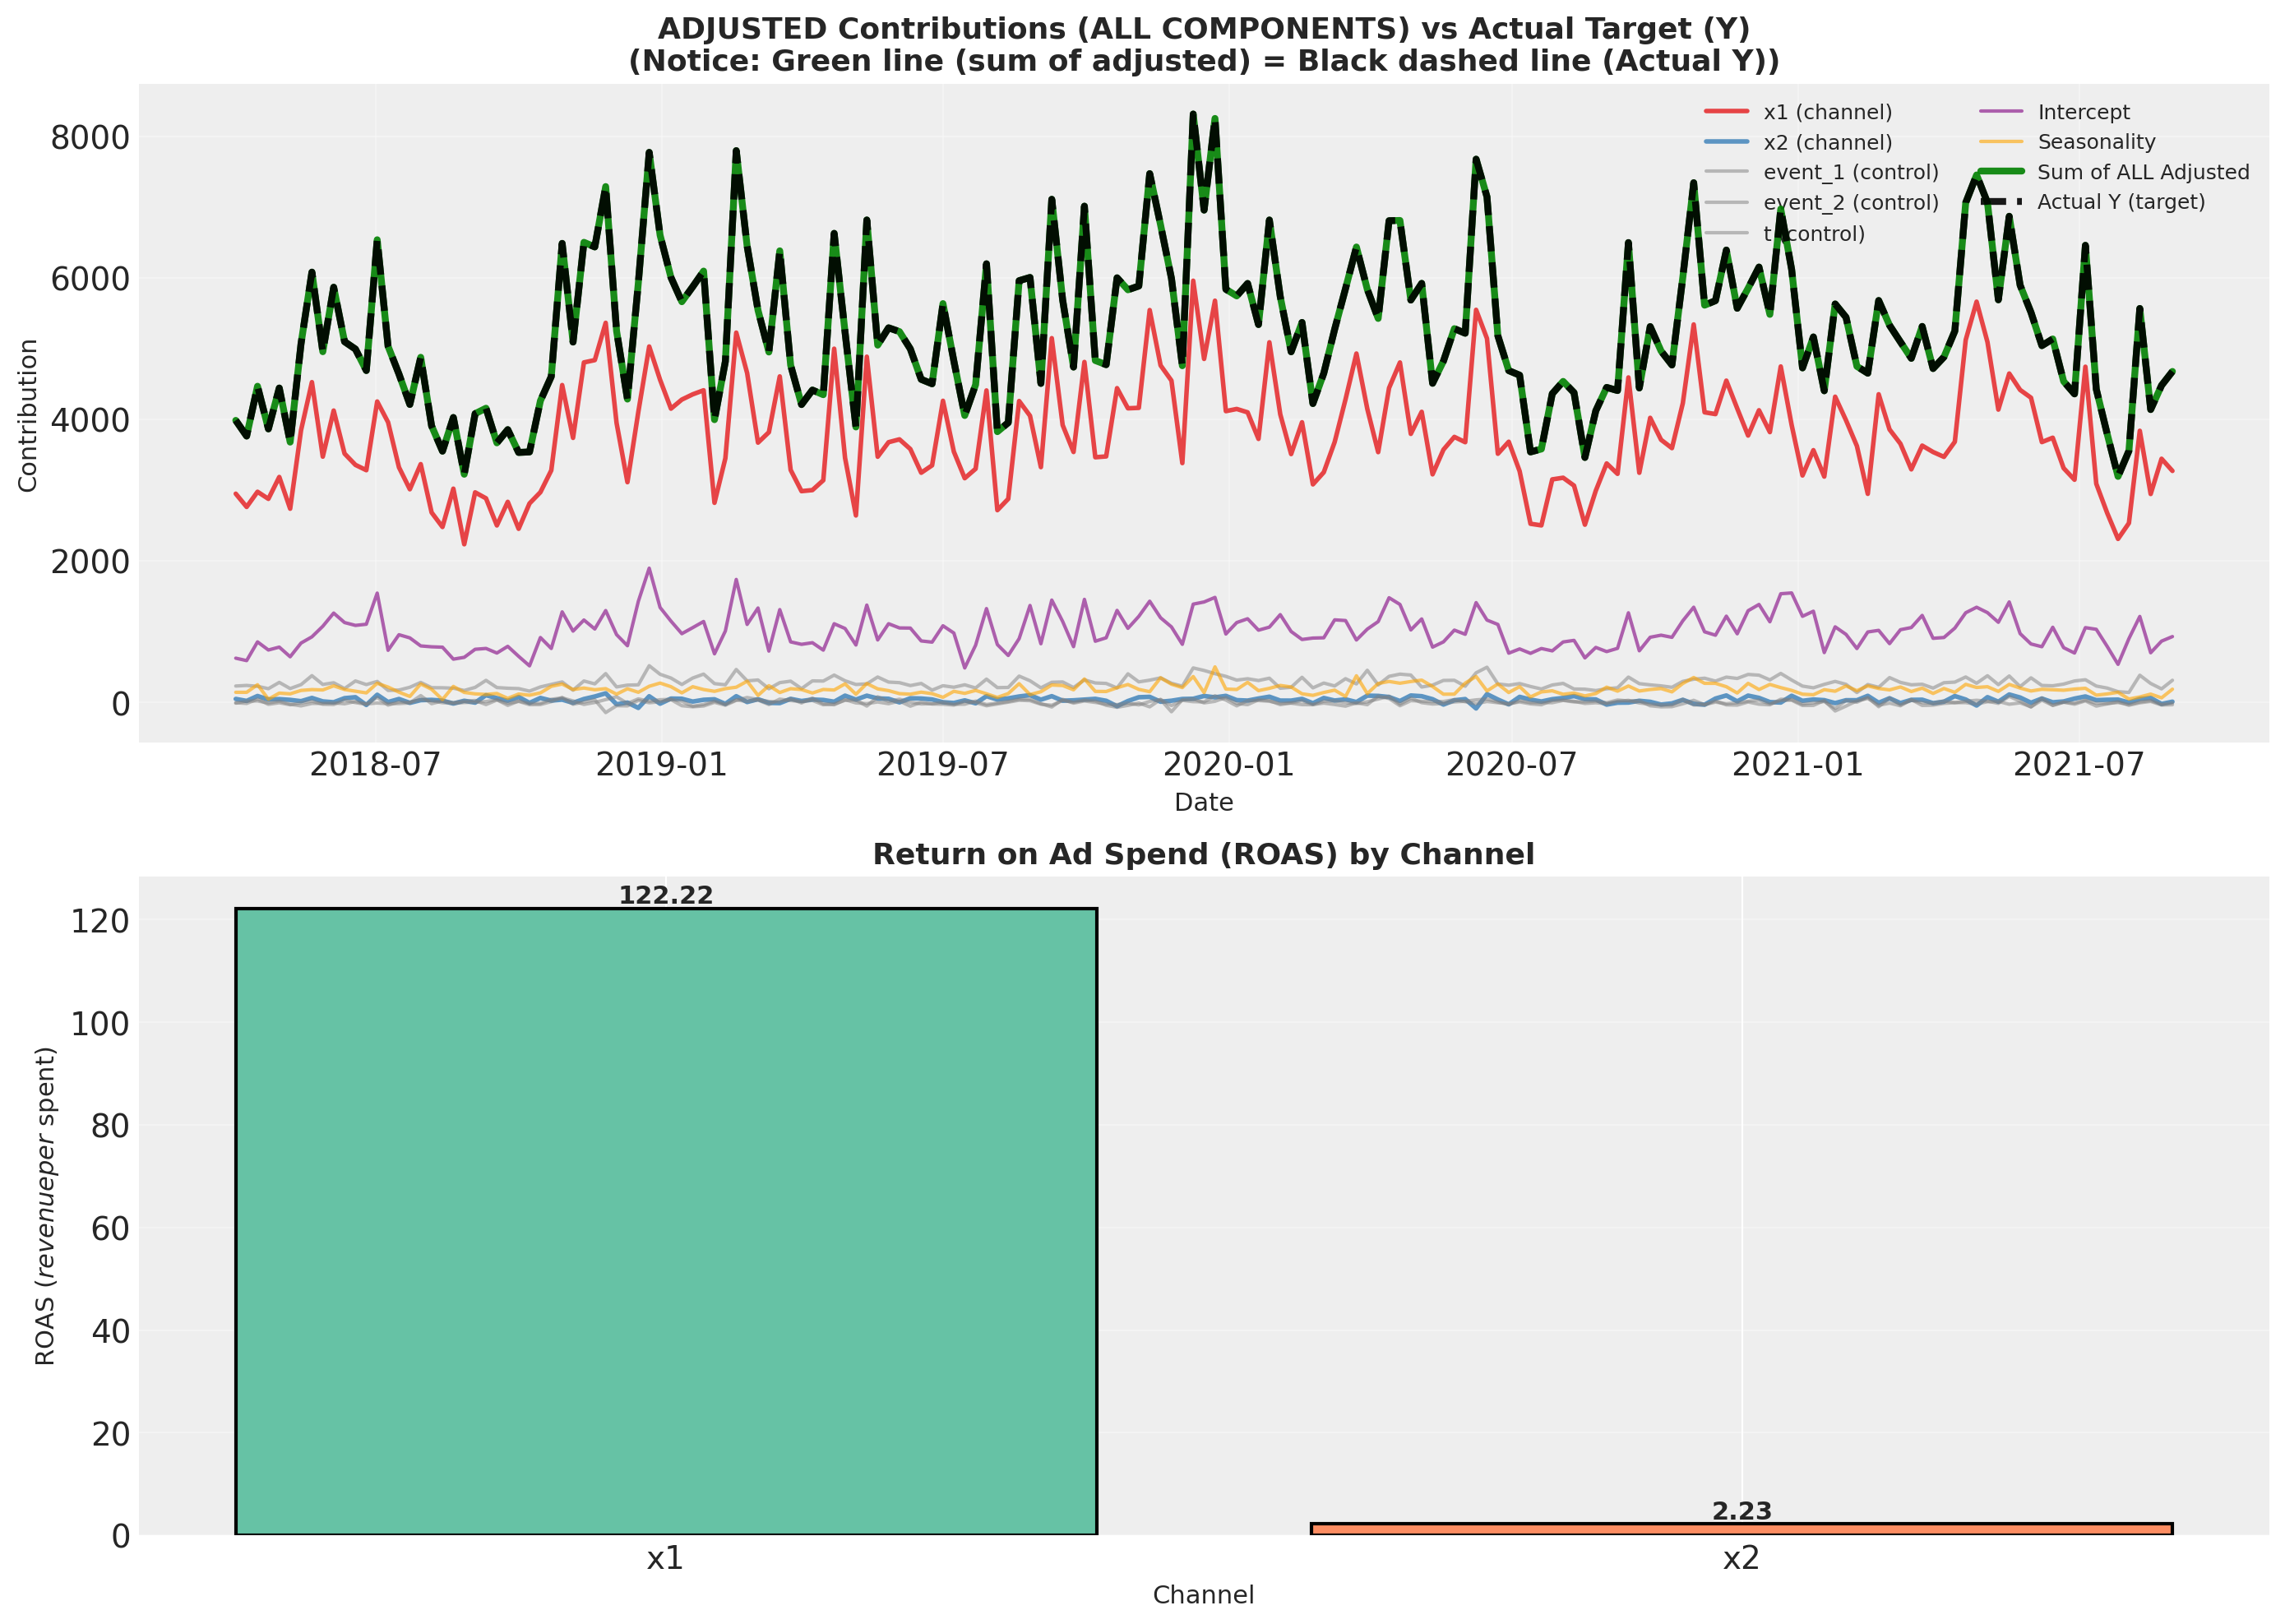

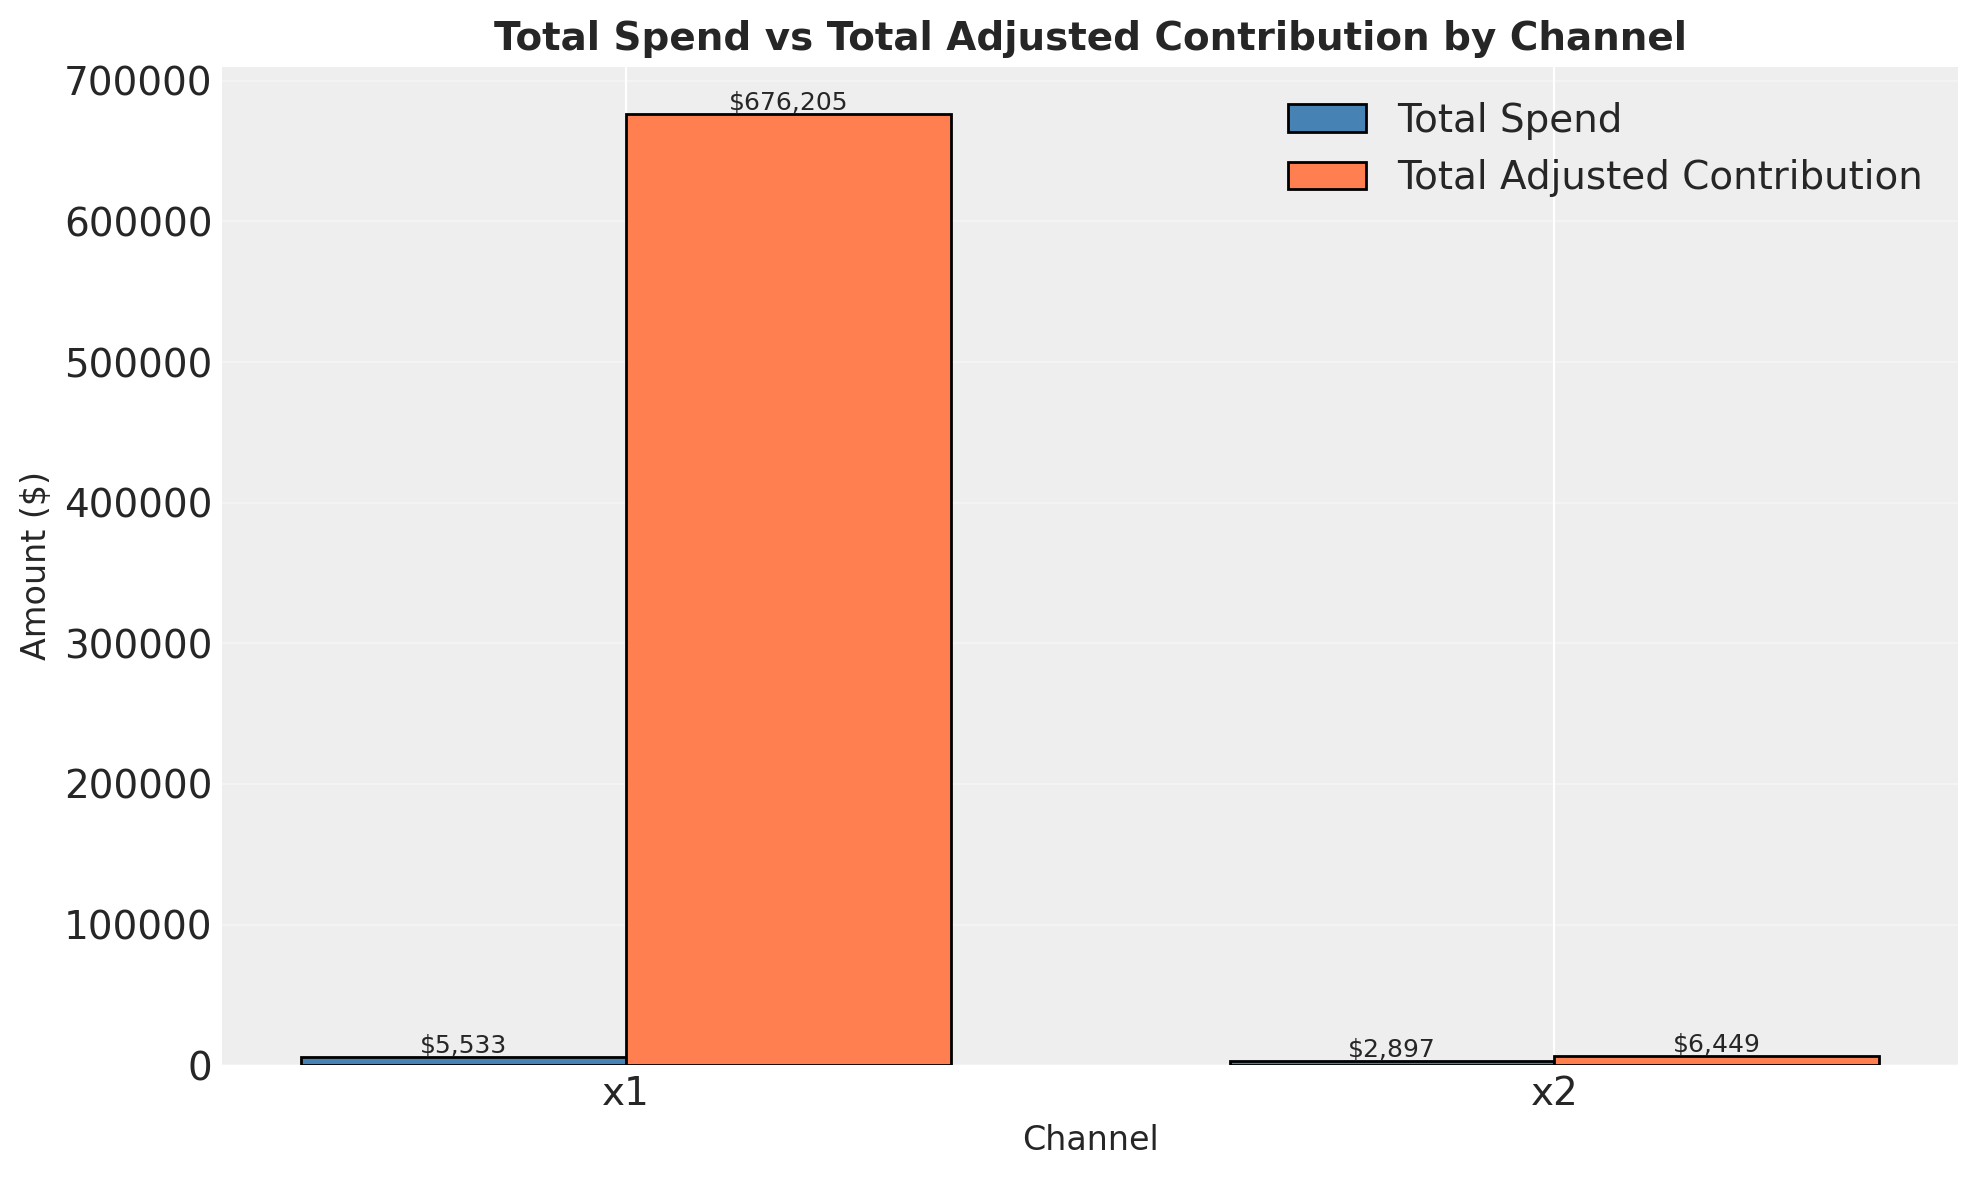

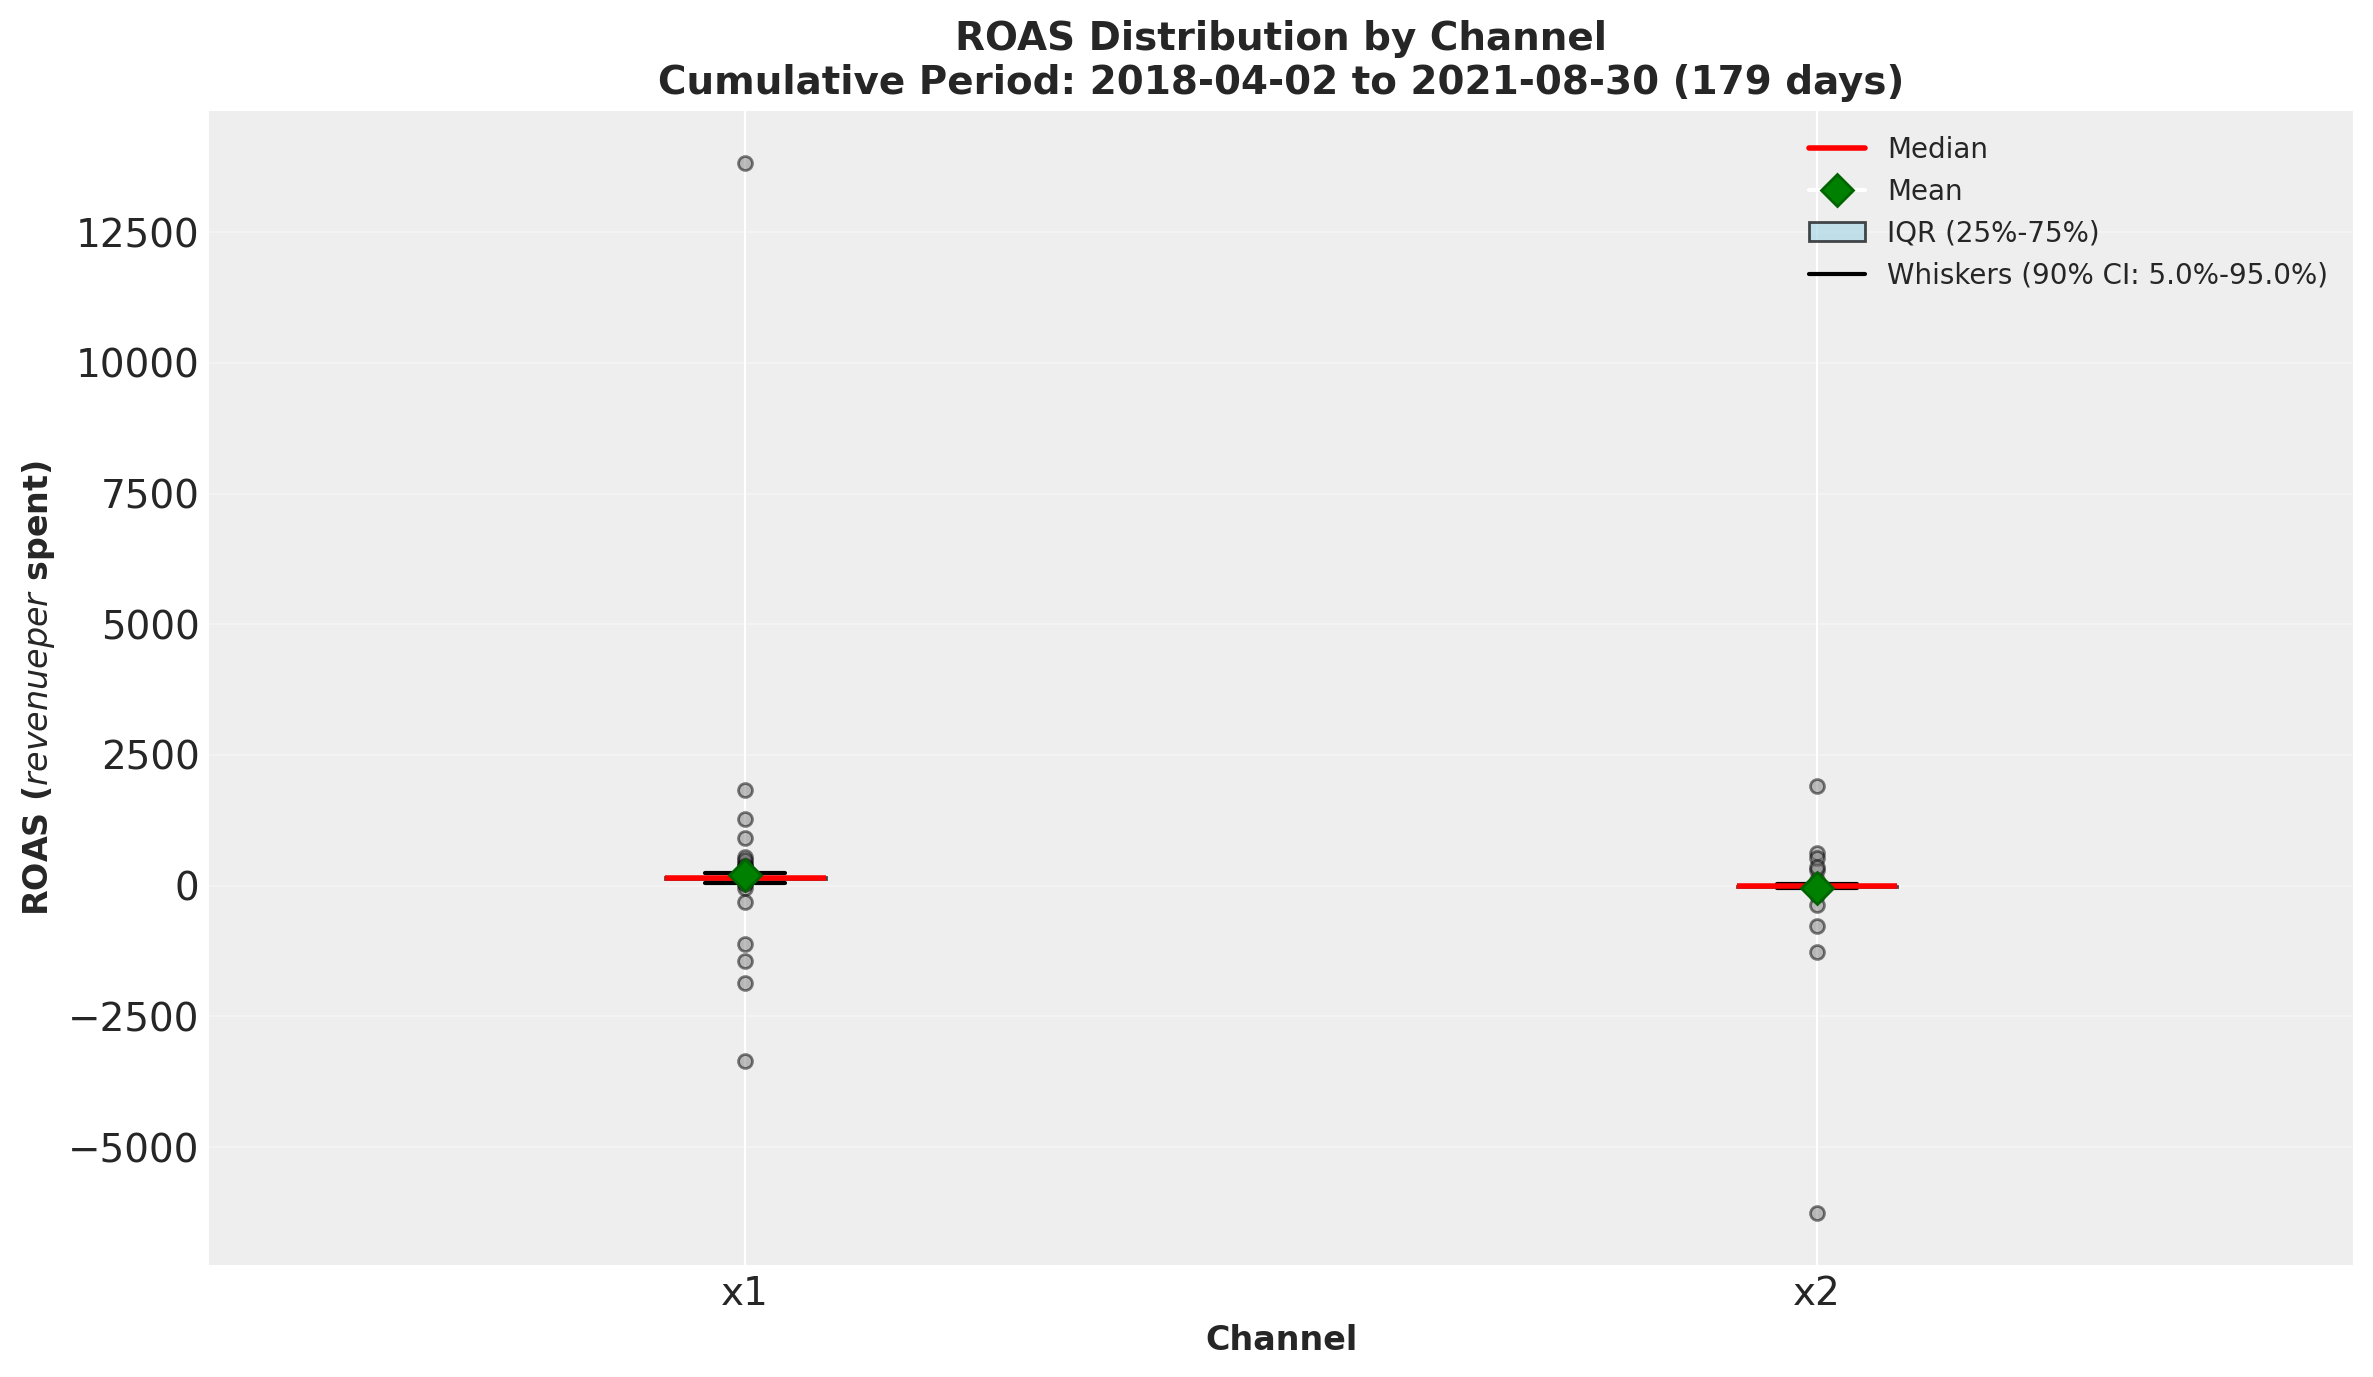

In [48]:
# Plot ROAS analysis (now returns 3 figures including boxplot)
fig1, fig2, fig3 = plot_roas_analysis(roas_results_all, contributions, data)
plt.show()

**Business use cases**

*Pros*

- Campaign-level evaluation: "What was the overall ROAS for Q4 2024?"
- Budget allocation decisions: "Which channel gave the best total return?"
- Executive reporting: Simple to communicate, single-number KPIs
- Period comparisons: Compare Q1 vs Q2 aggregate performance 

*Limitations*

- Hides temporal dynamics (seasonality, trends, diminishing returns)
- Can't identify when performance changed
- May mask optimization opportunities within the period
- No visibility into ROAS volatility/uncertainty


In [39]:
def calculate_roas_time_series(
    contributions,
    data,
    channel_cols=None,
    t_start=None,
    t_end=None,
    target_column='y'
):
    """
    Calculate per-period ROAS preserving all posterior samples for uncertainty quantification.
    
    This function calculates ROAS (Return on Ad Spend) for each time period while preserving
    the full posterior distribution from the Bayesian model. This allows us to visualize
    ROAS over time with confidence intervals.
    
    Parameters
    ----------
    contributions : dict
        Dictionary returned by get_individual_contributions() containing:
        - 'dates': array of dates
        - 'channels': dict with channel contributions (xarray with sample dimension)
        - 'controls': dict with control contributions (xarray with sample dimension)
        - 'intercept': intercept contribution (xarray with sample dimension)
        - 'seasonality': seasonality contribution (xarray with sample dimension)
    data : pd.DataFrame
        Original data containing spend data and target column
    channel_cols : list, optional
        List of channel names to calculate ROAS for. If None, uses all channels.
    t_start, t_end : int, optional
        Period range to select. If None, uses all periods.
    target_column : str, default='y'
        Name of the target variable column in data
    
    Returns
    -------
    dict
        Dictionary containing:
        - 'roas_time_series': dict with ROAS arrays {channel_name: array(n_samples, n_dates)}
        - 'dates': array of dates for the period
        - 'spend': dict with spend arrays {channel_name: array(n_dates)}
        - 'channel_cols': list of channels processed
    
    Notes
    -----
    - Preserves ALL posterior samples (chain, draw) for uncertainty quantification
    - Zero spend periods result in NaN ROAS values
    - All components are included in total contribution calculation
    """
    import numpy as np
    import pandas as pd
    import xarray as xr
    
    # 1. Filter data by period if specified
    if t_start is not None or t_end is not None:
        mask = pd.Series(True, index=data.index)
        if t_start is not None:
            mask &= (data['t'] >= t_start)
        if t_end is not None:
            mask &= (data['t'] <= t_end)
        data_period = data[mask].copy()
        period_indices = np.where(mask)[0]
    else:
        data_period = data.copy()
        period_indices = np.arange(len(data))
    
    # 2. Determine which channels to calculate ROAS for
    if channel_cols is None:
        channel_cols = list(contributions['channels'].keys())
    
    # 3. Get dates for the period
    dates = contributions['dates'][period_indices]
    
    # 4. Get actual target values for the period
    y_actual = data_period[target_column].values  # shape: (n_dates,)
    
    # 5. Calculate total contribution raw per sample, per time
    # We need to preserve the sample dimension (chain, draw)
    
    total_contribution_raw = None
    raw_contributions_channels = {}  # Store raw contributions for channels
    
    # Helper function to extract and reshape contributions
    def extract_samples(contrib_xr, period_indices):
        """Extract contribution data preserving sample dimension."""
        # Select the time period
        contrib_period = contrib_xr[..., period_indices]
        
        # Check if it's an xarray with dims
        if hasattr(contrib_period, 'dims'):
            # Stack chain and draw into a single 'sample' dimension
            if 'chain' in contrib_period.dims and 'draw' in contrib_period.dims:
                contrib_stacked = contrib_period.stack(sample=('chain', 'draw'))
                # Result should be (sample, date)
                if 'date' in contrib_stacked.dims:
                    contrib_array = contrib_stacked.transpose('sample', 'date').values
                else:
                    contrib_array = contrib_stacked.values
            else:
                # If no chain/draw dims, just convert to array
                contrib_array = np.asarray(contrib_period)
                # Ensure it's 2D: (samples, dates)
                if contrib_array.ndim == 1:
                    contrib_array = contrib_array[np.newaxis, :]
        else:
            # If not xarray, convert to numpy array
            contrib_array = np.asarray(contrib_period)
            if contrib_array.ndim == 1:
                contrib_array = contrib_array[np.newaxis, :]
        
        return contrib_array
    
    # Add ALL channel contributions
    for channel_name, channel_contrib in contributions['channels'].items():
        channel_array = extract_samples(channel_contrib, period_indices)
        raw_contributions_channels[channel_name] = channel_array
        
        if total_contribution_raw is None:
            total_contribution_raw = channel_array.copy()
        else:
            total_contribution_raw += channel_array
    
    # Add ALL control contributions
    for control_name, control_contrib in contributions['controls'].items():
        control_array = extract_samples(control_contrib, period_indices)
        
        if total_contribution_raw is None:
            total_contribution_raw = control_array.copy()
        else:
            total_contribution_raw += control_array
    
    # Add intercept contribution
    intercept_array = extract_samples(contributions['intercept'], period_indices)
    if total_contribution_raw is None:
        total_contribution_raw = intercept_array.copy()
    else:
        total_contribution_raw += intercept_array
    
    # Add seasonality contribution
    seasonality_array = extract_samples(contributions['seasonality'], period_indices)
    if total_contribution_raw is None:
        total_contribution_raw = seasonality_array.copy()
    else:
        total_contribution_raw += seasonality_array
    
    # Now total_contribution_raw has shape: (n_samples, n_dates)
    
    # 6. Calculate adjusted contributions per sample, per time for each channel
    adjusted_contributions_channels = {}
    
    for channel in channel_cols:
        if channel not in contributions['channels']:
            raise ValueError(f"Channel '{channel}' not found in contributions")
        
        raw_contrib = raw_contributions_channels[channel]  # shape: (n_samples, n_dates)
        
        # Calculate adjusted contribution:
        # adjusted_contrib[s, t] = (raw_contrib[s, t] / total_contrib_raw[s, t]) * y_actual[t]
        with np.errstate(divide='ignore', invalid='ignore'):
            adjustment_factor = np.where(
                total_contribution_raw != 0,
                raw_contrib / total_contribution_raw,
                0
            )
        
        # Broadcast y_actual across samples: y_actual has shape (n_dates,)
        # adjustment_factor has shape (n_samples, n_dates)
        adjusted_contrib = adjustment_factor * y_actual[np.newaxis, :]  # Broadcasting
        
        adjusted_contributions_channels[channel] = adjusted_contrib
    
    # 7. Calculate ROAS per sample, per time for each channel
    roas_time_series = {}
    spend_by_channel = {}
    
    for channel in channel_cols:
        # Get spend for this channel over the period
        spend = data_period[channel].values  # shape: (n_dates,)
        spend_by_channel[channel] = spend
        
        # Get adjusted contributions: shape (n_samples, n_dates)
        adjusted_contrib = adjusted_contributions_channels[channel]
        
        # Calculate ROAS: roas[s, t] = adjusted_contrib[s, t] / spend[t]
        with np.errstate(divide='ignore', invalid='ignore'):
            roas = np.where(
                spend[np.newaxis, :] != 0,  # Broadcasting spend to (1, n_dates)
                adjusted_contrib / spend[np.newaxis, :],
                np.nan
            )
        
        roas_time_series[channel] = roas
    
    # 8. Return results
    return {
        'roas_time_series': roas_time_series,
        'dates': dates,
        'spend': spend_by_channel,
        'channel_cols': channel_cols
    }

In [40]:
def plot_roas_time_series(
    roas_results,
    confidence_levels=(0.95, 0.99),
    show_mean_line=True,
    date_range=None,
    figsize=(14, 6)
):
    """
    Visualize ROAS time series with confidence intervals.
    
    Creates individual plots for each channel showing ROAS over time with multiple 
    confidence intervals and the central tendency (mean).
    
    Parameters
    ----------
    roas_results : dict
        Dictionary returned by calculate_roas_time_series() containing:
        - 'roas_time_series': dict with ROAS arrays {channel: array(n_samples, n_dates)}
        - 'dates': array of dates
        - 'spend': dict with spend arrays
        - 'channel_cols': list of channel names
    confidence_levels : tuple, default=(0.95, 0.99)
        Tuple of two confidence levels to display (e.g., (0.90, 0.95) or (0.85, 0.95))
    show_mean_line : bool, default=True
        If True, show the mean ROAS line
    date_range : tuple, optional
        Tuple of (start_date, end_date) to filter the visualization.
        Dates should be in a format comparable to the dates in roas_results.
        If None, shows all dates.
    figsize : tuple, default=(14, 6)
        Figure size (width, height) in inches for each individual plot
    
    Returns
    -------
    dict
        Dictionary containing:
        - 'figures': dict with matplotlib Figures {channel_name: Figure}
    
    Notes
    -----
    - Confidence intervals are calculated using percentiles from posterior samples
    - NaN values (from zero-spend periods) are automatically handled by matplotlib
    - Each channel gets its own independent figure
    - Confidence levels should be provided as a tuple of exactly 2 values
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    
    # Validate confidence_levels
    if not isinstance(confidence_levels, tuple) or len(confidence_levels) != 2:
        raise ValueError("confidence_levels must be a tuple of exactly 2 values (e.g., (0.90, 0.95))")
    
    # Extract data from results
    roas_time_series = roas_results['roas_time_series']
    dates = roas_results['dates']
    channel_cols = roas_results['channel_cols']
    
    # Convert dates to matplotlib format if needed
    if hasattr(dates[0], 'to_pydatetime'):
        dates_plot = np.array([d.to_pydatetime() for d in dates])
    else:
        dates_plot = np.array(dates)
    
    # Filter by date range if specified
    if date_range is not None:
        start_date, end_date = date_range
        mask = (dates_plot >= start_date) & (dates_plot <= end_date)
        dates_plot = dates_plot[mask]
        date_indices = np.where(mask)[0]
    else:
        date_indices = np.arange(len(dates_plot))
    
    # Sort confidence levels (highest to lowest for proper layering)
    confidence_levels_sorted = sorted(confidence_levels, reverse=True)
    
    # Color palette for channels
    colors = plt.cm.tab10(np.linspace(0, 1, len(channel_cols)))
    
    # Dictionary to store figures
    figures = {}
    
    # ===== CREATE INDIVIDUAL PLOT FOR EACH CHANNEL =====
    for idx, channel in enumerate(channel_cols):
        # Create new figure for this channel
        fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
        
        # Get ROAS samples for this channel
        roas_samples = roas_time_series[channel]  # shape: (n_samples, n_dates)
        
        # Filter by date range if specified
        roas_samples_filtered = roas_samples[:, date_indices]
        
        color = colors[idx]
        
        # Calculate statistics for each time period
        mean_roas = np.nanmean(roas_samples_filtered, axis=0)
        
        # Plot confidence intervals (largest to smallest)
        for ci_idx, ci_level in enumerate(confidence_levels_sorted):
            alpha_val = (1 - ci_level) / 2 * 100  # Convert to percentile
            lower = np.nanpercentile(roas_samples_filtered, alpha_val, axis=0)
            upper = np.nanpercentile(roas_samples_filtered, 100 - alpha_val, axis=0)
            
            # Alpha for fill: lighter for wider intervals
            fill_alpha = 0.2 if ci_idx == 0 else 0.3
            
            ax.fill_between(
                dates_plot,
                lower,
                upper,
                color=color,
                alpha=fill_alpha,
                label=f'{int(ci_level*100)}% CI'
            )
        
        # Plot mean line
        if show_mean_line:
            ax.plot(
                dates_plot,
                mean_roas,
                color=color,
                linewidth=2,
                label='Mean ROAS'
            )
        
        # Formatting
        ax.set_xlabel('Date', fontsize=11, fontweight='bold')
        ax.set_ylabel('ROAS', fontsize=11, fontweight='bold')
        ax.set_title(f'ROAS Time Series - Channel: {channel}', fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
        
        # Format x-axis dates
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
        
        # Store figure
        figures[channel] = fig
    
    return {
        'figures': figures
    }

Calculating ROAS time series with uncertainty...

ROAS TIME SERIES RESULTS STRUCTURE

Channels processed: ['x1', 'x2']
Number of dates: 179
Date range: 2018-04-02T00:00:00.000000000 to 2021-08-30T00:00:00.000000000

x1:
  ROAS array shape: (179, 179) (n_samples, n_dates)
  Number of posterior samples: 179
  Mean ROAS (over all periods): 514.8254
  Total spend: 5532.56

x2:
  ROAS array shape: (179, 179) (n_samples, n_dates)
  Number of posterior samples: 179
  Mean ROAS (over all periods): -2.0820
  Total spend: 2897.11

GENERATING PLOTS...


C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\1477761502.py:97: RuntimeWarning: Mean of empty slice
  mean_roas = np.nanmean(roas_samples_filtered, axis=0)
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


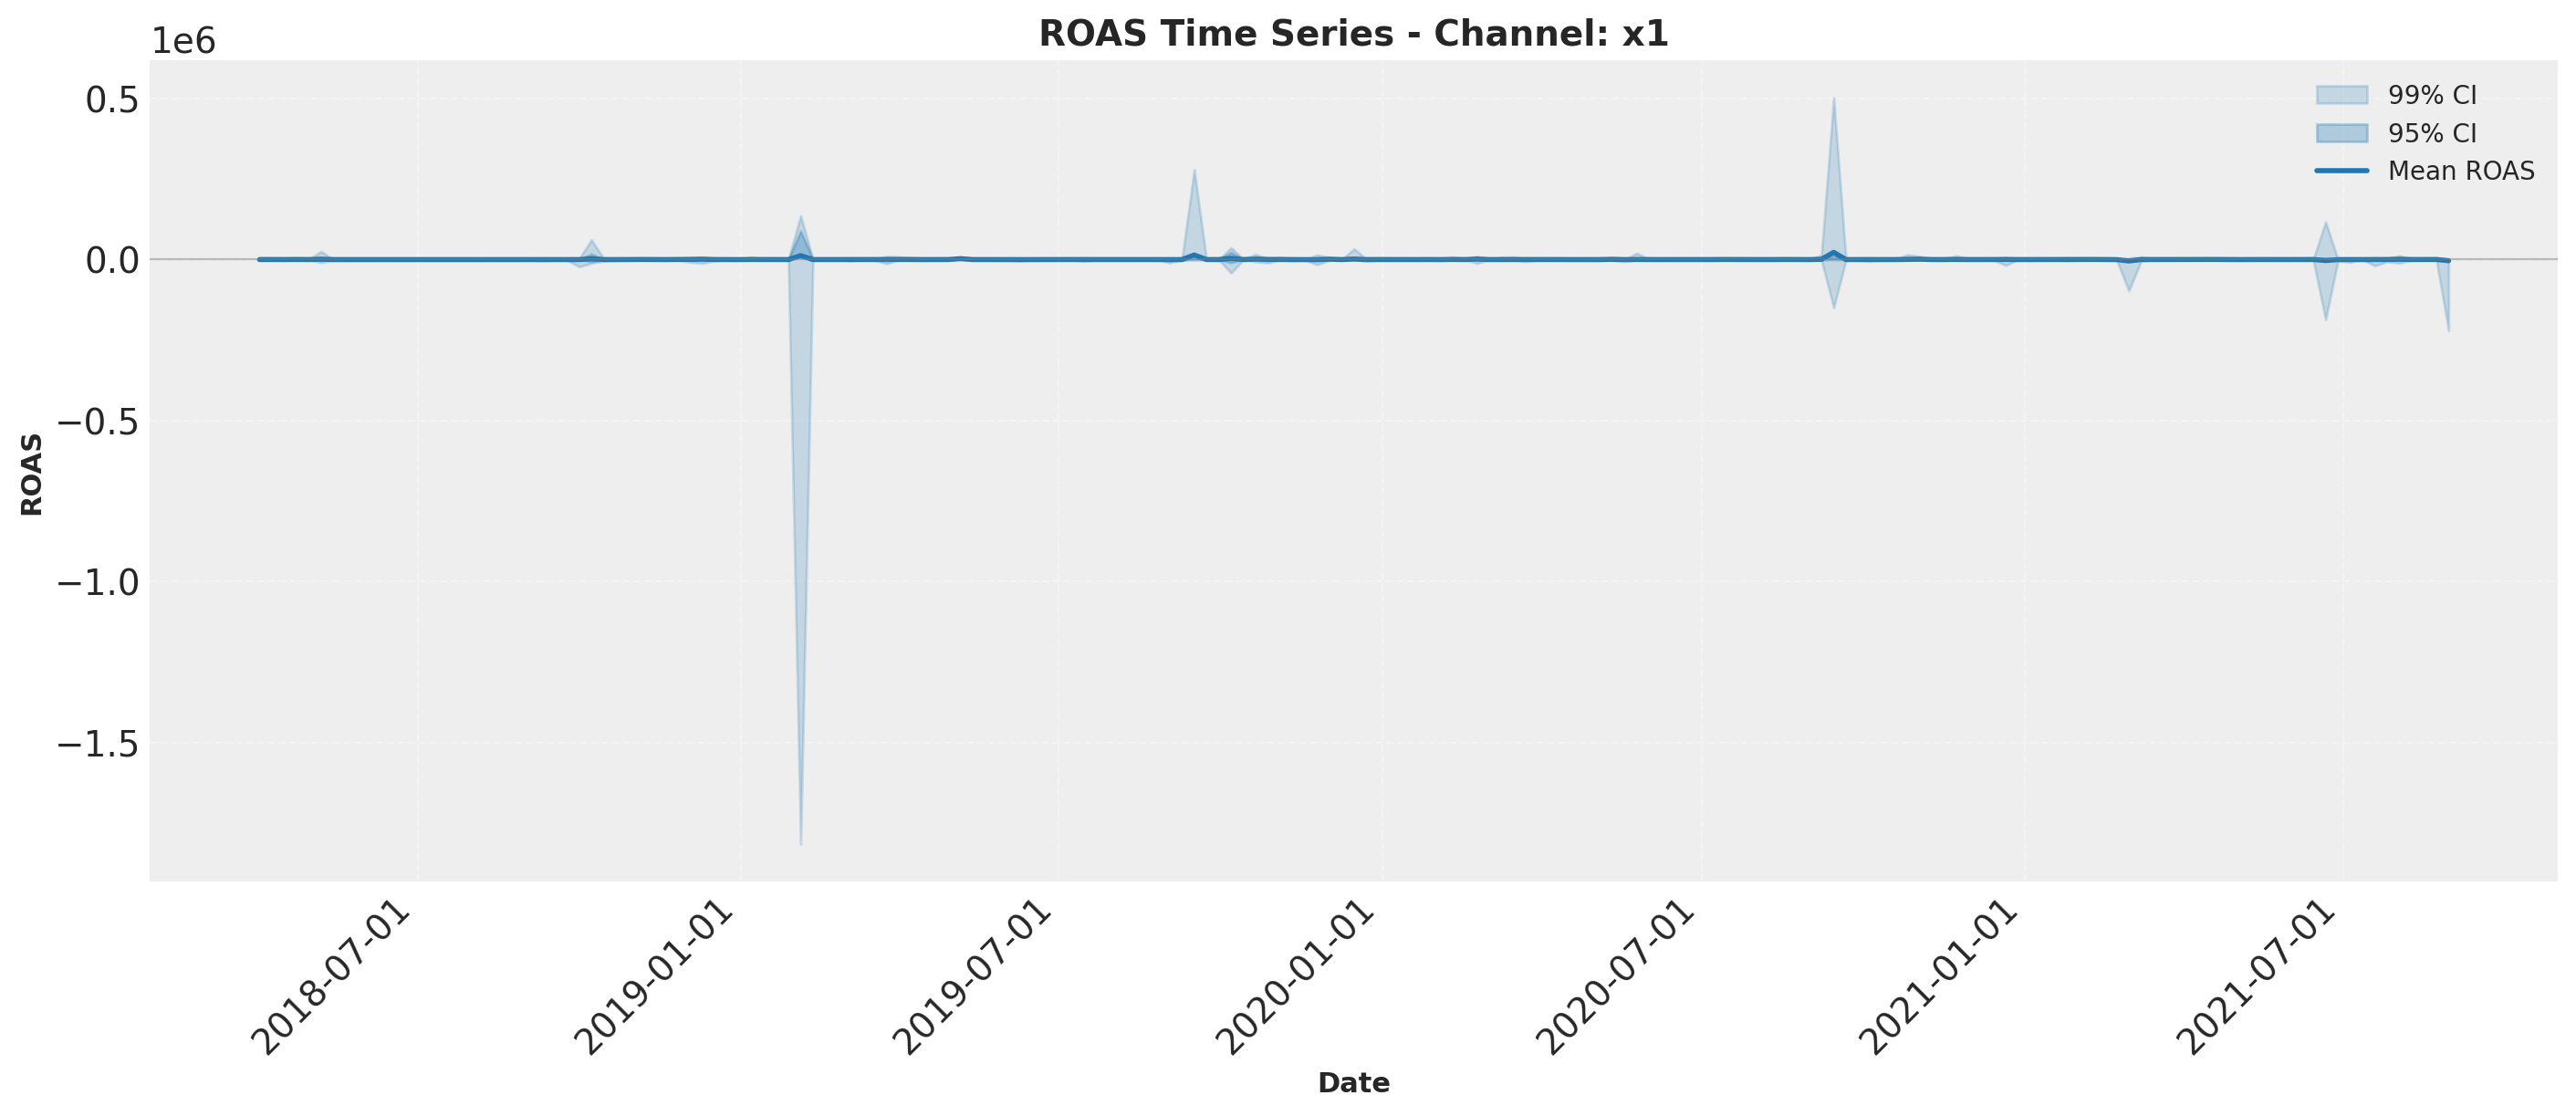

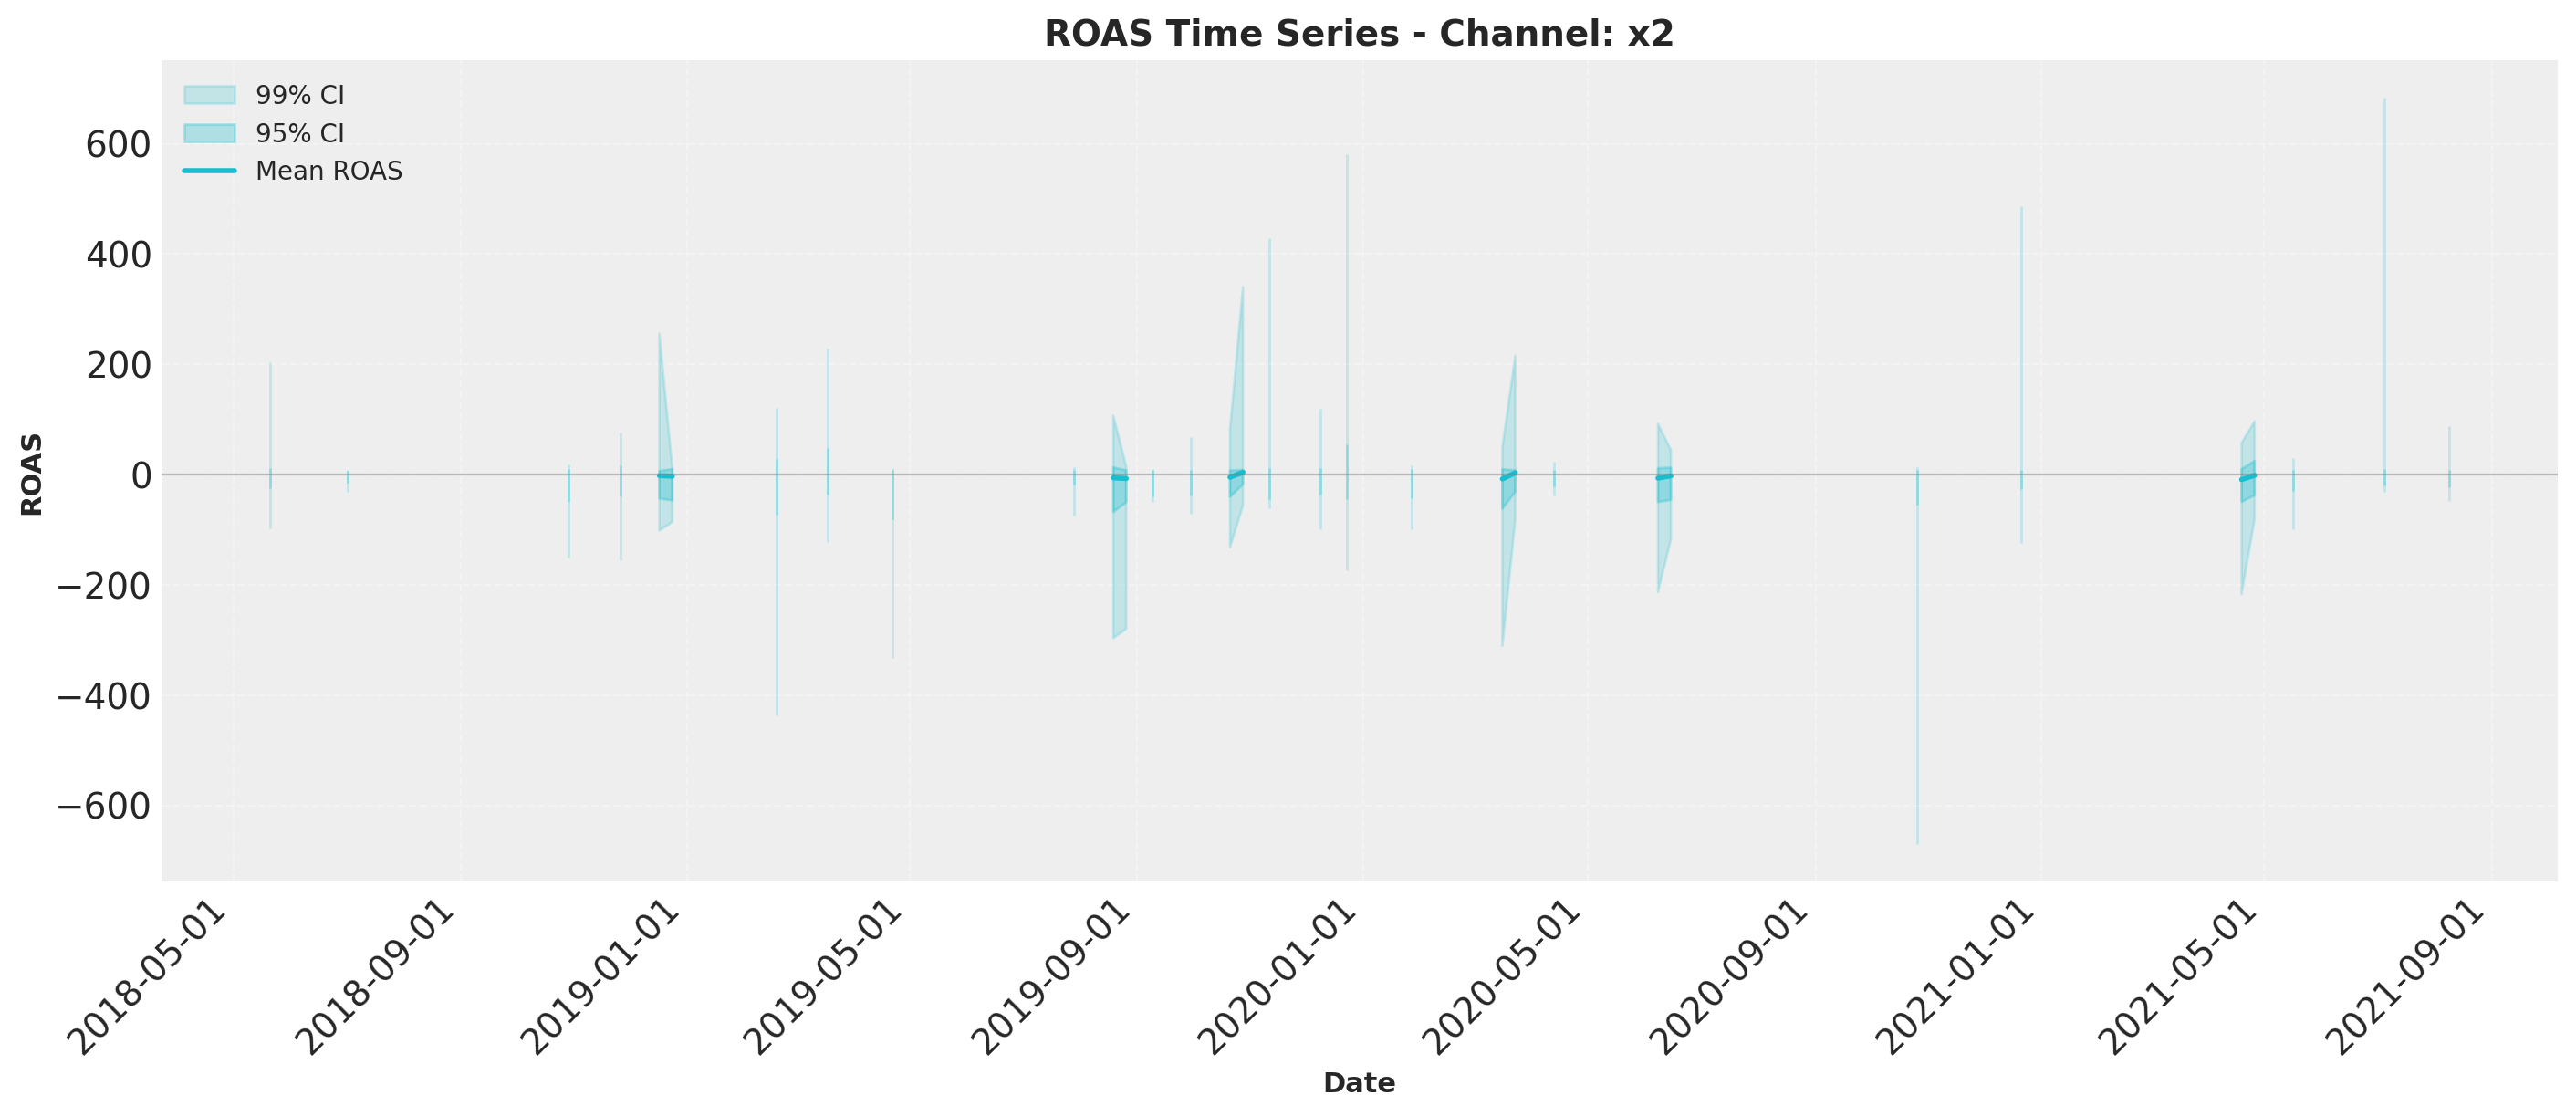


ROAS SUMMARY STATISTICS BY CHANNEL

x1:
  Overall Mean ROAS: 514.8254
  Overall Median ROAS: 150.3065
  Overall Std Dev: 31067.4979
  Overall 95% CI: [32.3675, 2613.0371]
  Min Mean ROAS (across periods): -4221.6416
  Max Mean ROAS (across periods): 22610.7872

x2:
  Overall Mean ROAS: -2.0820
  Overall Median ROAS: 0.6960
  Overall Std Dev: 70.2155
  Overall 95% CI: [-41.8331, 10.7560]
  Min Mean ROAS (across periods): -16.3272
  Max Mean ROAS (across periods): 10.2930


C:\Users\David Rodriguez\AppData\Local\Temp\ipykernel_29652\2334227774.py:74: RuntimeWarning: Mean of empty slice
  mean_roas_per_period = np.nanmean(roas_samples, axis=0)


In [41]:
# =============================================================================
# TEST: ROAS Time Series Calculation and Visualization
# =============================================================================

# Step 1: Calculate ROAS time series with all posterior samples
print("Calculating ROAS time series with uncertainty...")
roas_ts_results = calculate_roas_time_series(
    contributions=contributions,
    data=data,
    channel_cols=['x1', 'x2'],
    target_column='y'
)

# Step 2: Inspect the results structure
print("\n" + "="*80)
print("ROAS TIME SERIES RESULTS STRUCTURE")
print("="*80)
print(f"\nChannels processed: {roas_ts_results['channel_cols']}")
print(f"Number of dates: {len(roas_ts_results['dates'])}")
print(f"Date range: {roas_ts_results['dates'][0]} to {roas_ts_results['dates'][-1]}")

for channel in roas_ts_results['channel_cols']:
    roas_samples = roas_ts_results['roas_time_series'][channel]
    print(f"\n{channel}:")
    print(f"  ROAS array shape: {roas_samples.shape} (n_samples, n_dates)")
    print(f"  Number of posterior samples: {roas_samples.shape[0]}")
    print(f"  Mean ROAS (over all periods): {np.nanmean(roas_samples):.4f}")
    print(f"  Total spend: {roas_ts_results['spend'][channel].sum():.2f}")

# Step 3: Visualize ROAS time series
print("\n" + "="*80)
print("GENERATING PLOTS...")
print("="*80)

# Example 1: Using default confidence levels (95%, 99%)
plot_results = plot_roas_time_series(
    roas_results=roas_ts_results,
    confidence_levels=(0.95, 0.99),
    show_mean_line=True,
    date_range=None,  # Show all dates
    figsize=(14, 6)
)

# Example 2: Using custom confidence levels (90%, 95%)
# plot_results = plot_roas_time_series(
#     roas_results=roas_ts_results,
#     confidence_levels=(0.90, 0.95),
#     show_mean_line=True,
#     date_range=None,
#     figsize=(14, 6)
# )

# # Example 3: Using date range filter
# plot_results = plot_roas_time_series(
#     roas_results=roas_ts_results,
#     confidence_levels=(0.90, 0.95),
#     show_mean_line=True,
#     date_range=(pd.Timestamp('2021-02-01'), pd.Timestamp('2021-07-30')),
#     figsize=(14, 6)
# )

# Display the plots
plt.show()

# Step 4: Print some summary statistics
print("\n" + "="*80)
print("ROAS SUMMARY STATISTICS BY CHANNEL")
print("="*80)

for channel in roas_ts_results['channel_cols']:
    roas_samples = roas_ts_results['roas_time_series'][channel]
    
    # Calculate mean ROAS per time period
    mean_roas_per_period = np.nanmean(roas_samples, axis=0)
    
    # Calculate overall statistics
    overall_mean = np.nanmean(roas_samples)
    overall_median = np.nanmedian(roas_samples)
    overall_std = np.nanstd(roas_samples)
    
    # Calculate 95% CI for overall ROAS
    ci_95_lower = np.nanpercentile(roas_samples, 2.5)
    ci_95_upper = np.nanpercentile(roas_samples, 97.5)
    
    print(f"\n{channel}:")
    print(f"  Overall Mean ROAS: {overall_mean:.4f}")
    print(f"  Overall Median ROAS: {overall_median:.4f}")
    print(f"  Overall Std Dev: {overall_std:.4f}")
    print(f"  Overall 95% CI: [{ci_95_lower:.4f}, {ci_95_upper:.4f}]")
    print(f"  Min Mean ROAS (across periods): {np.nanmin(mean_roas_per_period):.4f}")
    print(f"  Max Mean ROAS (across periods): {np.nanmax(mean_roas_per_period):.4f}")

**Business usecase**

*Pros*

- Trend analysis: "Is our ROAS improving or declining over time in a specific channel?"
- Seasonality detection: "When during the year does this channel perform best?"
- Tactical optimization: "Should we increase spend this week in this channel based on recent ROAS?"
- Event impact analysis: "Did the campaign launch improved ROAS?"

*Limitations*

- More complex to explain to stakeholders
- Individual period ROAS can be noisy
- Requires more sophisticated visualization
- May show high variance in low-spend periods
